# Trabalho Final — Pipeline do Ciclo de Ciência de Dados
**Disciplina:** Ciência de Dados  
**Professora:** Trícia Santos Souto  
**Equipe:** Lavínia Souza Caló de Figueiredo, Lucas Luige Costa Miranda e Sara Raquel Pinto Brandão Silva  
**Base de Dados:** Stack Overflow Developer Survey, **edição 2025** (módulo de IA e AI Agents). Resultados e dados públicos: <https://survey.stackoverflow.co/2025>  
**Tema:** Determinantes e Preditores da Adoção de Agentes de Inteligência Artificial por Desenvolvedores Profissionais  
**Entrega atual:** Fases 0 a 12 — Bloco A revisado (Fases 0 a 5) e Bloco B (Fases 6 a 12: formulação, particionamento, preparação, ausentes, desbalanceamento, modelagem, comparação estatística e avaliação final no teste)  

> **Nota sobre a Revisão da Etapa 1 (Pós-Apresentação):**  
> A partir dos apontamentos recebidos na primeira etapa e visando preparar a base para modelagem preditiva robusta, realizamos **5 aprimoramentos concretos** no Bloco A em relação à entrega anterior:  
> 1. **Unificação do Alvo (Caminho A):** Todas as hipóteses convergem para o único desfecho supervisionado (`AIAgents_bin`), eliminando alvos concorrentes.  
> 2. **Prevenção Estrita de Vazamento (*Target Leakage*):** Isolamento preventivo de `AISelect` (tautologia direta) e, no Bloco B (Fase 7), reestimação de todo o pré-processamento que aprende com os dados (cercas de outlier, imputação isBAD, padronização e *target encoding*) exclusivamente no treino, via `Pipeline` do scikit-learn.  
> 3. **Incorporação de Tamanho de Efeito na Fase 3:** Em amostras grandes ($N >$ 24 mil), o $p$-valor tende a $0$ facilmente; adicionamos o $V$ de Cramér (categóricas) e a correlação *rank-biserial* (contínuas), com um gráfico de ranqueamento prático para distinguir associações fortes de fracas.  
> 4. **Verificação da Direção das Hipóteses:** Os testes Qui-Quadrado e Mann-Whitney bilaterais só indicam *se* há associação; passamos a verificar programaticamente se o *sentido* observado é o previsto em cada hipótese direcional, e o quadro final de hipóteses é gerado a partir desses resultados.  
> 5. **Diagnóstico de Forma Funcional (LOESS — Fase 5):** Curvas de suavização local nos preditores contínuos sobreviventes (`JobSat` e `YearsCode`), usadas para avaliar linearidade/monotonicidade antes da escolha dos modelos do Bloco B.  
>
> **Revisão a partir dos comentários da Etapa 1 (novembro/2026):**  
> 6. **Remuneração implausível (Fase 1):** piso de domínio de US$ 1.000/ano; valores abaixo dele (como US$ 1) viram NA.  
> 7. **Efeito do Z-score (Fase 2):** explicação de como a escala domina distâncias (KNN, K-Means) e penalizações (Ridge/Lasso).  
> 8. **H3 como possível tautologia (Fase 3):** cruzamento da ausência de `AIAcc`/`AIComplex` e da categoria "I don't use AI tools for complex tasks" com o rótulo.  
> 9. **Candidatas fora de H1–H6 (Fase 3):** `Age`, `EdLevel`, `Employment`, `Country`, `Industry`, `AIThreat`, `AISent` e remuneração passam a ser testadas, com tamanho de efeito, e registradas no Quadro de Descarte.  
> 10. **Fechamento da Fase 5:** curvas também para remuneração e `WorkExp`, segundo modelo atualizado para CatBoost e ressalva de validade na H3.  
> 11. **Revisão do conjunto de preditores (Bloco B):** as 8 candidatas foram testadas por experimento (9 × 17 preditores, mesmas dobras e teste de Nadeau-Bengio) e saíram do conjunto; a categoria "I don't use AI tools for complex tasks" foi juntada ao nível neutro; a dependência do modelo em `AIAcc`/`AIComplex` foi medida e registrada como limitação.  
> 12. **Fase 11 completa:** busca de hiperparâmetros do CatBoost em duas etapas (PR-AUC e depois F1 com o limiar ajustado), com o gap treino–validação.  
> 13. **Fase 12:** comparação estatística no treino e avaliação única no conjunto de teste, com intervalos de confiança.  
> 14. **Edição da pesquisa corrigida para 2025** (versões anteriores citavam 2024; as perguntas sobre AI Agents e o total de 49.191 respostas são da edição 2025).  

---

## Pré-requisito: recorte de escopo do domínio (antes da Fase 0)

Antes do início do pipeline de auditoria (Fase 0 em diante), é aplicado **um único recorte de escopo de negócio**, não relacionado a problemas de qualidade de dados, NAs ou outliers: são mantidos apenas respondentes com `MainBranch == "I am a developer by profession"`. 

Esse filtro define a **população de estudo** (desenvolvedores profissionais, não estudantes, hobbistas ou ex-desenvolvedores, cujas respostas distorceriam sistematicamente perguntas de carreira e remuneração). Trata-se de uma decisão de design da pesquisa, tomada antes de qualquer análise de dados; por isso, não constitui o tipo de "descarte físico de linhas" que a Fase 0 proíbe. A partir deste ponto, a base recortada é tratada como a "base original" preservada intacta ao longo das Fases 0 e 1.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.nonparametric.smoothers_lowess import lowess
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.model_selection import cross_validate
from sklearn.metrics import (
    f1_score, precision_score, recall_score, accuracy_score,
    balanced_accuracy_score, classification_report, make_scorer
)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

RNG_SEED = 42
np.random.seed(RNG_SEED)

audit_trail = []

def registrar_auditoria(fase, variavel, status, justificativa):
    audit_trail.append({
        'Fase': fase,
        'Variável': variavel,
        'Status': status,
        'Justificativa': justificativa
    })

print("Ambiente configurado com sucesso. Semente fixa:", RNG_SEED)

Ambiente configurado com sucesso. Semente fixa: 42


## Fase 0: Inspeção Inicial e Formulação Condicional de Hipóteses (Pré-AED)

Nesta fase inicial, realizamos a leitura automatizada da base de dados sem alterações físicas, avaliamos a existência de desfecho para bifurcação do caminho analítico (Caminho A vs. Caminho B) e registramos as hipóteses causais do negócio.

### Passo 0.1: Raio-X de Metadados e Seleção Temática

Leitura automatizada do dicionário oficial (`survey_results_schema.csv`) e da base bruta, **sem nenhuma alteração física**: são apenas listados colunas, formatos e tipos.

In [2]:
schema = pd.read_csv("survey_results_schema.csv")
print("Dicionário oficial, total de perguntas/colunas documentadas:", len(schema))
schema.head(10)

Dicionário oficial, total de perguntas/colunas documentadas: 139


,qid,qname,question,type,sub,sq_id
0,QID18,TechEndorse_1,What attracts you to a technology or causes yo...,RO,AI integration or AI Agent capabilities,1.0
1,QID18,TechEndorse_2,What attracts you to a technology or causes yo...,RO,Easy-to-use API,2.0
2,QID18,TechEndorse_3,What attracts you to a technology or causes yo...,RO,Robust and complete API,3.0
3,QID18,TechEndorse_4,What attracts you to a technology or causes yo...,RO,Customizable and manageable codebase,4.0
4,QID18,TechEndorse_5,What attracts you to a technology or causes yo...,RO,Reputation for quality,5.0
5,QID18,TechEndorse_6,What attracts you to a technology or causes yo...,RO,Connected to an open-source project,6.0
6,QID18,TechEndorse_7,What attracts you to a technology or causes yo...,RO,Good brand and public image,7.0
7,QID18,TechEndorse_8,What attracts you to a technology or causes yo...,RO,Reliability and low latency,8.0
8,QID18,TechEndorse_9,What attracts you to a technology or causes yo...,RO,Costs are manageable,9.0
9,QID18,TechEndorse_13,What attracts you to a technology or causes yo...,RO,Other (please specify):,10.0


In [3]:
raw_header = pd.read_csv("survey_results_public.csv", nrows=0)
print("Total de colunas na base bruta:", len(raw_header.columns))

COLS = [
    "ResponseId", "MainBranch",
    "Age", "EdLevel", "Employment", "WorkExp", "YearsCode", "DevType", "OrgSize",
    "ICorPM", "RemoteWork", "Country", "Industry", "JobSat", "ConvertedCompYearly",
    "AIThreat", "AISelect", "AISent", "AIAcc", "AIComplex", "AIAgents", "SOVisitFreq"
]

df_raw = pd.read_csv("survey_results_public.csv", usecols=COLS, na_values=["NA"], low_memory=False)
print(f"Linhas na base bruta: {len(df_raw)}")

df = df_raw[df_raw["MainBranch"] == "I am a developer by profession"].drop(columns=["MainBranch"]).reset_index(drop=True)
print(f"Linhas após recorte de escopo (devs profissionais): {len(df)}")

CONTINUOUS = ["WorkExp", "YearsCode", "JobSat", "ConvertedCompYearly"]
for c in CONTINUOUS:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print("\nTipos de dados (Raio-X pós seleção de colunas de resposta única):")
df.dtypes.to_frame('Tipo de Dado')

Total de colunas na base bruta: 172


Linhas na base bruta: 49191
Linhas após recorte de escopo (devs profissionais): 37467

Tipos de dados (Raio-X pós seleção de colunas de resposta única):


,Tipo de Dado
ResponseId,int64
Age,str
EdLevel,str
Employment,str
WorkExp,float64
YearsCode,float64
DevType,str
OrgSize,str
ICorPM,str
RemoteWork,str


**Colunas descartadas do pipeline (Fase 0, critério de dados administrativos/controle):**

- `ResponseId` é mantida apenas como **identificador de linha** (chave sequencial de controle); não é utilizada como preditor em nenhuma etapa estatística ou de modelagem a partir daqui. É o único caso análogo a "ID de controle" citado no roteiro. Nenhuma outra coluna do subconjunto é 100% constante ou puramente administrativa.
- As demais **151 colunas da base bruta (de 172)** já haviam sido descartadas na definição do escopo do trabalho: a grande maioria é composta por perguntas de múltipla escolha ("selecione todas que se aplicam") ou de rankings compostos (valores separados por `;`), fora do escopo desta análise de variáveis de resposta única.

### Passo 0.2: O Teste do Rótulo e Decisão de Caminho

Avaliamos se a base possui uma variável representativa de desfecho do negócio para bifurcar formalmente o percurso metodológico:
- **Caminho A (Supervisionado):** Existência de alvo preditivo bem discriminado.
- **Caminho B (Não Supervisionado):** Ausência de alvo (foco em agrupamento e mapeamento geométrico).

In [4]:
def binarizar_ai_agents(val):
    if pd.isna(val):
        return np.nan
    adotantes = {
        "Yes, I use AI agents at work daily",
        "Yes, I use AI agents at work weekly",
        "Yes, I use AI agents at work monthly or infrequently"
    }
    nao_adotantes = {
        "No, and I don't plan to",
        "No, I use AI exclusively in copilot/autocomplete mode",
        "No, but I plan to"
    }
    if val in adotantes:
        return 1.0
    if val in nao_adotantes:
        return 0.0
    return np.nan

df["AIAgents_bin"] = df["AIAgents"].apply(binarizar_ai_agents)

print("Distribuição de respostas no alvo original (AIAgents):")
print(df["AIAgents"].value_counts(dropna=False))
print("\nDistribuição do alvo binário na base de estudo (incluindo ausentes de resposta):")
print(df["AIAgents_bin"].value_counts(dropna=False))
pct_na_alvo = df["AIAgents_bin"].isna().mean() * 100
print(f"\nProporção de ausência no alvo original: {pct_na_alvo:.2f}%")

Distribuição de respostas no alvo original (AIAgents):
AIAgents
NaN                                                      12684
No, and I don't plan to                                   9091
No, but I plan to                                         4272
Yes, I use AI agents at work daily                        3692
No, I use AI exclusively in copilot/autocomplete mode     3524
Yes, I use AI agents at work weekly                       2289
Yes, I use AI agents at work monthly or infrequently      1915
Name: count, dtype: int64

Distribuição do alvo binário na base de estudo (incluindo ausentes de resposta):
AIAgents_bin
0.0    16887
NaN    12684
1.0     7896
Name: count, dtype: int64

Proporção de ausência no alvo original: 33.85%


**Decisão Formal: Caminho A (Aprendizado Supervisionado).**

A variável `AIAgents` ("uso de agentes autônomos de IA no fluxo de trabalho") constitui o tema central desta edição da pesquisa e possui valor direto de negócio: prever prontidão e adoção de agentes de IA para direcionamento de treinamento e produtos corporativos.

Mapeamos as respostas originais em um alvo binário (`AIAgents_bin`):
- **Classe 1 (Adotante):** Desenvolvedores que utilizam agentes de IA diariamente, semanalmente ou mensalmente no trabalho.
- **Classe 0 (Não Adotante):** Desenvolvedores que não utilizam (nem planejam), planejam usar ou utilizam IA exclusivamente em modo copiloto/autocomplete.

**Tratamento da Ausência no Rótulo:**  
Cerca de 33,9% dos desenvolvedores profissionais (32,7% após a remoção de linhas da Fase 1) pularam o bloco temático de agentes de IA (pesquisa paginada opcional). Em aprendizado supervisionado, **não se deve imputar valores sintéticos na variável-alvo** (isso geraria contaminação e rótulos artificiais). Portanto, as linhas sem rótulo representam a partição não-rotulada, sendo isoladas da esteira supervisionada na entrada da Fase 3 e modelagem.

### Passo 0.3: Guia de Hipóteses Formais e Prevenção de Vazamento Prematuro

Formulamos 6 hipóteses causais formais ($X \to Y$), com $Y = \text{AIAgents\_bin}$, amparadas no domínio do negócio:

| ID | Hipótese Inicial | Preditores ($X$) | Teste Estatístico (Fase 3) | Justificativa de Negócio |
|---|---|---|---|---|
| **H1** | Desenvolvedores mais experientes (maior `WorkExp` / `YearsCode`) apresentam **menor** probabilidade de uso de agentes de IA, refletindo adoção mais cautelosa e menor necessidade percebida em comparação a devs juniores. | `WorkExp`, `YearsCode` (contínuas) | Mann-Whitney + *rank-biserial* | Desenvolvedores mais experientes possuem fluxos consolidados e maior cautela em relação a ferramentas geradoras de código. |
| **H2** | O uso de agentes de IA está associado ao cargo/função (`DevType`) e ao tamanho da empresa (`OrgSize`), com maior adoção esperada em funções mais técnicas e empresas maiores/mais estruturadas. | `DevType`, `OrgSize` (categóricas) | Qui-Quadrado + V de Cramér | Papéis especializados e empresas maiores possuem mais estrutura ou incentivo para testes com agentes. |
| **H3** | Maior confiança na precisão da IA (`AIAcc`) e melhor percepção de desempenho em tarefas complexas (`AIComplex`) associam-se a **maior** probabilidade de uso de agentes de IA. | `AIAcc`, `AIComplex` (ordinais) | Qui-Quadrado + V de Cramér | A confiança nas saídas do agente é pré-requisito comportamental para delegar tarefas autônomas. |
| **H4** | A satisfação no cargo (`JobSat`) está associada ao uso de agentes de IA (hipótese de produtividade percebida). | `JobSat` (contínua) | Mann-Whitney + *rank-biserial* | Desenvolvedores que adotam ferramentas autônomas relatam alívio de tarefas repetitivas, impactando a satisfação. |
| **H5** | O modelo de trabalho (`RemoteWork`) e o papel (`ICorPM`) estão associados à adoção, sob a hipótese de que trabalho remoto e contribuidores individuais adotam mais (uso mais autônomo de ferramentas). | `RemoteWork`, `ICorPM` (categóricas) | Qui-Quadrado + V de Cramér | Profissionais em regime remoto e contribuidores individuais têm maior autonomia para experimentar ferramentas. |
| **H6** | Maior frequência de visita ao Stack Overflow (`SOVisitFreq`) associa-se a **menor** uso de agentes de IA, com a comunidade tradicional funcionando como substituto parcial. | `SOVisitFreq` (ordinal) | Qui-Quadrado + V de Cramér | Comunidades tradicionais de Q&A funcionam como substitutas parciais da assistência direta por IA. |

**Critério de descarte de hipóteses aplicado neste ponto:** nenhuma das hipóteses acima depende de preditor ausente da base ou de proxy excessivamente fraca; todas as variáveis citadas existem no subconjunto de 20 colunas selecionado.

**Exploração secundária (fora do escopo formal de H1 a H6):** `Age`, `EdLevel`, `Employment`, `Country`, `Industry`, `AIThreat`, `AISent` e `ConvertedCompYearly` não entram nas hipóteses formais, mas também são testadas contra o alvo na Fase 3, com tamanho de efeito, e o destino de cada uma fica registrado no Quadro de Descarte. *(Revisão pós-Etapa 1: na versão anterior, essas variáveis eram condicionadas e codificadas nas Fases 1 e 2 e depois saíam do conjunto sem teste nem registro.)*

**Descarte por redundância/vazamento (leakage):** `AISelect` ("uso de ferramentas de IA no desenvolvimento") é descartada do conjunto de preditores. Embora não seja idêntica ao rótulo, é uma proxy quase direta: "usar ferramentas de IA" é quase uma pré-condição de "usar agentes de IA", o que tornaria qualquer associação estatisticamente óbvia e pouco informativa (tautologia), violando a diretriz de evitar obviedades estatísticas.

**Mesmo cuidado aplicado à H3 (revisão pós-Etapa 1):** `AIAcc` (confiança na precisão da IA) e `AIComplex` (avaliação da IA em tarefas complexas) são percepções que podem ser **consequência** do uso de agentes, e não causa: quem usa passa a avaliar a ferramenta (causalidade reversa). Além disso, o nível `AIComplex = "I don't use AI tools for complex tasks / I don't know"` praticamente descreve o não uso. Ao contrário de `AISelect`, essas variáveis não são descartadas de antemão: a Fase 3 investiga o risco de tautologia, e o Bloco B compara modelos com e sem as variáveis de percepção (análise de sensibilidade).

**Descarte de Atributo Administrativo:**  
`ResponseId` é mantido apenas como chave sequencial de auditoria, sendo excluído da modelagem preditiva.

In [5]:
df_outcomes = df[["ResponseId", "AIAgents", "AISelect", "AIAgents_bin"]].copy()

registrar_auditoria("Fase 0", "AISelect", "Descartada (preditor)",
                    "Proxy quase direta do alvo (vazamento/tautologia). Guardada em df_outcomes.")
registrar_auditoria("Fase 0", "ResponseId", "Mantida (não-preditora)",
                    "Chave primária sequencial de controle operacional, sem poder explicativo.")

df = df.drop(columns=["AISelect"])
CATEGORICAL = [c for c in df.columns if c not in CONTINUOUS + ["ResponseId", "AIAgents", "AIAgents_bin"]]
print("Preditores categóricos remanescentes:", CATEGORICAL)

Preditores categóricos remanescentes: ['Age', 'EdLevel', 'Employment', 'DevType', 'OrgSize', 'ICorPM', 'RemoteWork', 'Industry', 'AIThreat', 'Country', 'SOVisitFreq', 'AISent', 'AIAcc', 'AIComplex']


## Fase 1: Análise Univariada e Condicionamento de Dados (Data Conditioning)

Nesta fase: (1) a normalidade é testada formalmente com Shapiro-Wilk; (2) inconsistências físicas são convertidas em NA e outliers extremos são isolados e também convertidos em NA; (3) todos os NAs (originais e gerados por outliers) são tratados cientificamente pelo método **isBAD**, sem nenhum descarte ingênuo de linhas (`complete cases`).

### Normalidade (Shapiro-Wilk)

O teste de Shapiro-Wilk é recomendado para amostras de até ~5.000 observações (acima disso a estatística fica pouco sensível e o p-valor tende a rejeitar quase qualquer desvio mínimo da normalidade). Por isso o teste é executado em uma amostra aleatória de até 5.000 observações por variável (`random_state=42`, reprodutível), acompanhado de gráficos de densidade sobre a distribuição completa.

In [6]:
def shapiro_sample(s, n=5000, seed=RNG_SEED):
    s = s.dropna()
    if len(s) > n:
        s = s.sample(n, random_state=seed)
    stat, p = stats.shapiro(s)
    return pd.Series({"n_testado": len(s), "estatistica_W": round(stat, 4), "p_valor": p,
                       "eh_normal_alpha_0.05": "Sim" if p >= 0.05 else "Não"})

shapiro_report = pd.DataFrame({c: shapiro_sample(df[c]) for c in CONTINUOUS}).T
shapiro_report

,n_testado,estatistica_W,p_valor,eh_normal_alpha_0.05
WorkExp,5000,0.8778,0.0,Não
YearsCode,5000,0.9225,0.0,Não
JobSat,5000,0.9116,0.0,Não
ConvertedCompYearly,5000,0.1212,0.0,Não


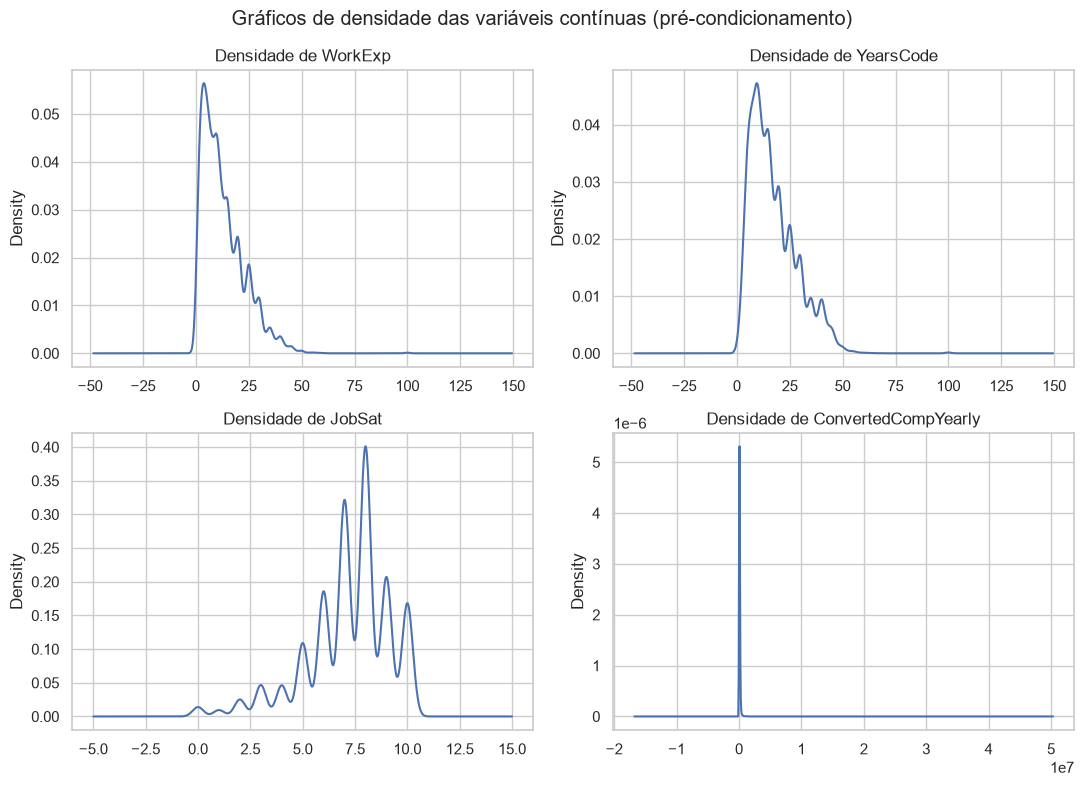

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, c in zip(axes.flat, CONTINUOUS):
    df[c].dropna().plot(kind="density", ax=ax, color="#4C72B0")
    ax.set_title(f"Densidade de {c}")
plt.suptitle("Gráficos de densidade das variáveis contínuas (pré-condicionamento)")
plt.tight_layout()
plt.show()

**H0 rejeitada (p < 0.05) para as 4 variáveis contínuas.** Nenhuma segue distribuição normal de Gauss, o que confirma, já na Fase 1, que os testes bivariados da Fase 3 devem ser **não-paramétricos baseados em postos** (Wilcoxon/Mann-Whitney), conforme já antecipado nas hipóteses H1 e H4 da Fase 0.

### Inconsistências físicas e outliers extremos

Primeiramente, é convertido em NA qualquer valor que viole regras físicas do domínio (idade/experiência/remuneração negativas, `JobSat` fora da escala de 0 a 10 da pesquisa). Para a remuneração, aplica-se também um **limite mínimo de domínio**: valores abaixo de **US$ 1.000 por ano** (a base chega a ter US$ 1) não são plausíveis para um desenvolvedor profissional e também viram NA. Em seguida, outliers de medição extremos são isolados via IQR (limiar de 3×IQR, seguindo a convenção de "outlier extremo" de Tukey, mais conservadora que o 1,5×IQR de "outlier comum", de modo a não descartar informação demais em variáveis já sabidamente assimétricas) e também convertidos em NA, a serem tratados no mesmo pipeline isBAD.

In [8]:
invalid_mask = pd.DataFrame({
    "WorkExp": df["WorkExp"] < 0,
    "YearsCode": df["YearsCode"] < 0,
    "JobSat": (df["JobSat"] < 0) | (df["JobSat"] > 10),
    "ConvertedCompYearly": df["ConvertedCompYearly"] <= 0,
})

for c in CONTINUOUS:
    n_flag = invalid_mask[c].sum()
    df.loc[invalid_mask[c], c] = np.nan
    print(f"{c}: {n_flag} valores fisicamente inválidos convertidos em NA")

# Limite mínimo de domínio da remuneração: abaixo de US$ 1.000/ano o valor não é plausível
# (ex.: US$ 1/ano). É uma regra fixa do domínio, não aprendida com os dados.
COMP_MIN_DOMINIO = 1000
comp_obs = df["ConvertedCompYearly"].notna().sum()
abaixo_piso = df["ConvertedCompYearly"] < COMP_MIN_DOMINIO
print(f"\nConvertedCompYearly: mínimo observado = US$ {df['ConvertedCompYearly'].min():,.0f}; "
      f"{abaixo_piso.sum()} valores abaixo de US$ 1.000/ano "
      f"({abaixo_piso.sum() / comp_obs:.1%} dos observados) convertidos em NA")
df.loc[abaixo_piso, "ConvertedCompYearly"] = np.nan
registrar_auditoria("Fase 1", "ConvertedCompYearly", "Abaixo do piso de domínio -> NA",
                    f"{abaixo_piso.sum()} valores < US$ 1.000/ano (implausíveis) convertidos em NA.")

# Snapshot após as regras físicas determinísticas (nada aqui é aprendido com os dados).
# É a entrada do Pipeline do Bloco B (Fase 7): cercas de outlier, medianas, z-score e
# target encoding serão reestimados lá, somente no conjunto de treino.
df_pre_aprendizado = df.copy()

WorkExp: 0 valores fisicamente inválidos convertidos em NA
YearsCode: 0 valores fisicamente inválidos convertidos em NA
JobSat: 0 valores fisicamente inválidos convertidos em NA
ConvertedCompYearly: 0 valores fisicamente inválidos convertidos em NA

ConvertedCompYearly: mínimo observado = US$ 1; 469 valores abaixo de US$ 1.000/ano (2.3% dos observados) convertidos em NA


In [9]:
def extreme_outlier_mask(s, k=3.0):
    s_valid = s.dropna()
    q1, q3 = s_valid.quantile([.25, .75])
    iqr = q3 - q1
    low, high = q1 - k * iqr, q3 + k * iqr
    return (s < low) | (s > high), low, high

outlier_report_rows = []
for c in CONTINUOUS:
    mask, low, high = extreme_outlier_mask(df[c])
    mask = mask.fillna(False)
    qtd_outliers = int(mask.sum())
    outlier_report_rows.append({
        "variável": c, "limite_inf": round(low, 2), "limite_sup": round(high, 2),
        "n_outliers_extremos": qtd_outliers,
        "% da base": round(100 * qtd_outliers / len(df), 2),
    })
    df.loc[mask, c] = np.nan
    registrar_auditoria("Fase 1", c, "Outlier extremo -> NA",
                        f"{qtd_outliers} valores fora de [{low:.1f}, {high:.1f}] (3x IQR) convertidos em NA.")

outlier_report = pd.DataFrame(outlier_report_rows)
outlier_report

,variável,limite_inf,limite_sup,n_outliers_extremos,% da base
0,WorkExp,-37.00,61.00,18,0.05
1,YearsCode,-39.00,73.00,21,0.06
2,JobSat,0.00,14.00,0,0.00
3,ConvertedCompYearly,-195206.25,365752.75,296,0.79


### Tratamento científico de NAs pelo método `isBAD`

Regra aplicada por variável (conforme diretriz):
- **Taxa de ausência menor que 2%**: remoção física de linha é permitida (perda desprezível). Aplica-se a `Age` (0%), `EdLevel` (1,8%) e `Employment` (1,5%), as três únicas variáveis do subconjunto abaixo do limiar.
- **Taxa de ausência de 2% ou mais**: os dados são mantidos e condicionados. Categóricas recebem o nível literal `'missing'`. Numéricas recebem imputação pela **mediana** (mais robusta que a média, dado que nenhuma variável contínua é normal) e ganham uma coluna booleana indicadora `<var>_isBAD` (`True` = valor foi alterado; `False` = valor original preservado). Os NAs originais e os gerados pela etapa de outliers acima entram juntos nesse mesmo tratamento.

In [10]:
LOW_NULL_DROP = ["Age", "EdLevel", "Employment"]
n_antes_drop = len(df)
null_pct_low = {c: round(100 * df[c].isna().mean(), 2) for c in LOW_NULL_DROP}
print("% nulos nas variáveis candidatas à remoção de linha:", null_pct_low)

df = df.dropna(subset=LOW_NULL_DROP).reset_index(drop=True)
linhas_removidas = n_antes_drop - len(df)
registrar_auditoria("Fase 1", "Age/EdLevel/Employment (linhas)", f"{linhas_removidas} linhas removidas",
                    f"Remoção de casos com NAs em colunas de perda irrelevante (< 2%, total: {linhas_removidas/n_antes_drop:.2%}).")

print(f"\nLinhas antes: {n_antes_drop} | depois da remoção (<2% nulo): {len(df)} "
      f"({linhas_removidas} linhas removidas, {round(100*linhas_removidas/n_antes_drop, 2)}%)")

% nulos nas variáveis candidatas à remoção de linha: {'Age': np.float64(0.0), 'EdLevel': np.float64(1.76), 'Employment': np.float64(1.52)}

Linhas antes: 37467 | depois da remoção (<2% nulo): 36808 (659 linhas removidas, 1.76%)


In [11]:
isbad_report = []
for c in CONTINUOUS:
    pct_null = round(100 * df[c].isna().mean(), 2)
    median_val = df[c].median()
    df[f"{c}_isBAD"] = df[c].isna()
    df[c] = df[c].fillna(median_val)
    isbad_report.append({"variável": c, "% nulo tratado": pct_null,
                          "valor de imputação (mediana)": round(median_val, 2),
                          "n_isBAD": int(df[f'{c}_isBAD'].sum())})
    registrar_auditoria("Fase 1", c, f"isBAD (imputado {median_val:.1f})",
                        f"{pct_null}% nulos imputados pela mediana; coluna indicadora {c}_isBAD criada.")

pd.DataFrame(isbad_report)

,variável,% nulo tratado,valor de imputação (mediana),n_isBAD
0,WorkExp,5.24,10.0,1929
1,YearsCode,9.48,15.0,3489
2,JobSat,27.61,8.0,10162
3,ConvertedCompYearly,47.24,78890.0,17389


In [12]:
CATEGORICAL_MISSING = [c for c in CATEGORICAL if c not in LOW_NULL_DROP]
for c in CATEGORICAL_MISSING:
    qtd_miss = df[c].isna().sum()
    df[c] = df[c].fillna("missing")
    if qtd_miss > 0:
        registrar_auditoria("Fase 1", c, "Mantida (NAs tratados)",
                            f"{qtd_miss} valores ausentes convertidos para a categoria 'missing'.")

null_final = df.drop(columns=["ResponseId"]).isna().mean().sort_values(ascending=False)
print("Nulos remanescentes após condicionamento (deve ser 0 em tudo, exceto AIAgents/AIAgents_bin, o rótulo):")
null_final[null_final > 0]

Nulos remanescentes após condicionamento (deve ser 0 em tudo, exceto AIAgents/AIAgents_bin, o rótulo):


AIAgents        0.327483
AIAgents_bin    0.327483
dtype: float64

Os únicos nulos remanescentes são do **rótulo** (`AIAgents` / `AIAgents_bin`), propositalmente não imputados (ver justificativa na Fase 0, Passo 0.2). Todos os preditores encontram-se 100% condicionados, sem nenhuma linha descartada por causa de NAs além das permitidas pela regra dos 2%.

## Fase 2: Engenharia de Atributos (Feature Engineering)

São aplicadas transformações matemáticas nas numéricas e encodings nas categóricas, respeitando a cardinalidade de cada uma e a proibição de Target Encoding fora do Caminho A (não aplicável aqui, pois o trabalho segue o Caminho A).

### Transformações matemáticas

- **log10** em `ConvertedCompYearly` (dado monetário, altamente assimétrico mesmo após o tratamento de outliers extremos), gerando `ConvertedCompYearly_log`.
- **Z-score** em todas as numéricas (incluindo a versão log de remuneração): $z = (x - \bar{x}) / s$, de modo que todas passam a ter média 0 e desvio-padrão 1.

**Por que o Z-score importa.** Sem padronizar, a variável de maior escala domina o algoritmo:
- **Distância (KNN, K-Means):** a remuneração vai de US$ 1 mil a centenas de milhares de dólares, enquanto `JobSat` vai de 0 a 10. Numa distância euclidiana, uma diferença de US$ 10 mil pesa mil vezes mais que a escala inteira de satisfação, e quem é "vizinho" de quem passa a ser decidido quase só pela remuneração.
- **Penalização (Ridge/Lasso):** a penalidade incide sobre o tamanho dos coeficientes, que depende da unidade da variável. Uma variável em escala grande tem coeficiente pequeno e quase não é penalizada; uma em escala pequena tem coeficiente grande e é encolhida demais (ou zerada pelo Lasso). A penalização passa a refletir a unidade de medida, e não a importância da variável.

Com o Z-score, as variáveis competem em pé de igualdade. Já as **árvores** (escolhidas no Bloco B) dividem os dados por limiares em uma variável por vez, e uma mudança de escala não altera os cortes; isso foi confirmado na Fase 8 (F1 idêntico com e sem Z-score).

In [13]:
df["ConvertedCompYearly_log"] = np.log10(df["ConvertedCompYearly"])
registrar_auditoria("Fase 2", "ConvertedCompYearly", "Mantida (log10 + Z-Score)",
                    "Variável financeira de cauda longa altamente assimétrica; log10 aplicado antes da padronização.")

Z_SOURCE = ["WorkExp", "YearsCode", "JobSat", "ConvertedCompYearly_log"]
for c in Z_SOURCE:
    mu, sigma = df[c].mean(), df[c].std()
    df[f"{c}_z"] = (df[c] - mu) / sigma
    registrar_auditoria("Fase 2", c, "Mantida (Z-Score)",
                        f"Padronização Z-score calculada (média={mu:.2f}, dp={sigma:.2f}).")

df[[*Z_SOURCE, *[f"{c}_z" for c in Z_SOURCE]]].describe().round(4)

,WorkExp,YearsCode,JobSat,ConvertedCompYearly_log,WorkExp_z,YearsCode_z,JobSat_z,ConvertedCompYearly_log_z
count,36808.0000,36808.0000,36808.0000,36808.0000,36808.0000,36808.0000,36808.0000,36808.0000
mean,12.7318,17.0718,7.4230,4.8460,0.0000,-0.0000,0.0000,-0.0000
std,9.5735,10.3761,1.7354,0.3277,1.0000,1.0000,1.0000,1.0000
min,1.0000,1.0000,0.0000,3.0000,-1.2254,-1.5489,-4.2774,-5.6330
25%,5.0000,10.0000,7.0000,4.8751,-0.8076,-0.6815,-0.2437,0.0888
50%,10.0000,15.0000,8.0000,4.8970,-0.2854,-0.1997,0.3325,0.1558
75%,18.0000,23.0000,8.0000,4.9121,0.5503,0.5713,0.3325,0.2019
max,60.0000,68.0000,10.0000,5.5623,4.9374,4.9082,1.4850,2.1859


### Encodings

- **Dummy / One-Hot** para categóricas de baixa cardinalidade (até 10 categorias), com **descarte do primeiro nível de cada grupo** (`drop_first=True`). Essa escolha evita a "armadilha das dummies" (uma categoria é sempre a soma exata das demais do mesmo grupo, o que geraria VIF infinito na Fase 4).
- **Target Encoding com suavização m-estimate (Laplace smoothing)** para categóricas de alta cardinalidade (`DevType`, `Country`, `Industry`), onde One-Hot geraria centenas de colunas esparsas inviabilizando VIF e modelos parcimoniosos. A taxa de uso de agentes de IA em cada categoria é ponderada com a taxa média global ($m=10$), reduzindo o risco de overfitting em categorias raras.

> **Ressalva metodológica:** nas Fases 2 a 5 o *target encoding* (assim como medianas e z-scores) é ajustado uma única vez sobre toda a base rotulada, o que é aceitável para fins **exploratórios**. Para a modelagem (Bloco B), todos esses passos são refeitos dentro de um `Pipeline` ajustado apenas no treino, com *target encoding* por dobras (*cross-fitting*), conforme a Fase 7.

In [14]:
cardinality = {c: df[c].nunique() for c in CATEGORICAL}
LOW_CARD = [c for c, n in cardinality.items() if n <= 10]
HIGH_CARD = [c for c, n in cardinality.items() if n > 10]
print("Baixa cardinalidade (dummy):", LOW_CARD)
print("Alta cardinalidade (target encoding):", HIGH_CARD, {c: cardinality[c] for c in HIGH_CARD})

Baixa cardinalidade (dummy): ['Age', 'EdLevel', 'Employment', 'OrgSize', 'ICorPM', 'RemoteWork', 'AIThreat', 'SOVisitFreq', 'AISent', 'AIAcc', 'AIComplex']
Alta cardinalidade (target encoding): ['DevType', 'Industry', 'Country'] {'DevType': 33, 'Industry': 16, 'Country': 169}


In [15]:
df_dummies = pd.get_dummies(df[LOW_CARD], prefix=LOW_CARD, drop_first=True)
print("Colunas dummy geradas:", df_dummies.shape[1])
df = pd.concat([df, df_dummies], axis=1)
for c in LOW_CARD:
    registrar_auditoria("Fase 2", c, "Mantida (One-Hot)", "Baixa cardinalidade (<= 10 níveis); convertida em dummies com drop_first.")
df_dummies.columns.tolist()[:10]

Colunas dummy geradas: 61


['Age_25-34 years old',
 'Age_35-44 years old',
 'Age_45-54 years old',
 'Age_55-64 years old',
 'Age_65 years or older',
 'Age_Prefer not to say',
 'EdLevel_Bachelor’s degree (B.A., B.S., B.Eng., etc.)',
 'EdLevel_Master’s degree (M.A., M.S., M.Eng., MBA, etc.)',
 'EdLevel_Other (please specify):',
 'EdLevel_Primary/elementary school']

In [16]:
def target_encode(series, target, m=10):
    fit_mask = target.notna()
    global_mean = target[fit_mask].mean()
    agg = pd.DataFrame({"y": target[fit_mask], "x": series[fit_mask]}).groupby("x")["y"].agg(["mean", "count"])
    smooth = (agg["count"] * agg["mean"] + m * global_mean) / (agg["count"] + m)
    return series.map(smooth).fillna(global_mean), smooth, global_mean

target_encoding_maps = {}
for c in HIGH_CARD:
    encoded, mapping, global_mean = target_encode(df[c], df["AIAgents_bin"], m=10)
    df[f"{c}_target_enc"] = encoded
    target_encoding_maps[c] = mapping
    registrar_auditoria("Fase 2", c, "Mantida (Target Encoding)",
                        f"Alta cardinalidade ({cardinality[c]} níveis); codificada com Laplace smoothing (m=10).")
    print(f"{c}: {len(mapping)} categorias codificadas, média global de fallback = {round(global_mean, 4)}")

DevType: 32 categorias codificadas, média global de fallback = 0.3187


Industry: 16 categorias codificadas, média global de fallback = 0.3187
Country: 167 categorias codificadas, média global de fallback = 0.3187


In [17]:
print("Top 5 categorias de DevType por taxa suavizada de uso de agentes de IA:")
target_encoding_maps["DevType"].sort_values(ascending=False).head(5)

Top 5 categorias de DevType por taxa suavizada de uso de agentes de IA:


x
Developer, AI apps or physical AI       0.542965
Founder, technology or otherwise        0.477391
Project manager                         0.469159
AI/ML engineer                          0.467644
Senior executive (C-suite, VP, etc.)    0.457629
dtype: float64

### Estado da base ao final da Fase 2

A base encontra-se condicionada e com atributos projetados: todos os preditores estão sem valores ausentes (à exceção do rótulo, propositalmente preservado), as numéricas estão padronizadas e as categóricas codificadas. Está pronta, portanto, para a análise bivariada/multivariada.

In [18]:
print("Shape da base ao final da Fase 2:", df.shape)

Shape da base ao final da Fase 2: (36808, 94)


## Fase 3: Análise Bivariada / Multivariada (Foco em Descoberta e Validação)

O trabalho segue o **Caminho A**: é avaliado o poder preditivo individual de cada preditor de H1 a H6 contra o alvo `AIAgents_bin`, utilizando apenas o subconjunto **rotulado** (linhas com `AIAgents` não nulo, ver justificativa na Fase 0). Como nenhuma variável contínua é normal (Shapiro-Wilk, Fase 1), utiliza-se **Wilcoxon/Mann-Whitney** para contínua-vs-binária. Para categórica-vs-categórica, utiliza-se **Qui-Quadrado de independência** (com **V de Cramér** para força de associação); para os testes de Mann-Whitney, o tamanho de efeito é a correlação ***rank-biserial*** ($r$, de −1 a +1, positiva quando os adotantes têm valores maiores). São filtradas evidências com p < 0.05.

In [19]:
df_lab = df[df["AIAgents_bin"].notna()].copy()
df_lab["AIAgents_bin"] = df_lab["AIAgents_bin"].astype(int)
print("Base rotulada para os testes bivariados:", df_lab.shape)

Base rotulada para os testes bivariados: (24754, 94)


In [20]:
def cramers_v(contingencia):
    chi2 = stats.chi2_contingency(contingencia)[0]
    n = contingencia.to_numpy().sum()
    r, k = contingencia.shape
    phi2 = chi2 / n
    return np.sqrt(phi2 / min(r - 1, k - 1))

def rank_biserial(u, n1, n0):
    """Tamanho de efeito do Mann-Whitney: r = 2U/(n1*n0) - 1 (positivo => adotantes com valores maiores)."""
    return 2 * u / (n1 * n0) - 1

def mannwhitney_test(col):
    g1 = df_lab.loc[df_lab["AIAgents_bin"] == 1, col]
    g0 = df_lab.loc[df_lab["AIAgents_bin"] == 0, col]
    stat, p = stats.mannwhitneyu(g1, g0, alternative="two-sided")
    r = rank_biserial(stat, len(g1), len(g0))
    return {
        "variável": col, "teste": "Mann-Whitney U",
        "mediana_usa_agentes": round(g1.median(), 2), "mediana_nao_usa": round(g0.median(), 2),
        "estatística": round(stat, 1), "p_valor": p,
        "tamanho_efeito": f"r rank-biserial = {r:+.3f}",
        "forca_efeito": abs(r),
        "efeito_assinado": r,
    }

def chi2_test(col, top_n=15):
    s = df_lab[col]
    if s.nunique() > top_n:
        top = s.value_counts().nlargest(top_n).index
        s = s.where(s.isin(top), "Outros_agrupado")
    table = pd.crosstab(s, df_lab["AIAgents_bin"])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    v = cramers_v(table)
    return {
        "variável": col, "teste": "Qui-Quadrado", "n_categorias_testadas": table.shape[0],
        "estatística": round(chi2, 1), "p_valor": p,
        "tamanho_efeito": f"V de Cramér = {v:.3f}",
        "forca_efeito": v,
        "efeito_assinado": np.nan,
    }

HYPOTHESIS_TESTS = {
    "H1": [mannwhitney_test("WorkExp"), mannwhitney_test("YearsCode")],
    "H2": [chi2_test("DevType"), chi2_test("OrgSize")],
    "H3": [chi2_test("AIAcc"), chi2_test("AIComplex")],
    "H4": [mannwhitney_test("JobSat")],
    "H5": [chi2_test("RemoteWork"), chi2_test("ICorPM")],
    "H6": [chi2_test("SOVisitFreq")],
}

rows = []
for h, tests in HYPOTHESIS_TESTS.items():
    for t in tests:
        t = dict(t)
        t["hipótese"] = h
        t["significativo (p<0.05)"] = t["p_valor"] < 0.05
        rows.append(t)

bivariate_report = pd.DataFrame(rows)[
    ["hipótese", "variável", "teste", "estatística", "p_valor", "tamanho_efeito",
     "forca_efeito", "efeito_assinado", "significativo (p<0.05)"]
]
bivariate_report.drop(columns=["forca_efeito", "efeito_assinado"])

,hipótese,variável,teste,estatística,p_valor,tamanho_efeito,significativo (p<0.05)
0,H1,WorkExp,Mann-Whitney U,64854424.5,1.421806e-03,r rank-biserial = -0.025,True
1,H1,YearsCode,Mann-Whitney U,61988996.0,4.555230e-18,r rank-biserial = -0.068,True
2,H2,DevType,Qui-Quadrado,346.1,1.358468e-64,V de Cramér = 0.118,True
3,H2,OrgSize,Qui-Quadrado,43.6,1.642955e-06,V de Cramér = 0.042,True
4,H3,AIAcc,Qui-Quadrado,1748.5,0.000000e+00,V de Cramér = 0.266,True
5,H3,AIComplex,Qui-Quadrado,2819.4,0.000000e+00,V de Cramér = 0.337,True
6,H4,JobSat,Mann-Whitney U,69958538.0,2.263310e-11,r rank-biserial = +0.052,True
7,H5,RemoteWork,Qui-Quadrado,44.3,2.030992e-08,V de Cramér = 0.042,True
8,H5,ICorPM,Qui-Quadrado,141.1,2.337613e-31,V de Cramér = 0.075,True
9,H6,SOVisitFreq,Qui-Quadrado,390.1,3.152623e-80,V de Cramér = 0.126,True


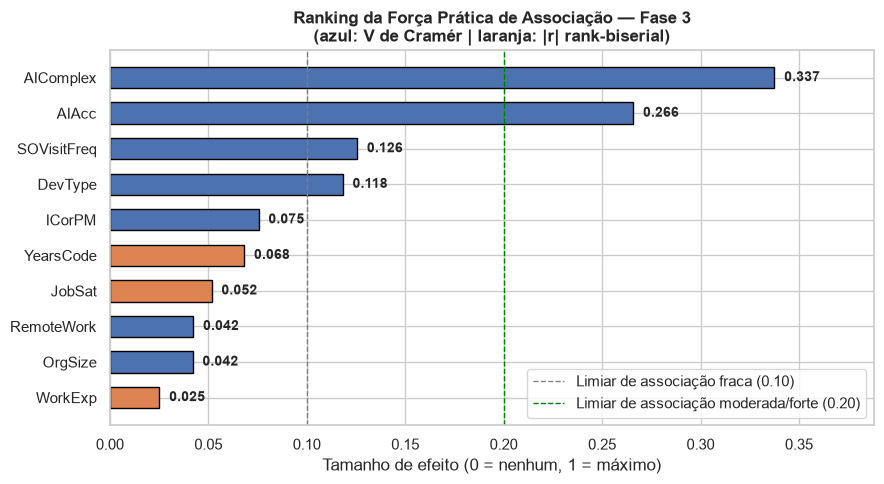

In [21]:
df_efeito = bivariate_report.sort_values("forca_efeito", ascending=True)
cores = ["#4C72B0" if t == "Qui-Quadrado" else "#DD8452" for t in df_efeito["teste"]]

plt.figure(figsize=(9, 5))
bars = plt.barh(df_efeito["variável"], df_efeito["forca_efeito"], color=cores, edgecolor="black", height=0.6)
plt.axvline(0.10, color="gray", linestyle="--", linewidth=1, label="Limiar de associação fraca (0.10)")
plt.axvline(0.20, color="green", linestyle="--", linewidth=1, label="Limiar de associação moderada/forte (0.20)")
plt.title("Ranking da Força Prática de Associação — Fase 3\n(azul: V de Cramér | laranja: |r| rank-biserial)",
          fontsize=12, fontweight="bold")
plt.xlabel("Tamanho de efeito (0 = nenhum, 1 = máximo)")
plt.legend(loc="lower right")
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.005, bar.get_y() + bar.get_height()/2, f"{w:.3f}", va="center", fontsize=10, fontweight="bold")
plt.xlim(0, max(df_efeito["forca_efeito"]) * 1.15)
plt.tight_layout()
plt.show()

### Filtro de evidências e descarte físico

Preditores com p ≥ 0.05 contra o alvo são descartados fisicamente do conjunto de preditores que avança para a Fase 4 (colinearidade). Apenas atributos estatisticamente significativos avançam.

In [22]:
SIGNIFICANT_PREDICTORS = bivariate_report.loc[bivariate_report["significativo (p<0.05)"], "variável"].tolist()
DROPPED_FASE3 = bivariate_report.loc[~bivariate_report["significativo (p<0.05)"], "variável"].tolist()
print("Preditores significativos (avançam para Fase 4):", SIGNIFICANT_PREDICTORS)
print("Preditores descartados (p >= 0.05):", DROPPED_FASE3)
significativos = SIGNIFICANT_PREDICTORS

Preditores significativos (avançam para Fase 4): ['WorkExp', 'YearsCode', 'DevType', 'OrgSize', 'AIAcc', 'AIComplex', 'JobSat', 'RemoteWork', 'ICorPM', 'SOVisitFreq']
Preditores descartados (p >= 0.05): []


### Diagnóstico de viés por subgrupo (cuidado indicado no roteiro)

Antes da aceitação de um preditor categórico como relevante, verifica-se se sua associação não decorre de um subgrupo minoritário disperso demais (contagem esperada muito baixa nalguma célula), o que infla o Qui-Quadrado artificialmente. É reportada a menor contagem esperada de cada teste categórico significativo; valores abaixo de 5 exigiriam agrupamento ou teste exato.

In [23]:
def min_expected_count(col, top_n=15):
    s = df_lab[col]
    if s.nunique() > top_n:
        top = s.value_counts().nlargest(top_n).index
        s = s.where(s.isin(top), "Outros_agrupado")
    table = pd.crosstab(s, df_lab["AIAgents_bin"])
    _, _, _, expected = stats.chi2_contingency(table)
    return expected.min()

cat_significant = [v for v in significativos if v in CATEGORICAL]
min_counts = {c: round(min_expected_count(c), 1) for c in cat_significant}
print("Menor contagem esperada por variável categórica significativa:")
pd.Series(min_counts, name="Min Expected Count").to_frame()

Menor contagem esperada por variável categórica significativa:


,Min Expected Count
DevType,85.1
OrgSize,124.6
AIAcc,33.5
AIComplex,28.7
RemoteWork,855.4
ICorPM,868.8
SOVisitFreq,156.5


**Leitura:** todas as menores contagens esperadas ficaram muito acima de 5 (mínimo de 28,7, em `AIComplex`). As premissas do Qui-Quadrado são atendidas, e o **teste exato de Fisher é dispensável**. O $V$ de Cramér acompanha o Qui-Quadrado como **medida de tamanho de efeito**, não como teste alternativo.

### Verificação da direção das hipóteses direcionais

Qui-Quadrado e Mann-Whitney bilateral só indicam se existe associação, não o sentido dela. Como H1, H2 (porte), H3, H5 e H6 preveem um **sentido**, ele é conferido explicitamente:

- **Contínuas:** sinal da correlação *rank-biserial* (positivo = adotantes com valores maiores).
- **Ordinais** (`OrgSize`, `AIAcc`, `AIComplex`, `SOVisitFreq`): correlação de Spearman entre a posição do nível na escala e o alvo (níveis fora da escala, como `'missing'` e "I don't know", são excluídos).
- **Contrastes nominais** (`RemoteWork`, `ICorPM`): diferença entre as taxas de adoção dos dois grupos citados na hipótese.

In [24]:
ORDINAL_LEVELS = {
    "OrgSize": ["Just me - I am a freelancer, sole proprietor, etc.", "Less than 20 employees",
                "20 to 99 employees", "100 to 499 employees", "500 to 999 employees",
                "1,000 to 4,999 employees", "5,000 to 9,999 employees", "10,000 or more employees"],
    "AIAcc": ["Highly distrust", "Somewhat distrust", "Neither trust nor distrust", "Somewhat trust", "Highly trust"],
    "AIComplex": ["Very poor at handling complex tasks", "Bad at handling complex tasks",
                  "Neither good or bad at handling complex tasks",
                  "Good, but not great at handling complex tasks", "Very well at handling complex tasks"],
    "SOVisitFreq": ["Infrequently, less than once per year", "Less than once every 2 - 3 months",
                    "Less than once per month or monthly", "A few times per month or weekly",
                    "A few times per week", "Daily or almost daily", "Multiple times per day"],
}
CONTRASTES = {  # (grupo que a hipótese prevê adotar mais, grupo de comparação)
    "RemoteWork": ("Remote", "In-person"),
    "ICorPM": ("Individual contributor", "People manager"),
}
# (hipótese, variável, sentido esperado da associação com a adoção)
DIRECTION_SPEC = [
    ("H1", "WorkExp", "-"), ("H1", "YearsCode", "-"),
    ("H2", "DevType", None), ("H2", "OrgSize", "+"),
    ("H3", "AIAcc", "+"), ("H3", "AIComplex", "+"),
    ("H4", "JobSat", None),
    ("H5", "RemoteWork", "+"), ("H5", "ICorPM", "+"),
    ("H6", "SOVisitFreq", "-"),
]

direcoes = []
for h, v, esperado in DIRECTION_SPEC:
    if v in CONTINUOUS:
        medida = "r rank-biserial"
        valor = bivariate_report.loc[bivariate_report["variável"] == v, "efeito_assinado"].iloc[0]
    elif v in ORDINAL_LEVELS:
        medida = "Spearman (nível ordinal x alvo)"
        codigo = df_lab[v].map({nivel: i for i, nivel in enumerate(ORDINAL_LEVELS[v])})
        ok = codigo.notna()
        valor = stats.spearmanr(codigo[ok], df_lab.loc[ok, "AIAgents_bin"]).statistic
    elif v in CONTRASTES:
        a, b = CONTRASTES[v]
        taxas = df_lab.groupby(v)["AIAgents_bin"].mean()
        medida = f"taxa({a}) − taxa({b})"
        valor = taxas[a] - taxas[b]
    else:
        medida, valor = "—", np.nan
    if esperado is None:
        confirmado = "N.A."
    else:
        confirmado = "Sim" if np.sign(valor) == (1 if esperado == "+" else -1) else "Não"
    direcoes.append({
        "hipótese": h, "variável": v, "medida de direção": medida,
        "valor observado": round(valor, 3) if pd.notna(valor) else np.nan,
        "sentido esperado": {"+": "positivo (mais uso)", "-": "negativo (menos uso)", None: "não direcional"}[esperado],
        "sentido confirmado": confirmado,
    })

direction_report = pd.DataFrame(direcoes)
direction_report

,hipótese,variável,medida de direção,valor observado,sentido esperado,sentido confirmado
0,H1,WorkExp,r rank-biserial,-0.025,negativo (menos uso),Sim
1,H1,YearsCode,r rank-biserial,-0.068,negativo (menos uso),Sim
2,H2,DevType,—,NaN,não direcional,N.A.
3,H2,OrgSize,Spearman (nível ordinal x alvo),-0.029,positivo (mais uso),Não
4,H3,AIAcc,Spearman (nível ordinal x alvo),0.261,positivo (mais uso),Sim
5,H3,AIComplex,Spearman (nível ordinal x alvo),0.232,positivo (mais uso),Sim
6,H4,JobSat,r rank-biserial,0.052,não direcional,N.A.
7,H5,RemoteWork,taxa(Remote) − taxa(In-person),0.030,positivo (mais uso),Sim
8,H5,ICorPM,taxa(Individual contributor) − taxa(People man...,-0.114,positivo (mais uso),Não
9,H6,SOVisitFreq,Spearman (nível ordinal x alvo),-0.094,negativo (menos uso),Sim


In [25]:
# Taxas de adoção por nível, para leitura direta das associações mais relevantes
for v in ["AIAcc", "AIComplex", "SOVisitFreq", "ICorPM", "RemoteWork", "OrgSize"]:
    t = df_lab.groupby(v)["AIAgents_bin"].agg(taxa_adocao="mean", n="count")
    if v in ORDINAL_LEVELS:
        t = t.reindex(ORDINAL_LEVELS[v] + [c for c in t.index if c not in ORDINAL_LEVELS[v]])
    print(f"\n--- {v} ---")
    print(t.assign(taxa_adocao=lambda d: (100 * d["taxa_adocao"]).round(1).astype(str) + "%").to_string())


--- AIAcc ---
                           taxa_adocao     n
AIAcc                                       
Highly distrust                  13.9%  4962
Somewhat distrust                25.5%  6543
Neither trust nor distrust       35.2%  5278
Somewhat trust                   44.4%  7234
Highly trust                     65.0%   632
missing                          51.4%   105

--- AIComplex ---
                                                      taxa_adocao     n
AIComplex                                                              
Very poor at handling complex tasks                         21.6%  4682
Bad at handling complex tasks                               32.3%  5661
Neither good or bad at handling complex tasks               37.4%  3452
Good, but not great at handling complex tasks               48.2%  6131
Very well at handling complex tasks                         65.2%   905
I don't use AI tools for complex tasks / I don't know        4.5%  3833
missing                       

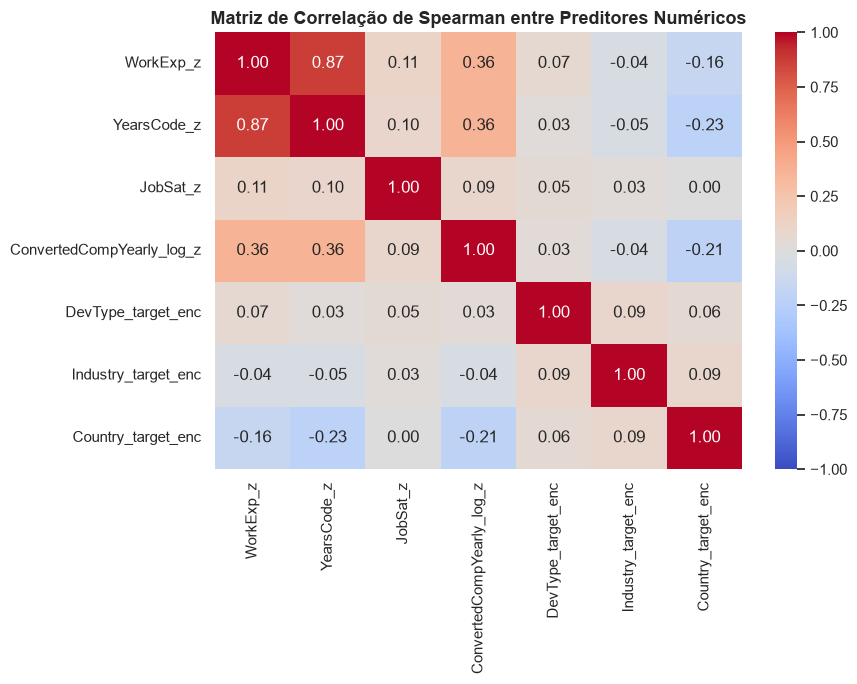

In [26]:
num_features = [f"{c}_z" for c in Z_SOURCE] + [f"{c}_target_enc" for c in HIGH_CARD]
spearman_corr = df_lab[num_features].corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matriz de Correlação de Spearman entre Preditores Numéricos", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Investigação da H3 como possível tautologia

Antes de usar `AIAcc` e `AIComplex` como preditoras, verifica-se se elas não repetem o rótulo por outro caminho. São duas perguntas:

1. **A ausência dessas variáveis é a ausência do próprio rótulo?** Na população de estudo, cerca de 30% não responderam `AIAcc`/`AIComplex`, proporção parecida com a ausência do rótulo (~33%). Se quem não usa IA tendesse a não responder, `AIAcc_missing` funcionaria como um indicador de não uso.
2. **A categoria `AIComplex = "I don't use AI tools for complex tasks / I don't know"` descreve o próprio não uso?**

`AISelect` (descartada na Fase 0) é usada aqui só como diagnóstico, nunca como preditor.

In [27]:
NAO_USA_COMPLEX = "I don't use AI tools for complex tasks / I don't know"
aiselect_por_id = df_outcomes.set_index("ResponseId")["AISelect"]

# (1a) População de estudo (com e sem rótulo): quem deixa AIAcc em branco?
aiselect_pop = df["ResponseId"].map(aiselect_por_id)
sem_rotulo = df["AIAgents_bin"].isna()
print(f"População de estudo: {len(df):,} desenvolvedores; rótulo ausente em {sem_rotulo.mean():.1%}")
for c in ["AIAcc", "AIComplex"]:
    falta = df[c] == "missing"
    print(f"  {c}: {falta.mean():.1%} ausente; destes, {sem_rotulo[falta].mean():.1%} também não têm rótulo")
nao_usa_ia = aiselect_pop == "No, and I don't plan to"
print(f"  Declaram não usar IA (AISelect = 'No, and I don't plan to', n = {nao_usa_ia.sum():,}): "
      f"{(df.loc[nao_usa_ia, 'AIAcc'] != 'missing').mean():.1%} responderam AIAcc")
print(f"  Deixaram AISelect em branco (n = {aiselect_pop.isna().sum():,}): "
      f"{(df.loc[aiselect_pop.isna(), 'AIAcc'] == 'missing').mean():.1%} também deixaram AIAcc em branco")

# (1b) e (2) Base rotulada: cruzamentos com o rótulo
def cruzamento(nome, flag):
    tabela = pd.crosstab(flag, df_lab["AIAgents_bin"])
    return {
        "cruzamento": nome, "n (grupo)": int(flag.sum()), "% da base rotulada": round(100 * flag.mean(), 1),
        "adoção no grupo (%)": round(100 * df_lab.loc[flag, "AIAgents_bin"].mean(), 1),
        "adoção nos demais (%)": round(100 * df_lab.loc[~flag, "AIAgents_bin"].mean(), 1),
        "p_valor": stats.chi2_contingency(tabela)[1], "V de Cramér": round(cramers_v(tabela), 3),
    }

flag_categoria = df_lab["AIComplex"] == NAO_USA_COMPLEX
h3_report = pd.DataFrame([
    cruzamento("AIAcc_missing × AIAgents_bin", df_lab["AIAcc"] == "missing"),
    cruzamento("AIComplex_missing × AIAgents_bin", df_lab["AIComplex"] == "missing"),
    cruzamento("AIComplex = 'I don't use…' × AIAgents_bin", flag_categoria),
])
display(h3_report)

# (2) Quem marca a categoria "I don't use AI tools for complex tasks"?
aiselect_lab = df_lab["ResponseId"].map(aiselect_por_id)
print("AISelect de quem marcou a categoria (base rotulada):")
print((100 * aiselect_lab[flag_categoria].value_counts(normalize=True, dropna=False)).round(1).rename_axis("AISelect").to_string())

v_completo = bivariate_report.loc[bivariate_report["variável"] == "AIComplex", "forca_efeito"].iloc[0]
sem_categoria = df_lab[~flag_categoria]
v_sem_categoria = cramers_v(pd.crosstab(sem_categoria["AIComplex"], sem_categoria["AIAgents_bin"]))
print(f"\nV de Cramér de AIComplex: {v_completo:.3f} com a categoria; {v_sem_categoria:.3f} sem ela")

População de estudo: 36,808 desenvolvedores; rótulo ausente em 32.7%
  AIAcc: 30.2% ausente; destes, 99.1% também não têm rótulo
  AIComplex: 30.2% ausente; destes, 99.2% também não têm rótulo
  Declaram não usar IA (AISelect = 'No, and I don't plan to', n = 3,810): 98.8% responderam AIAcc
  Deixaram AISelect em branco (n = 10,794): 99.8% também deixaram AIAcc em branco


,cruzamento,n (grupo),% da base rotulada,adoção no grupo (%),adoção nos demais (%),p_valor,V de Cramér
0,AIAcc_missing × AIAgents_bin,105,0.4,51.4,31.8,0.000026,0.027
1,AIComplex_missing × AIAgents_bin,90,0.4,42.2,31.8,0.045690,0.013
2,AIComplex = 'I don't use…' × AIAgents_bin,3833,15.5,4.5,36.9,0.000000,0.251


AISelect de quem marcou a categoria (base rotulada):
AISelect
No, and I don't plan to                        60.4
No, but I plan to soon                         13.4
Yes, I use AI tools monthly or infrequently    11.0
Yes, I use AI tools daily                       8.1
Yes, I use AI tools weekly                      7.0
NaN                                             0.1

V de Cramér de AIComplex: 0.337 com a categoria; 0.237 sem ela


**Leitura:**

- **A ausência não é tautologia.** Quem não usa IA responde às duas perguntas: entre os que declaram não usar nem planejar usar IA, ~99% responderam `AIAcc`. Os ~30% de ausência vêm de quem **abandonou o questionário** antes do bloco de IA: quem deixou `AISelect` em branco também deixou `AIAcc` em branco em ~100% dos casos, e quase todos esses respondentes também não têm rótulo, ficando fora da base rotulada. Nela, a ausência cai para 0,4%, e o efeito de `AIAcc_missing` e `AIComplex_missing` sobre o alvo é desprezível (V < 0,03).
- **A categoria "I don't use AI tools for complex tasks / I don't know" praticamente descreve o não uso.** Ela reúne ~15% da base rotulada, tem adoção de apenas ~4,5% (contra 31,9% no geral), e a maioria de quem a marca declara em `AISelect` que não usa IA. Sozinha, ela responde por boa parte da associação de `AIComplex` com o alvo: o V cai de ~0,34 para ~0,24 sem ela.
- **Causalidade reversa.** Mesmo sem essa categoria, confiança e avaliação da IA podem ser consequência do uso; com dados de um único momento (corte transversal), não é possível separar "confiar leva a usar" de "usar leva a confiar". A H3 passa a ser lida como **associação**, não como causa.

**Encaminhamento:** `AIAcc` e `AIComplex` seguem no conjunto da Etapa 1, **com ressalva** registrada no quadro de hipóteses e no Quadro de Descarte. O tratamento da categoria e a comparação de modelos com e sem as variáveis de percepção ficam para o Bloco B, decididos por experimento (seção "Revisão do conjunto de preditores").

### Candidatas fora de H1–H6 (exploração secundária)

As variáveis do subconjunto que não pertencem a nenhuma hipótese formal (`Age`, `EdLevel`, `Employment`, `Country`, `Industry`, `AIThreat`, `AISent` e `ConvertedCompYearly`) também são testadas contra o alvo, com os mesmos testes e tamanhos de efeito. Para a remuneração, os testes usam **só os valores observados**: como 47% foram imputados pela mediana, a imputação criaria um empate artificial em um único valor. Além do Mann-Whitney, ela é testada por **decis** (Qui-Quadrado), porque a curva da Fase 5 tem forma de U, e um teste de posição não detecta associação não monotônica.

Essas variáveis **não entram automaticamente** no filtro da Fase 4, que continua restrito aos preditores das hipóteses. O destino de cada uma fica registrado no Quadro de Descarte.

In [28]:
SECUNDARIAS_CAT = ["Age", "EdLevel", "Employment", "Country", "Industry", "AIThreat", "AISent"]
linhas_sec = [chi2_test(c) for c in SECUNDARIAS_CAT]

comp_obs = df_lab[~df_lab["ConvertedCompYearly_isBAD"]]
g1 = comp_obs.loc[comp_obs["AIAgents_bin"] == 1, "ConvertedCompYearly"]
g0 = comp_obs.loc[comp_obs["AIAgents_bin"] == 0, "ConvertedCompYearly"]
u, p_mw = stats.mannwhitneyu(g1, g0, alternative="two-sided")
r = rank_biserial(u, len(g1), len(g0))
# O Mann-Whitney só detecta diferença de posição (relação monotônica). Como a curva da Fase 5 tem
# forma de U, a remuneração também é testada por decis (Qui-Quadrado), que capta associação não monotônica.
decis_comp = pd.qcut(comp_obs["ConvertedCompYearly"], 10, duplicates="drop")
tabela_decis = pd.crosstab(decis_comp, comp_obs["AIAgents_bin"])
chi2_d, p_d = stats.chi2_contingency(tabela_decis)[:2]
linhas_sec.append({
    "variável": "ConvertedCompYearly", "teste": "Qui-Quadrado por decis (observados)",
    "estatística": round(chi2_d, 1), "p_valor": p_d, "tamanho_efeito": f"V de Cramér = {cramers_v(tabela_decis):.3f}",
    "forca_efeito": cramers_v(tabela_decis), "efeito_assinado": np.nan,
    "observação": f"Mann-Whitney: p={p_mw:.2f}, r rank-biserial = {r:+.3f} (sem diferença de posição)",
})

secondary_report = pd.DataFrame(linhas_sec)
secondary_report["significativo (p<0.05)"] = secondary_report["p_valor"] < 0.05
secondary_report[f"efeito >= {0.10}"] = secondary_report["forca_efeito"] >= 0.10

def amplitude_taxa(col, n_min=100):
    t = df_lab.groupby(col)["AIAgents_bin"].agg(["mean", "count"])
    t = t[t["count"] >= n_min]["mean"]
    return f"{t.min():.1%} a {t.max():.1%}"

secondary_report["taxa de adoção entre níveis (n ≥ 100)"] = [
    amplitude_taxa(v) if v in SECUNDARIAS_CAT else
    f"{tabela_decis[1].div(tabela_decis.sum(axis=1)).min():.1%} a {tabela_decis[1].div(tabela_decis.sum(axis=1)).max():.1%} (decis)"
    for v in secondary_report["variável"]
]
SECUNDARIAS_SIGNIFICATIVAS = secondary_report.loc[secondary_report["significativo (p<0.05)"], "variável"].tolist()
SECUNDARIAS_DESCARTADAS = secondary_report.loc[~secondary_report["significativo (p<0.05)"], "variável"].tolist()

with pd.option_context("display.max_colwidth", None):
    display(secondary_report.drop(columns=["forca_efeito", "efeito_assinado", "n_categorias_testadas"], errors="ignore")
            .sort_values("p_valor").fillna({"observação": ""}))

for v in ["AISent", "AIThreat"]:
    t = df_lab.groupby(v)["AIAgents_bin"].agg(taxa_adocao="mean", n="count").sort_values("taxa_adocao")
    print(f"\n--- {v} ---")
    print(t.assign(taxa_adocao=lambda d: (100 * d["taxa_adocao"]).round(1).astype(str) + "%").to_string())

,variável,teste,estatística,p_valor,tamanho_efeito,observação,significativo (p<0.05),efeito >= 0.1,taxa de adoção entre níveis (n ≥ 100)
6,AISent,Qui-Quadrado,2406.2,0.000000e+00,V de Cramér = 0.312,,True,True,5.8% a 50.9%
3,Country,Qui-Quadrado,447.6,6.750754e-86,V de Cramér = 0.134,,True,True,19.9% a 54.7%
4,Industry,Qui-Quadrado,198.9,3.591890e-34,V de Cramér = 0.090,,True,False,20.8% a 36.4%
5,AIThreat,Qui-Quadrado,156.2,1.218685e-33,V de Cramér = 0.079,,True,False,22.2% a 40.4%
7,ConvertedCompYearly,Qui-Quadrado por decis (observados),133.9,1.891180e-24,V de Cramér = 0.085,"Mann-Whitney: p=0.33, r rank-biserial = -0.009 (sem diferença de posição)",True,False,26.0% a 40.2% (decis)
0,Age,Qui-Quadrado,60.3,3.939306e-11,V de Cramér = 0.049,,True,False,23.2% a 33.1%
2,Employment,Qui-Quadrado,41.4,7.901607e-08,V de Cramér = 0.041,,True,False,28.4% a 35.7%
1,EdLevel,Qui-Quadrado,38.6,2.377954e-06,V de Cramér = 0.039,,True,False,27.2% a 48.8%



--- AISent ---
                 taxa_adocao     n
AISent                            
Very unfavorable        5.8%  2312
Unfavorable            13.9%  2655
Unsure                 18.3%   416
Indifferent            22.3%  4284
Favorable              36.6%  9265
Very favorable         50.9%  5783
missing                51.3%    39

--- AIThreat ---
             taxa_adocao      n
AIThreat                       
missing            22.2%    108
No                 29.8%  16000
I'm not sure       32.8%   5142
Yes                40.4%   3504


**Leitura:**

- **Todas as oito candidatas têm associação significativa (p < 0,05)**, o que é esperado com ~24 mil linhas. O tamanho de efeito separa os casos:
  - `AISent` (V = 0,31): associação moderada, a segunda maior da base, atrás só de `AIComplex`. A adoção vai de 5,8% ("Very unfavorable") a 50,9% ("Very favorable"). Por ser uma atitude em relação à IA, tem o **mesmo risco de causalidade reversa da H3**.
  - `Country` (V = 0,13): fraca, mas acima do limiar de 0,10 (adoção de 19,9% a 54,7% entre os países com n ≥ 100).
  - `Industry` (V = 0,09), `ConvertedCompYearly` (V = 0,085) e `AIThreat` (V = 0,08): fracas, abaixo de 0,10.
  - `Age`, `Employment` e `EdLevel` (V entre 0,04 e 0,05): desprezíveis.
- **Remuneração:** o Mann-Whitney não acusa diferença (p = 0,33; r ≈ 0), porque as medianas de adotantes e não adotantes são praticamente iguais (≈ US$ 79–80 mil). A curva da Fase 5 mostra por quê: a relação tem forma de U, e por decis a associação é significativa, mas fraca. A remuneração também tem 47% de ausência.
- **Decisão:** pelo critério das Fases 3 e 4 (p < 0,05), as oito avançariam, e o conjunto final passaria de 9 para 17 variáveis, o que obrigaria a refazer o Bloco B. Em vez de aplicar o critério de forma automática, a inclusão será decidida no Bloco B por **experimento**, como nas Fases 8 a 10: comparar o modelo com os 9 preditores atuais e com os 17, nas mesmas 5 dobras, com F1 e o teste de Nadeau-Bengio. Até lá, as oito ficam fora do conjunto final e aparecem no Quadro de Descarte como "significativas; decisão no Bloco B".

## Fase 4: Análise de Colinearidade e Multicolinearidade (Tratamento)

O Fator de Inflação da Variância (VIF) é calculado para os preditores sobreviventes da Fase 3, já projetados (dummy/target encoding da Fase 2 + Z-score). O limiar de exclusão é **VIF > 5**. Por se tratar do Caminho A, a colinearidade afeta principalmente a estabilidade de modelos lineares/logísticos; ainda assim, o VIF é tratado para garantir parcimônia.

In [29]:
def feature_columns_for(var):
    if var in ("WorkExp", "YearsCode", "JobSat"):
        return [f"{var}_z"]
    if var in HIGH_CARD:
        return [f"{var}_target_enc"]
    return [c for c in df_lab.columns if c.startswith(f"{var}_") and c in df_dummies.columns]

vif_features = []
for v in SIGNIFICANT_PREDICTORS:
    vif_features += feature_columns_for(v)
vif_features = sorted(set(vif_features))
print("Colunas do design matrix para VIF:", len(vif_features))

X_vif = df_lab[vif_features].astype(float)
X_vif = X_vif.assign(const=1.0)

Colunas do design matrix para VIF: 38


In [30]:
def compute_vif(X):
    cols = [c for c in X.columns if c != "const"]
    return pd.DataFrame({
        "variável": cols,
        "VIF": [variance_inflation_factor(X.values, X.columns.get_loc(c)) for c in cols],
    }).sort_values("VIF", ascending=False)

vif_report = compute_vif(X_vif)
vif_report

,variável,VIF
28,RemoteWork_missing,28.967236
23,OrgSize_missing,20.617369
13,ICorPM_missing,12.158095
36,WorkExp_z,5.070114
37,YearsCode_z,5.054613
3,AIAcc_Somewhat trust,2.739570
17,OrgSize_20 to 99 employees,2.266030
16,OrgSize_100 to 499 employees,2.162169
26,RemoteWork_Remote,2.120904
1,AIAcc_Neither trust nor distrust,2.110533


### Regra de corte do VIF (iterativa)

A variável com maior VIF > 5 é removida uma a uma, recalculando-se a cada rodada, até que todas as sobreviventes apresentem VIF ≤ 5. Esse procedimento evita a remoção em bloco de variáveis cuja colinearidade era causada por uma única redundante.

In [31]:
X_iter = X_vif.copy()
removed_vif = []
while True:
    rep = compute_vif(X_iter)
    worst = rep.iloc[0]
    if worst["VIF"] <= 5:
        break
    removed_vif.append({"variável": worst["variável"], "VIF_no_momento_da_remoção": round(worst["VIF"], 2)})
    X_iter = X_iter.drop(columns=[worst["variável"]])

final_vif = compute_vif(X_iter)
print("Removidas por VIF > 5:")
display(pd.DataFrame(removed_vif)) if removed_vif else print("(nenhuma)")
print("\nVIF final (todas <= 5):")
final_vif

Removidas por VIF > 5:


,variável,VIF_no_momento_da_remoção
0,RemoteWork_missing,28.97
1,OrgSize_missing,9.66
2,WorkExp_z,5.07



VIF final (todas <= 5):


,variável,VIF
3,AIAcc_Somewhat trust,2.723402
13,ICorPM_missing,2.295419
1,AIAcc_Neither trust nor distrust,2.103516
17,OrgSize_20 to 99 employees,2.079029
25,RemoteWork_Remote,2.044161
16,OrgSize_100 to 499 employees,1.999654
22,OrgSize_Less than 20 employees,1.932739
2,AIAcc_Somewhat distrust,1.887194
5,"AIComplex_Good, but not great at handling comp...",1.856008
15,"OrgSize_10,000 or more employees",1.810474


In [32]:
FINAL_FEATURES = [c for c in X_iter.columns if c != "const"]
print("Features finais pós-colinearidade:", len(FINAL_FEATURES))
FINAL_FEATURES

Features finais pós-colinearidade: 35


['AIAcc_Highly trust',
 'AIAcc_Neither trust nor distrust',
 'AIAcc_Somewhat distrust',
 'AIAcc_Somewhat trust',
 'AIAcc_missing',
 'AIComplex_Good, but not great at handling complex tasks',
 "AIComplex_I don't use AI tools for complex tasks / I don't know",
 'AIComplex_Neither good or bad at handling complex tasks',
 'AIComplex_Very poor at handling complex tasks',
 'AIComplex_Very well at handling complex tasks',
 'AIComplex_missing',
 'DevType_target_enc',
 'ICorPM_People manager',
 'ICorPM_missing',
 'JobSat_z',
 'OrgSize_10,000 or more employees',
 'OrgSize_100 to 499 employees',
 'OrgSize_20 to 99 employees',
 'OrgSize_5,000 to 9,999 employees',
 'OrgSize_500 to 999 employees',
 'OrgSize_I don’t know',
 'OrgSize_Just me - I am a freelancer, sole proprietor, etc.',
 'OrgSize_Less than 20 employees',
 'RemoteWork_Hybrid (some remote, leans heavy to in-person)',
 'RemoteWork_In-person',
 'RemoteWork_Remote',
 'RemoteWork_Your choice (very flexible, you can come in when you want or j

## Fase 5: Conexão com Machine Learning e Explicabilidade

Para cada preditor contínuo sobrevivente, é ajustada uma curva de suavização local (**LOESS**) contra `AIAgents_bin`, permitindo inspecionar linearidade/monotonicidade e justificar a família de modelo a recomendar nas próximas etapas de modelagem preditiva.

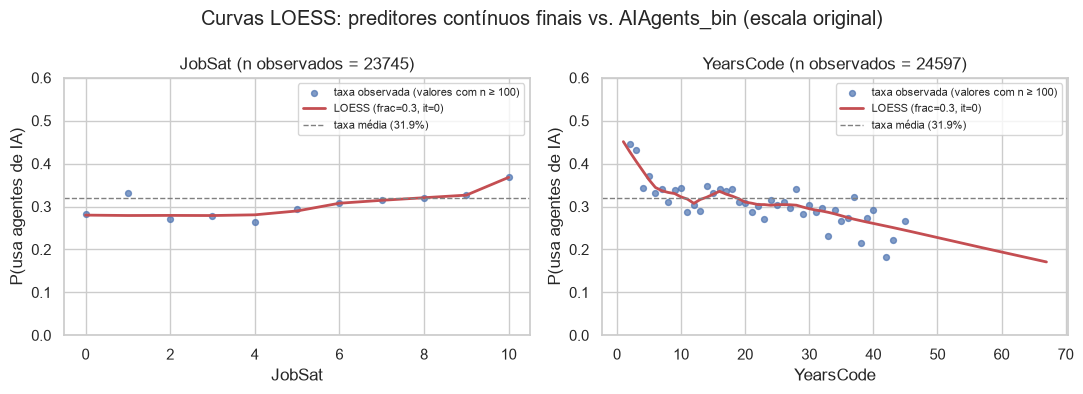

In [33]:
# LOESS sobre os valores OBSERVADOS (isBAD == False): os valores imputados pela mediana formariam
# um pico artificial num único ponto do eixo x. it=0 desliga as iterações robustas do lowess, que,
# com alvo binário, tratam a classe minoritária (1) como outlier e puxam a curva para baixo.
continuous_final = [f[:-2] for f in FINAL_FEATURES if f.endswith("_z")]
taxa_base = df_lab["AIAgents_bin"].mean()

fig, axes = plt.subplots(1, len(continuous_final), figsize=(5.5 * len(continuous_final), 4), squeeze=False)
for ax, col in zip(axes[0], continuous_final):
    obs = df_lab[~df_lab[f"{col}_isBAD"]]
    x = obs[col].values.astype(float)
    y = obs["AIAgents_bin"].values.astype(float)
    smoothed = lowess(y, x, frac=0.3, it=0, return_sorted=True)
    taxa_por_valor = obs.groupby(col)["AIAgents_bin"].agg(["mean", "count"])
    taxa_por_valor = taxa_por_valor[taxa_por_valor["count"] >= 100]
    ax.scatter(taxa_por_valor.index, taxa_por_valor["mean"], s=18, color="#4C72B0", alpha=0.7,
               label="taxa observada (valores com n ≥ 100)")
    ax.plot(smoothed[:, 0], smoothed[:, 1], color="#C44E52", linewidth=2, label="LOESS (frac=0.3, it=0)")
    ax.axhline(taxa_base, color="gray", linestyle="--", linewidth=1, label=f"taxa média ({taxa_base:.1%})")
    ax.set_title(f"{col} (n observados = {len(obs)})")
    ax.set_xlabel(col)
    ax.set_ylabel("P(usa agentes de IA)")
    ax.set_ylim(0, 0.6)
    ax.legend(fontsize=8)
plt.suptitle("Curvas LOESS: preditores contínuos finais vs. AIAgents_bin (escala original)")
plt.tight_layout()
plt.show()

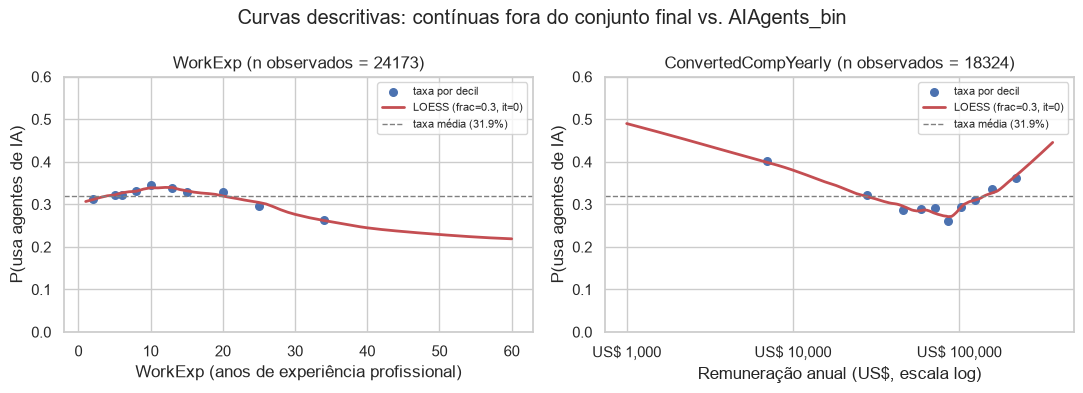


--- WorkExp: taxa de uso por decil ---
              taxa     n  mediana_x
WorkExp                            
(0.999, 3.0]  31.3  3405        2.0
(3.0, 5.0]    32.3  2556        5.0
(5.0, 7.0]    32.2  2101        6.0
(7.0, 9.0]    33.2  1933        8.0
(9.0, 11.0]   34.5  2358       10.0
(11.0, 14.0]  33.8  2344       13.0
(14.0, 17.0]  32.8  2230       15.0
(17.0, 22.0]  32.8  2657       20.0
(22.0, 28.0]  29.5  2295       25.0
(28.0, 60.0]  26.2  2294       34.0

--- ConvertedCompYearly: taxa de uso por decil ---
                      taxa     n  mediana_x
ConvertedCompYearly                        
(999.999, 16383.0]    40.2  1834     7023.5
(16383.0, 36758.0]    32.2  1833    27773.0
(36758.0, 52207.0]    28.8  1885    45942.0
(52207.0, 65616.4]    29.0  1778    59096.0
(65616.4, 79870.0]    29.0  1832    72000.0
(79870.0, 92820.0]    26.0  1832    85851.0
(92820.0, 111636.0]   29.4  1837   102065.0
(111636.0, 139218.0]  31.0  1904   123993.0
(139218.0, 180000.0]  33.5  1868   1

In [34]:
# Curvas descritivas das contínuas que não estão no conjunto final: WorkExp (removida pelo VIF,
# redundante com YearsCode) e remuneração (testada na Fase 3). Mesmo critério das curvas acima:
# só valores observados e lowess com it=0. Os pontos azuis são a taxa de uso por decil.
CURVAS_EXTRAS = [("WorkExp", "WorkExp (anos de experiência profissional)", False),
                 ("ConvertedCompYearly", "Remuneração anual (US$, escala log)", True)]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
taxas_por_decil = {}
for ax, (col, rotulo, escala_log) in zip(axes, CURVAS_EXTRAS):
    obs = df_lab[~df_lab[f"{col}_isBAD"]]
    x = obs[col].astype(float)
    x_plot = np.log10(x) if escala_log else x
    y = obs["AIAgents_bin"].astype(float)
    smoothed = lowess(y.values, x_plot.values, frac=0.3, it=0, return_sorted=True)
    decis = pd.qcut(x, 10, duplicates="drop")
    tabela = obs.groupby(decis, observed=True)["AIAgents_bin"].agg(taxa="mean", n="count")
    tabela["mediana_x"] = x.groupby(decis, observed=True).median()
    taxas_por_decil[col] = tabela
    x_pontos = np.log10(tabela["mediana_x"]) if escala_log else tabela["mediana_x"]
    ax.scatter(x_pontos, tabela["taxa"], s=30, color="#4C72B0", label="taxa por decil")
    ax.plot(smoothed[:, 0], smoothed[:, 1], color="#C44E52", linewidth=2, label="LOESS (frac=0.3, it=0)")
    ax.axhline(taxa_base, color="gray", linestyle="--", linewidth=1, label=f"taxa média ({taxa_base:.1%})")
    if escala_log:
        marcas = [3, 4, 5]
        ax.set_xticks(marcas, [f"US$ {10**m:,.0f}" for m in marcas])
    ax.set_title(f"{col} (n observados = {len(obs)})")
    ax.set_xlabel(rotulo)
    ax.set_ylabel("P(usa agentes de IA)")
    ax.set_ylim(0, 0.6)
    ax.legend(fontsize=8)
plt.suptitle("Curvas descritivas: contínuas fora do conjunto final vs. AIAgents_bin")
plt.tight_layout()
plt.show()

for col, tabela in taxas_por_decil.items():
    print(f"\n--- {col}: taxa de uso por decil ---")
    print(tabela.assign(taxa=lambda d: (100 * d["taxa"]).round(1)).to_string())

**Diagnóstico Científico LOESS:**

*Preditores do conjunto final:*
- **`YearsCode`:** relação **monotônica decrescente, mas não-linear**. A adoção cai rapidamente nos primeiros ~5 anos de programação (de ~45% para ~33%), forma um **platô** entre ~5 e ~28 anos (próximo da média de 31,9%) e volta a cair depois disso (~20–25% acima de 40 anos; a cauda acima de 45 anos tem poucos casos e deve ser lida com cautela). O sentido confirma H1, embora o efeito global seja desprezível ($r = -0{,}068$).
- **`JobSat`:** relação **monotônica crescente, mas não-linear**. A adoção fica estável (~28%) entre as notas 0 e 4 e sobe gradualmente a partir de 5, chegando a ~37% na nota 10.

*Contínuas fora do conjunto final (curvas descritivas):*
- **`WorkExp`** (removida pelo VIF, redundante com `YearsCode`): curva **plana** (31–35%) até ~22 anos de experiência profissional, com queda depois (26% no decil de 28 anos ou mais). É o mesmo padrão de `YearsCode`, o que reforça que as duas medem a mesma coisa.
- **Remuneração** (inclusão decidida no Bloco B): relação **não monotônica, em U**. A adoção é de 40% no decil mais baixo (até ~US$ 16 mil/ano), cai para 26–29% na faixa de ~US$ 37 mil a ~US$ 112 mil e volta a subir até 36% no decil mais alto (acima de US$ 180 mil). É a única curva com inversão de sentido, e é por isso que o Mann-Whitney não a detecta.

**Implicação para a modelagem:** nos preditores do conjunto final não há inversão de sentido, mas há **platôs e mudanças de inclinação** (limiares), que um termo linear único não captura; se a remuneração entrar, ela traz ainda uma relação em U. Isso favorece modelos baseados em árvores, que aprendem cortes por limiar naturalmente — **Árvore de Decisão** como modelo de base e **CatBoost** (gradient boosting com tratamento nativo de categóricas) como segundo modelo; a troca de Random Forest/Gradient Boosting por CatBoost está justificada na ficha de proposta e na Fase 8 (7 dos 9 preditores são categóricos). Pesa também a favor das árvores o fato de a maior parte da matriz final ser composta de dummies e de um *target encoding*, em que interações entre variáveis são plausíveis. Uma regressão logística com termos não-lineares (ex.: *splines*) seria uma alternativa interpretável viável para as relações monotônicas, mas exigiria especificar à mão cada limiar e a forma em U.

> **Nota técnica:** as curvas usam apenas valores observados (sem os imputados pela mediana, que criariam um pico artificial) e `it=0` no `lowess` — as iterações robustas padrão tratam a classe minoritária (1) como *outlier* em alvos binários e subestimam a probabilidade.

### Fechamento Metodológico Obrigatório do Bloco A

Consolidação formal de quais hipóteses da Fase 0 resistiram à auditoria empírica e apresentação da Trilha de Auditoria (*Audit Trail*) contínua.

In [35]:
HYPOTHESIS_TEXT = {
    "H1": "Experiência (WorkExp/YearsCode) associada a MENOR uso de agentes de IA",
    "H2": "Cargo (DevType) e porte (OrgSize, empresas maiores => mais uso) associados ao uso",
    "H3": "Confiança (AIAcc) e percepção em tarefas complexas (AIComplex) associadas a MAIOR uso",
    "H4": "Satisfação no cargo (JobSat) associada ao uso (não direcional)",
    "H5": "Trabalho remoto e contribuidores individuais (ICorPM) adotam MAIS",
    "H6": "Maior frequência de visita ao SO associada a MENOR uso",
}
EFEITO_MIN = 0.10  # abaixo disso o efeito é desprezível/fraco (convenção de Cohen para V e |r|)
# Ressalvas de validade que não aparecem nos testes (ver Fase 0 e a investigação da H3 na Fase 3)
RESSALVAS_VALIDADE = {"H3": "possível tautologia/causalidade reversa; ver Fase 3"}

removidas_vif = {v for v in SIGNIFICANT_PREDICTORS
                 if not any(f == f"{v}_z" or f == f"{v}_target_enc" or f.startswith(f"{v}_") for f in FINAL_FEATURES)}

quadro_hipoteses = []
for h, texto in HYPOTHESIS_TEXT.items():
    testes = bivariate_report[bivariate_report["hipótese"] == h]
    direcoes = direction_report[(direction_report["hipótese"] == h) & (direction_report["sentido esperado"] != "não direcional")]
    nao_sig = testes.loc[~testes["significativo (p<0.05)"], "variável"].tolist()
    contrarias = direcoes.loc[direcoes["sentido confirmado"] == "Não", "variável"].tolist()
    fracas = testes.loc[testes["forca_efeito"] < EFEITO_MIN, "variável"].tolist()
    apoiam = [v for v in testes["variável"] if v not in nao_sig + contrarias]

    if not apoiam:
        decisao = "REFUTADA"
    elif nao_sig or contrarias:
        motivos = ([f"sem significância: {', '.join(nao_sig)}"] if nao_sig else []) + \
                  ([f"direção contrária: {', '.join(contrarias)}"] if contrarias else [])
        decisao = f"PARCIAL ({'; '.join(motivos)})"
    elif fracas or h in RESSALVAS_VALIDADE:
        motivos = ([f"efeito desprezível, abaixo de {EFEITO_MIN}, em: {', '.join(fracas)}"] if fracas else []) + \
                  ([RESSALVAS_VALIDADE[h]] if h in RESSALVAS_VALIDADE else [])
        decisao = f"MANTIDA COM RESSALVA ({'; '.join(motivos)})"
    else:
        decisao = "MANTIDA"

    resultado = "; ".join(
        f"{r['variável']}: p={r['p_valor']:.1e}, {r['tamanho_efeito']}" for _, r in testes.iterrows()
    )
    obs = [f"{v} removida por VIF > 5 (redundante)" for v in testes["variável"] if v in removidas_vif]
    quadro_hipoteses.append({
        "ID": h, "Hipótese": texto, "Teste(s)": ", ".join(sorted(set(testes["teste"]))),
        "Resultado": resultado, "Decisão": decisao, "Observação": "; ".join(obs),
    })

df_quadro_hipoteses = pd.DataFrame(quadro_hipoteses)
with pd.option_context("display.max_colwidth", None):
    display(df_quadro_hipoteses)

,ID,Hipótese,Teste(s),Resultado,Decisão,Observação
0,H1,Experiência (WorkExp/YearsCode) associada a MENOR uso de agentes de IA,Mann-Whitney U,"WorkExp: p=1.4e-03, r rank-biserial = -0.025; YearsCode: p=4.6e-18, r rank-biserial = -0.068","MANTIDA COM RESSALVA (efeito desprezível, abaixo de 0.1, em: WorkExp, YearsCode)",WorkExp removida por VIF > 5 (redundante)
1,H2,"Cargo (DevType) e porte (OrgSize, empresas maiores => mais uso) associados ao uso",Qui-Quadrado,"DevType: p=1.4e-64, V de Cramér = 0.118; OrgSize: p=1.6e-06, V de Cramér = 0.042",PARCIAL (direção contrária: OrgSize),
2,H3,Confiança (AIAcc) e percepção em tarefas complexas (AIComplex) associadas a MAIOR uso,Qui-Quadrado,"AIAcc: p=0.0e+00, V de Cramér = 0.266; AIComplex: p=0.0e+00, V de Cramér = 0.337",MANTIDA COM RESSALVA (possível tautologia/causalidade reversa; ver Fase 3),
3,H4,Satisfação no cargo (JobSat) associada ao uso (não direcional),Mann-Whitney U,"JobSat: p=2.3e-11, r rank-biserial = +0.052","MANTIDA COM RESSALVA (efeito desprezível, abaixo de 0.1, em: JobSat)",
4,H5,Trabalho remoto e contribuidores individuais (ICorPM) adotam MAIS,Qui-Quadrado,"RemoteWork: p=2.0e-08, V de Cramér = 0.042; ICorPM: p=2.3e-31, V de Cramér = 0.075",PARCIAL (direção contrária: ICorPM),
5,H6,Maior frequência de visita ao SO associada a MENOR uso,Qui-Quadrado,"SOVisitFreq: p=3.2e-80, V de Cramér = 0.126",MANTIDA,


**Leitura do quadro de hipóteses:**

- **H3 (confiança e percepção em tarefas complexas) é a hipótese mais forte da base:** a adoção sobe de forma monotônica de 13,9% ("Highly distrust") para 65,0% ("Highly trust") em `AIAcc`, e de 21,6% para 65,2% em `AIComplex`. **Ressalva:** parte dessa força vem da categoria "I don't use AI tools for complex tasks", que praticamente descreve o não uso (sem ela, o V de `AIComplex` cai de 0,34 para 0,24), e a direção causal não pode ser estabelecida com dados de um único momento (ver Fase 3). Por isso a H3 fica como **mantida com ressalva**.
- **H6 confirmada:** quem visita o Stack Overflow várias vezes por dia adota menos que quem o visita raramente (efeito de substituição parcial, $V = 0{,}126$).
- **H1 e H4 mantidas com ressalva:** o sentido é o previsto (H1) e a associação é significativa, mas o tamanho de efeito é desprezível ($|r| < 0{,}10$); a significância decorre do tamanho da amostra.
- **H2 parcial:** `DevType` tem associação fraca, mas relevante ($V = 0{,}118$); já `OrgSize` tem efeito desprezível e **no sentido oposto** ao previsto (empresas maiores adotam ligeiramente menos).
- **H5 parcial:** trabalho remoto adota um pouco mais que presencial, como previsto, mas **gestores de pessoas adotam mais que contribuidores individuais** (≈41,7% vs. ≈30,3%), contrariando a hipótese.

Fora das hipóteses, as oito candidatas secundárias também têm associação significativa; só `AISent` (V = 0,31) e `Country` (V = 0,13) passam do limiar de 0,10 (ver Fase 3). A inclusão delas no modelo será decidida no Bloco B.

As hipóteses não foram reformuladas após a observação dos dados, para evitar *HARKing* (formular hipóteses depois de conhecer os resultados); as divergências ficam registradas como achados.

In [36]:
# Complementa a trilha iniciada na Fase 0 (registrar_auditoria) — sem reiniciar a lista,
# para preservar os registros das Fases 0, 1 e 2.
for v in DROPPED_FASE3:
    row = bivariate_report[bivariate_report["variável"] == v].iloc[0]
    registrar_auditoria("Fase 3", v, "Descartada", f"{row['teste']}: p={row['p_valor']:.3g} (>= 0.05, sem significância).")

for _, r in secondary_report.iterrows():
    if r["significativo (p<0.05)"]:
        nota = " Percepção sobre IA: mesma ressalva de causalidade reversa da H3." if r["variável"] == "AISent" else ""
        registrar_auditoria("Fase 3", r["variável"], "Significativa; fora do conjunto final (decisão no Bloco B)",
                            f"{r['teste']}: p={r['p_valor']:.1e}, {r['tamanho_efeito']}. Fora de H1–H6; "
                            f"a inclusão será decidida por experimento no Bloco B (9 x 17 preditores).{nota}")
    else:
        registrar_auditoria("Fase 3", r["variável"], "Descartada",
                            f"{r['teste']}: p={r['p_valor']:.2f}, {r['tamanho_efeito']} (sem associação com o alvo).")

for r in removed_vif:
    registrar_auditoria("Fase 4", r["variável"], "Coluna removida (VIF > 5)",
                        f"VIF = {r['VIF_no_momento_da_remoção']} no momento da remoção (procedimento iterativo).")

for v in SIGNIFICANT_PREDICTORS:
    if v in removidas_vif:
        registrar_auditoria("Fase 4", v, "Descartada (variável inteira)",
                            "Todas as suas colunas codificadas foram removidas por VIF > 5.")
    else:
        ressalva = " Ressalva: possível tautologia/causalidade reversa (H3)." if v in ("AIAcc", "AIComplex") else ""
        registrar_auditoria("Fase 5", v, "Mantida (sobrevivente final)",
                            f"Significativa na Fase 3 e com VIF <= 5 na Fase 4.{ressalva}")

audit_trail_df = pd.DataFrame(audit_trail)
with pd.option_context("display.max_rows", None, "display.max_colwidth", 90):
    display(audit_trail_df)

,Fase,Variável,Status,Justificativa
0,Fase 0,AISelect,Descartada (preditor),Proxy quase direta do alvo (vazamento/tautologia). Guardada em df_outcomes.
1,Fase 0,ResponseId,Mantida (não-preditora),"Chave primária sequencial de controle operacional, sem poder explicativo."
2,Fase 1,ConvertedCompYearly,Abaixo do piso de domínio -> NA,469 valores < US$ 1.000/ano (implausíveis) convertidos em NA.
3,Fase 1,WorkExp,Outlier extremo -> NA,"18 valores fora de [-37.0, 61.0] (3x IQR) convertidos em NA."
4,Fase 1,YearsCode,Outlier extremo -> NA,"21 valores fora de [-39.0, 73.0] (3x IQR) convertidos em NA."
5,Fase 1,JobSat,Outlier extremo -> NA,"0 valores fora de [0.0, 14.0] (3x IQR) convertidos em NA."
6,Fase 1,ConvertedCompYearly,Outlier extremo -> NA,"296 valores fora de [-195206.2, 365752.8] (3x IQR) convertidos em NA."
7,Fase 1,Age/EdLevel/Employment (linhas),659 linhas removidas,"Remoção de casos com NAs em colunas de perda irrelevante (< 2%, total: 1.76%)."
8,Fase 1,WorkExp,isBAD (imputado 10.0),5.24% nulos imputados pela mediana; coluna indicadora WorkExp_isBAD criada.
9,Fase 1,YearsCode,isBAD (imputado 15.0),9.48% nulos imputados pela mediana; coluna indicadora YearsCode_isBAD criada.


In [37]:
n_populacao = int((df_raw["MainBranch"] == "I am a developer by profession").sum())
variaveis_finais = [v for v in SIGNIFICANT_PREDICTORS if v not in removidas_vif]

print("=== FECHAMENTO NUMÉRICO DO PIPELINE (ETAPA 1) ===")
print(f"Base bruta original: {len(df_raw)} linhas x {len(raw_header.columns)} colunas")
print(f"População de estudo (devs profissionais, recorte de escopo): {n_populacao} linhas")
print(f"Após remoção de linhas com NA em variáveis com < 2% de ausência (Fase 1): {len(df)} linhas")
print(f"Registros rotulados válidos (df_lab): {len(df_lab)} linhas")
print(f"Colunas selecionadas para o estudo: {len(COLS)} (inclui ResponseId e MainBranch)")
print("Descartadas na Fase 0: AISelect (vazamento); ResponseId mantida apenas como chave")
print(f"Colunas codificadas removidas por VIF > 5 (Fase 4): {len(removed_vif)} -> {[r['variável'] for r in removed_vif]}")
print(f"Variáveis originais eliminadas por inteiro na Fase 4: {sorted(removidas_vif)}")
print(f"Preditores finais: {len(variaveis_finais)} variáveis originais -> {len(FINAL_FEATURES)} colunas codificadas")
print("  ", variaveis_finais)
print(f"Candidatas fora de H1–H6 testadas na Fase 3: {len(secondary_report)}")
print("   significativas (decisão no Bloco B):", SECUNDARIAS_SIGNIFICATIVAS)
print("   descartadas (sem associação):", SECUNDARIAS_DESCARTADAS)

=== FECHAMENTO NUMÉRICO DO PIPELINE (ETAPA 1) ===
Base bruta original: 49191 linhas x 172 colunas
População de estudo (devs profissionais, recorte de escopo): 37467 linhas
Após remoção de linhas com NA em variáveis com < 2% de ausência (Fase 1): 36808 linhas
Registros rotulados válidos (df_lab): 24754 linhas
Colunas selecionadas para o estudo: 22 (inclui ResponseId e MainBranch)
Descartadas na Fase 0: AISelect (vazamento); ResponseId mantida apenas como chave
Colunas codificadas removidas por VIF > 5 (Fase 4): 3 -> ['RemoteWork_missing', 'OrgSize_missing', 'WorkExp_z']
Variáveis originais eliminadas por inteiro na Fase 4: ['WorkExp']
Preditores finais: 9 variáveis originais -> 35 colunas codificadas
   ['YearsCode', 'DevType', 'OrgSize', 'AIAcc', 'AIComplex', 'JobSat', 'RemoteWork', 'ICorPM', 'SOVisitFreq']
Candidatas fora de H1–H6 testadas na Fase 3: 8
   significativas (decisão no Bloco B): ['Age', 'EdLevel', 'Employment', 'Country', 'Industry', 'AIThreat', 'AISent', 'ConvertedCompYe

---
# Bloco B — Modelagem Preditiva e Avaliação Rigorosa

O Bloco A concluiu a fase exploratória e entregou a base condicionada, auditada e com explicabilidade preliminar. Agora, no Bloco B, iniciamos a etapa de modelagem preditiva, estabelecendo a formulação formal do problema, a métrica de negócio, o baseline de comparação e o protocolo rigoroso de particionamento para blindagem contra vazamento de dados (*data leakage*).

## Fase 6 — Formulação do problema, métrica e baseline (Entrega 1)

Nesta fase definimos formalmente a tarefa de aprendizado de máquina, alinhamos o momento da tomada de decisão no negócio para prevenir vazamento de alvo (*target leakage*), estabelecemos a matriz de custo de erros e definimos o baseline ingênuo de referência.

### 6.1 Unidade de observação, tarefa e momento da decisão

- **Tipo de tarefa:** **Classificação Binária Supervisionada** (Caminho A).
- **Variável-alvo:** `AIAgents_bin` ($1$ = Desenvolvedor utiliza agentes de IA no trabalho; $0$ = Desenvolvedor não utiliza agentes ou utiliza exclusivamente ferramentas de autocompletar).
- **Unidade de observação:** Cada linha representa um desenvolvedor profissional individual.
- **Momento da decisão no negócio:** A previsão do modelo será utilizada no início de ciclos corporativos de planejamento de TI ou lançamento de ferramentas para identificar quais desenvolvedores e equipes têm alta probabilidade de adotar agentes de IA. Isso orienta a distribuição de licenças empresariais, programas piloto e treinamentos de capacitação técnica de forma proativa.
- **Prevenção de Target Leakage:** `AISelect` (proxy quase direta do alvo) foi excluída na Fase 0. Os demais preditores refletem perfil estrutural, senioridade, tamanho de empresa, arranjo de trabalho e percepções sobre IA, todos obtíveis por questionário antes da decisão.
- **Risco remanescente (causalidade reversa):** `AIAcc` e `AIComplex` são percepções que podem ser, em parte, *consequência* do uso de agentes (quem usa avalia melhor a IA). O nível `AIComplex = "I don't use AI tools for complex tasks"` tem taxa de adoção de apenas ~4,5%, aproximando-se de uma descrição do próprio comportamento. Recomenda-se, nas próximas fases, comparar o desempenho com e sem esses dois preditores (análise de sensibilidade).

### 6.2 Análise de custo dos erros e escolha da métrica principal

Em um cenário de planejamento tecnológico corporativo:
- **Falso Positivo (FP):** O modelo prevê que o desenvolvedor adotará agentes, mas ele não adota.  
  *Custo:* Baixo a moderado (custo de alocação de licença ou convite para workshop que não é plenamente aproveitado).
- **Falso Negativo (FN):** O modelo prevê que o desenvolvedor não adotará, e a organização deixa de equipá-lo e capacitá-lo com agentes autônomos.  
  *Custo:* Alto (perda substancial de ganho de produtividade competitiva e risco de defasagem técnica do profissional).

**Métrica Principal Escolhida:** **F1-Score da Classe Positiva (Adotantes)**.  
Como a classe positiva representa aproximadamente 31,9% dos respondentes válidos (desbalanceamento moderado de ~2,1:1), a acurácia convencional é uma métrica enganosa: um classificador ingênuo que aposte apenas na maioria obteria 68,1% de acurácia com utilidade nula para o negócio. O **F1-Score da classe positiva** harmoniza Precisão e Recall, garantindo que o modelo capture o máximo de adotantes potenciais (Recall alto) sem produzir um número inaceitável de alarmes falsos (Precisão controlada).

**Métricas Secundárias de Diagnóstico:**  
- **PR-AUC (Precision-Recall Area Under Curve):** Curva recomendada para classes minoritárias.
- **Balanced Accuracy:** Média aritmética da sensibilidade de cada classe.
- **Acurácia Global:** Reportada apenas como conferência de sanidade.

**Critério de Sucesso do Negócio:**  
O modelo de aprendizado de máquina deve superar expressivamente **os dois** baselines ingênuos em F1-Score da classe positiva: o majoritário ($F1 = 0$) e, principalmente, o estratificado aleatório ($F1 \approx 0{,}32$, igual à prevalência da classe positiva). Meta: $F1 > 0{,}50$ na validação cruzada do treino.

### 6.3 Baseline de Referência Ingênuo (`DummyClassifier`)

Conforme exigido pelo protocolo metodológico, todo modelo preditivo deve ser contrastado contra uma referência ingênua que não aprende regras dos dados:
1. `DummyClassifier(strategy="most_frequent")`: Sempre prevê a classe majoritária ($0$ = Não Adotante).
2. `DummyClassifier(strategy="stratified")`: Prevê classes aleatoriamente respeitando a proporção da base.

Para que a comparação seja justa, os baselines são avaliados **sob o mesmo protocolo dos modelos** (validação cruzada estratificada no treino, Seção 7.4), e não sobre a base inteira. Abaixo, apenas montamos a base de modelagem.

In [38]:
# Base de modelagem: as MESMAS linhas de df_lab (rotuladas, após a regra dos 2%), mas com os valores
# ANTERIORES a qualquer etapa que aprende com os dados (cercas de outlier, medianas, z-score, target
# encoding). Esses passos são refeitos dentro do Pipeline da Fase 7, ajustado só no treino.
# A seleção de variáveis vem das Fases 3-4 (FINAL_FEATURES).
NUM_MODEL = [v for v in CONTINUOUS if f"{v}_z" in FINAL_FEATURES]
TE_MODEL = [v for v in HIGH_CARD if f"{v}_target_enc" in FINAL_FEATURES]
DUMMY_MODEL = [c for c in FINAL_FEATURES if c in df_dummies.columns]
OHE_SOURCE = [v for v in LOW_CARD if any(c.startswith(f"{v}_") for c in DUMMY_MODEL)]

base_modelagem = df_pre_aprendizado.set_index("ResponseId").loc[df_lab["ResponseId"]]
X_modelagem = base_modelagem[NUM_MODEL + TE_MODEL + OHE_SOURCE].reset_index(drop=True)
y_modelagem = df_lab["AIAgents_bin"].reset_index(drop=True)

print("Numéricas (outlier -> isBAD/mediana -> z-score):", NUM_MODEL)
print("Alta cardinalidade (target encoding por dobras):", TE_MODEL)
print("Baixa cardinalidade (dummies aprovadas nas Fases 3-4):", OHE_SOURCE, f"-> {len(DUMMY_MODEL)} colunas")
print(f"\nBase de Modelagem pronta: {X_modelagem.shape[0]} instâncias x {X_modelagem.shape[1]} variáveis brutas")
print(f"Distribuição real do alvo: Classe 0 = {(y_modelagem==0).mean():.1%}, Classe 1 = {(y_modelagem==1).mean():.1%}")
print("\nNAs ainda presentes (serão tratados dentro do Pipeline):")
X_modelagem.isna().sum()[lambda s: s > 0]

Numéricas (outlier -> isBAD/mediana -> z-score): ['YearsCode', 'JobSat']
Alta cardinalidade (target encoding por dobras): ['DevType']
Baixa cardinalidade (dummies aprovadas nas Fases 3-4): ['OrgSize', 'ICorPM', 'RemoteWork', 'SOVisitFreq', 'AIAcc', 'AIComplex'] -> 32 colunas

Base de Modelagem pronta: 24754 instâncias x 9 variáveis brutas
Distribuição real do alvo: Classe 0 = 68.1%, Classe 1 = 31.9%

NAs ainda presentes (serão tratados dentro do Pipeline):


YearsCode       148
JobSat         1009
OrgSize        3494
ICorPM         3861
RemoteWork     3615
SOVisitFreq     737
AIAcc           105
AIComplex        90
dtype: int64

## Fase 7 — Particionamento e prevenção de vazamento (Entrega 1)

Seguindo a regra de ouro da Ciência de Dados:
> *"Tudo o que aprende algo com os dados (médias, medianas, escalas, encodings, pesos e hiperparâmetros) deve ser ajustado exclusivamente no conjunto de treino e depois aplicado ao conjunto de teste."*

### 7.1 Separação do Conjunto de Teste (Holdout Estratificado)

- **Proporção:** 80% Treino e 20% Teste.
- **Estratificação:** `stratify=y_modelagem`, garantindo que a proporção exata de adotantes de IA (~31,9%) seja idêntica nas duas partições.
- **Semente Fixa:** `random_state=42`, garantindo reprodutibilidade científica.
- **Particionamento sobre dados brutos:** o *split* é feito **antes** de qualquer passo que aprende com os dados; por isso a base de modelagem ainda contém NAs e categorias em texto.
- **Lacramento do Teste:** O conjunto de teste é isolado e **não será tocado** até a Fase 12 (Avaliação Final Única).

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X_modelagem,
    y_modelagem,
    test_size=0.20,
    random_state=RNG_SEED,
    stratify=y_modelagem
)

print(f"Conjunto de Treino: {X_train.shape[0]} observações ({X_train.shape[0]/len(X_modelagem):.1%})")
print(f"Conjunto de Teste (Lacrado até Fase 12): {X_test.shape[0]} observações ({X_test.shape[0]/len(X_modelagem):.1%})")

proporcao_treino = y_train.value_counts(normalize=True).to_dict()
proporcao_teste = y_test.value_counts(normalize=True).to_dict()

df_estratificacao = pd.DataFrame({
    "Partição": ["Treino (80%)", "Teste (20%)", "Base Completa (100%)"],
    "Nº Amostras": [len(y_train), len(y_test), len(y_modelagem)],
    "% Classe 0 (Não Adotante)": [
        f"{proporcao_treino[0]:.2%}", f"{proporcao_teste[0]:.2%}", f"{(y_modelagem==0).mean():.2%}"
    ],
    "% Classe 1 (Adotante)": [
        f"{proporcao_treino[1]:.2%}", f"{proporcao_teste[1]:.2%}", f"{(y_modelagem==1).mean():.2%}"
    ]
})

print("\nVerificação da Estratificação de Classes:")
df_estratificacao

Conjunto de Treino: 19803 observações (80.0%)
Conjunto de Teste (Lacrado até Fase 12): 4951 observações (20.0%)

Verificação da Estratificação de Classes:


,Partição,Nº Amostras,% Classe 0 (Não Adotante),% Classe 1 (Adotante)
0,Treino (80%),19803,68.13%,31.87%
1,Teste (20%),4951,68.13%,31.87%
2,Base Completa (100%),24754,68.13%,31.87%


### 7.2 Esquema de Validação Cruzada no Treino

Para ajustar hiperparâmetros e selecionar modelos sem contaminar o teste, configuramos o objeto de validação cruzada:
- `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` — mantém a mesma proporção da classe positiva (~31,9%) em cada dobra.
- **Verificação de casos especiais:** `GroupKFold` não se aplica porque cada linha possui um `ResponseId` único (sem múltiplos registros do mesmo indivíduo), e `TimeSeriesSplit` também não se aplica por se tratar de um corte transversal (edição 2025 da pesquisa), sem ordem temporal.
- **Pré-processamento dentro das dobras:** como o pré-processamento é um passo do `Pipeline`, a validação cruzada o reajusta em cada dobra de treino, sem enxergar a dobra de validação.
- **Pareamento entre modelos:** Este mesmo objeto de validação cruzada será compartilhado pelos modelos comparados para garantir avaliação estritamente pareada (mesmas dobras e mesmos dados).

In [40]:
cv_esquema = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG_SEED)

print("Esquema de Validação Cruzada configurado com sucesso:")
print(f"  - Tipo: StratifiedKFold")
print(f"  - Número de Folds: {cv_esquema.get_n_splits()}")
print(f"  - Embaralhamento prévio (shuffle): {cv_esquema.shuffle}")
print(f"  - Semente de controle: {cv_esquema.random_state}")

fold_stats = []
for fold_idx, (idx_tr, idx_val) in enumerate(cv_esquema.split(X_train, y_train), 1):
    y_tr_fold = y_train.iloc[idx_tr]
    y_val_fold = y_train.iloc[idx_val]
    fold_stats.append({
        "Fold": f"Dobra {fold_idx}",
        "Amostras Treino": len(y_tr_fold),
        "Amostras Validação": len(y_val_fold),
        "% Positivos Validação": f"{y_val_fold.mean():.2%}"
    })

pd.DataFrame(fold_stats)

Esquema de Validação Cruzada configurado com sucesso:
  - Tipo: StratifiedKFold
  - Número de Folds: 5
  - Embaralhamento prévio (shuffle): True
  - Semente de controle: 42


,Fold,Amostras Treino,Amostras Validação,% Positivos Validação
0,Dobra 1,15842,3961,31.86%
1,Dobra 2,15842,3961,31.86%
2,Dobra 3,15842,3961,31.89%
3,Dobra 4,15843,3960,31.87%
4,Dobra 5,15843,3960,31.87%


### 7.3 Pipeline de pré-processamento ajustado somente no treino

Todo passo que **aprende parâmetros com os dados** passa a ser um estágio de um `ColumnTransformer`, ajustado apenas no treino (e, na validação cruzada, apenas na dobra de treino):

| Bloco | Passos | O que é aprendido |
|---|---|---|
| Numéricas (`YearsCode`, `JobSat`) | outlier extremo (3×IQR) → NA; imputação pela mediana; z-score | cercas de Tukey, medianas, média e desvio-padrão |
| Flags isBAD | outlier extremo → NA; indicador de ausência | cercas de Tukey |
| `DevType` | NA → `'missing'`; *target encoding* com suavização $m=10$ | taxa de adoção por categoria, por dobras (*cross-fitting*) |
| Demais categóricas | NA → `'missing'`; dummies aprovadas nas Fases 3–4 | nada (lista de colunas fixa, vinda da AED) |

O `TargetEncoder` do scikit-learn usa *cross-fitting* no `fit_transform`: cada linha do treino é codificada com estatísticas calculadas **sem** a própria dobra, o que evita que o rótulo da linha vaze para o seu próprio atributo.

In [41]:
class OutlierExtremoParaNA(BaseEstimator, TransformerMixin):
    """Cercas de Tukey (k x IQR) aprendidas no treino; valores fora delas viram NaN (tratados depois pelo isBAD)."""
    def __init__(self, k=3.0):
        self.k = k

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        q1, q3 = X.quantile(0.25), X.quantile(0.75)
        iqr = q3 - q1
        self.limite_inf_, self.limite_sup_ = q1 - self.k * iqr, q3 + self.k * iqr
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.feature_names_in_).astype(float)
        return X.mask((X < self.limite_inf_) | (X > self.limite_sup_))

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_


class DummiesSelecionadas(BaseEstimator, TransformerMixin):
    """Reproduz o one-hot da Fase 2 (NA -> 'missing') mantendo apenas as colunas aprovadas nas Fases 3-4.
    Não aprende nada com os dados; categorias inéditas no teste viram linha de zeros."""
    def __init__(self, colunas):
        self.colunas = colunas

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(pd.DataFrame(X).columns, dtype=object)
        return self

    def transform(self, X):
        X = pd.DataFrame(X).astype(object).fillna("missing")
        dummies = pd.get_dummies(X, prefix=list(X.columns)).astype(float)
        return dummies.reindex(columns=self.colunas, fill_value=0.0)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.colunas, dtype=object)


def construir_target_encoder():
    # A partir do scikit-learn 1.9, o embaralhamento das dobras é passado via objeto de CV
    # (shuffle/random_state no próprio TargetEncoder foram descontinuados).
    from sklearn import __version__ as versao_sklearn
    if tuple(int(p) for p in versao_sklearn.split(".")[:2]) >= (1, 9):
        cv_te = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG_SEED)
        return TargetEncoder(target_type="binary", smooth=10.0, cv=cv_te)
    return TargetEncoder(target_type="binary", smooth=10.0, cv=5, shuffle=True, random_state=RNG_SEED)


def construir_preprocessador():
    return ColumnTransformer([
        ("num", Pipeline([
            ("outlier_para_na", OutlierExtremoParaNA(k=3.0)),
            ("mediana", SimpleImputer(strategy="median")),
            ("zscore", StandardScaler()),
        ]), NUM_MODEL),
        ("isbad", Pipeline([
            ("outlier_para_na", OutlierExtremoParaNA(k=3.0)),
            ("flag", MissingIndicator(features="all")),
        ]), NUM_MODEL),
        ("target_enc", Pipeline([
            ("missing", SimpleImputer(strategy="constant", fill_value="missing")),
            ("te", construir_target_encoder()),
        ]), TE_MODEL),
        ("dummies", DummiesSelecionadas(DUMMY_MODEL), OHE_SOURCE),
    ], verbose_feature_names_out=True).set_output(transform="pandas")


preprocessador = construir_preprocessador()
Xt_train = preprocessador.fit_transform(X_train, y_train).astype(float)  # fit_transform => cross-fitting no TE
print(f"Matriz de treino transformada: {Xt_train.shape[0]} linhas x {Xt_train.shape[1]} colunas, "
      f"NAs restantes = {int(Xt_train.isna().sum().sum())}")

num = preprocessador.named_transformers_["num"]
te = preprocessador.named_transformers_["target_enc"].named_steps["te"]
pd.DataFrame({
    "limite_sup (3xIQR)": num.named_steps["outlier_para_na"].limite_sup_.values,
    "mediana (treino)": num.named_steps["mediana"].statistics_,
    "média z-score (treino)": num.named_steps["zscore"].mean_,
    "dp z-score (treino)": num.named_steps["zscore"].scale_,
    "mediana (AED, base inteira)": [isbad_report[[r["variável"] for r in isbad_report].index(v)]["valor de imputação (mediana)"] for v in NUM_MODEL],
}, index=NUM_MODEL).round(3)

Matriz de treino transformada: 19803 linhas x 37 colunas, NAs restantes = 0


,limite_sup (3xIQR),mediana (treino),média z-score (treino),dp z-score (treino),"mediana (AED, base inteira)"
YearsCode,70.0,15.0,18.015,10.980,15.0
JobSat,14.0,8.0,7.252,1.943,8.0


In [42]:
print(f"Target encoding de DevType aprendido só no treino: média global = {te.target_mean_:.4f}, "
      f"{len(te.categories_[0])} categorias")

# Auditoria de colinearidade da matriz final de TREINO (inclui as flags isBAD, que não estavam na Fase 4)
X_vif_treino = Xt_train.assign(const=1.0)
vif_treino = compute_vif(X_vif_treino)
print(f"VIF máximo na matriz de treino: {vif_treino['VIF'].max():.2f}")
vif_treino.head(5)

Target encoding de DevType aprendido só no treino: média global = 0.3187, 32 categorias


VIF máximo na matriz de treino: 2.72


,variável,VIF
8,dummies__AIAcc_Somewhat trust,2.721205
17,dummies__ICorPM_missing,2.293591
20,dummies__OrgSize_20 to 99 employees,2.104979
6,dummies__AIAcc_Neither trust nor distrust,2.092452
28,dummies__RemoteWork_Remote,2.040110


### 7.4 Baselines avaliados sob o protocolo (validação cruzada no treino)

Os `DummyClassifier` são encaixados no mesmo `Pipeline` (pré-processamento + modelo) e avaliados com o mesmo `cv_esquema` que será usado pelos modelos, garantindo comparação pareada. O conjunto de teste não é usado.

In [43]:
scoring = {
    "F1 (classe 1)": "f1",
    "PR-AUC": "average_precision",
    "Balanced Accuracy": "balanced_accuracy",
    "Acurácia": "accuracy",
    "Precisão (classe 1)": make_scorer(precision_score, zero_division=0),
    "Recall (classe 1)": "recall",
}

linhas_baseline = []
for nome, estrategia in [("Dummy (Mais Frequente)", "most_frequent"), ("Dummy (Estratificado Aleatório)", "stratified")]:
    pipe = Pipeline([("prep", construir_preprocessador()),
                     ("modelo", DummyClassifier(strategy=estrategia, random_state=RNG_SEED))])
    res = cross_validate(pipe, X_train, y_train, cv=cv_esquema, scoring=scoring)
    linha = {"Modelo Baseline": nome}
    for m in scoring:
        linha[m] = f"{res[f'test_{m}'].mean():.3f} ± {res[f'test_{m}'].std():.3f}"
    linhas_baseline.append(linha)

tabela_baseline = pd.DataFrame(linhas_baseline).set_index("Modelo Baseline")
print("Baselines ingênuos — média ± desvio-padrão nas 5 dobras de validação do treino:")
tabela_baseline

Baselines ingênuos — média ± desvio-padrão nas 5 dobras de validação do treino:


,F1 (classe 1),PR-AUC,Balanced Accuracy,Acurácia,Precisão (classe 1),Recall (classe 1)
Modelo Baseline,,,,,,
Dummy (Mais Frequente),0.000 ± 0.000,0.319 ± 0.000,0.500 ± 0.000,0.681 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
Dummy (Estratificado Aleatório),0.322 ± 0.009,0.320 ± 0.003,0.503 ± 0.007,0.570 ± 0.006,0.323 ± 0.009,0.320 ± 0.009


### 7.5 Checklist anti-vazamento e risco residual

| Item | Situação |
|---|---|
| Teste separado antes de qualquer passo que aprende com os dados | ✔ (Seção 7.1, sobre dados brutos) |
| Cercas de outlier, medianas, z-score e flags isBAD ajustados só no treino | ✔ (Pipeline, Seção 7.3) |
| *Target encoding* por dobras (*cross-fitting*) | ✔ (`TargetEncoder`, `cv=5`) |
| Pré-processamento reajustado em cada dobra da validação cruzada | ✔ (`Pipeline` dentro do `cross_validate`) |
| `AISelect` (proxy do alvo) fora dos preditores | ✔ (Fase 0) |
| Seleção de variáveis (Fases 3–4) feita sem o conjunto de teste | ✖ — feita na AED, com toda a base rotulada |

**Risco residual — seleção de variáveis:** a lista de variáveis veio das Fases 3–4, que usaram toda a base rotulada (inclusive as linhas que hoje formam o teste). Para verificar se isso influenciou a escolha, os testes de associação são refeitos abaixo **apenas no treino**: se todas as variáveis continuam significativas, a seleção não depende das linhas de teste.

In [44]:
treino_bruto = X_train.assign(AIAgents_bin=y_train.values)
robustez = []
for v in NUM_MODEL:
    obs = treino_bruto.dropna(subset=[v])
    p = stats.mannwhitneyu(obs.loc[obs["AIAgents_bin"] == 1, v], obs.loc[obs["AIAgents_bin"] == 0, v]).pvalue
    robustez.append({"variável": v, "teste (só treino)": "Mann-Whitney U", "p_valor": p})
for v in TE_MODEL + OHE_SOURCE:
    s = treino_bruto[v].astype(object).fillna("missing")
    if s.nunique() > 15:
        s = s.where(s.isin(s.value_counts().nlargest(15).index), "Outros_agrupado")
    p = stats.chi2_contingency(pd.crosstab(s, treino_bruto["AIAgents_bin"]))[1]
    robustez.append({"variável": v, "teste (só treino)": "Qui-Quadrado", "p_valor": p})

df_robustez = pd.DataFrame(robustez)
df_robustez["significativo (p<0.05)"] = df_robustez["p_valor"] < 0.05
print("Todas as variáveis selecionadas continuam significativas usando só o treino:",
      bool(df_robustez["significativo (p<0.05)"].all()))
df_robustez

Todas as variáveis selecionadas continuam significativas usando só o treino: True


,variável,teste (só treino),p_valor,significativo (p<0.05)
0,YearsCode,Mann-Whitney U,7.602699e-16,True
1,JobSat,Mann-Whitney U,4.512692e-07,True
2,DevType,Qui-Quadrado,8.644049e-50,True
3,OrgSize,Qui-Quadrado,1.207759e-05,True
4,ICorPM,Qui-Quadrado,1.160893e-24,True
5,RemoteWork,Qui-Quadrado,5.395180e-07,True
6,SOVisitFreq,Qui-Quadrado,3.386086e-61,True
7,AIAcc,Qui-Quadrado,4.813890e-309,True
8,AIComplex,Qui-Quadrado,0.000000e+00,True


### 7.6 Fase 4 refeita no treino (VIF)

A Seção 3 do enunciado pede que os filtros das Fases 3 (p-valor) e 4 (VIF) sejam refeitos **só na partição de treino**, porque na Etapa 1 eles usaram a base inteira, inclusive as linhas que hoje formam o teste. A Fase 3 foi refeita acima. Aqui refazemos a Fase 4 com as mesmas regras da Etapa 1 (z-score nas numéricas, *target encoding* em `DevType`, dummies com `drop_first` nas demais e remoção iterativa enquanto houver VIF > 5), mas com todos os parâmetros estimados só no treino.

In [45]:
# Fase 4 refeita só no treino: mesmas regras da Etapa 1 (z-score nas numéricas, target encoding em DevType,
# dummies com drop_first nas demais), mas com todos os parâmetros estimados apenas com as linhas de treino.
VARS_FASE3 = SIGNIFICANT_PREDICTORS  # inclui WorkExp, eliminada na Fase 4 da Etapa 1
base_treino_vif = base_modelagem.reset_index(drop=True).loc[X_train.index, VARS_FASE3].copy()

num_vif = [v for v in VARS_FASE3 if v in CONTINUOUS]
cat_vif = [v for v in VARS_FASE3 if v in LOW_CARD]
partes = []
for v in num_vif:
    s = OutlierExtremoParaNA(k=3.0).fit_transform(base_treino_vif[[v]])[v]
    s = s.fillna(s.median())
    partes.append(((s - s.mean()) / s.std()).rename(f"{v}_z"))
for v in TE_MODEL:
    te_vif = construir_target_encoder()
    partes.append(pd.Series(te_vif.fit_transform(base_treino_vif[[v]].fillna("missing"), y_train).ravel(),
                            index=base_treino_vif.index, name=f"{v}_target_enc"))
partes.append(pd.get_dummies(base_treino_vif[cat_vif].astype(object).fillna("missing"),
                             prefix=cat_vif, drop_first=True).astype(float))
X_vif_tr = pd.concat(partes, axis=1).assign(const=1.0)

X_iter_tr, removidas_vif_treino = X_vif_tr.copy(), []
while True:
    rep = compute_vif(X_iter_tr)
    if rep.iloc[0]["VIF"] <= 5:
        break
    removidas_vif_treino.append({"coluna": rep.iloc[0]["variável"], "VIF": round(rep.iloc[0]["VIF"], 2)})
    X_iter_tr = X_iter_tr.drop(columns=[rep.iloc[0]["variável"]])

removidas_etapa1 = [r["variável"] for r in removed_vif]
removidas_agora = [r["coluna"] for r in removidas_vif_treino]
comparacao_vif = pd.DataFrame({"coluna": sorted(set(removidas_etapa1) | set(removidas_agora))})
comparacao_vif["removida na Etapa 1 (base inteira)"] = comparacao_vif["coluna"].isin(removidas_etapa1)
comparacao_vif["removida agora (só treino)"] = comparacao_vif["coluna"].isin(removidas_agora)
mesma_selecao = bool((comparacao_vif["removida na Etapa 1 (base inteira)"]
                      == comparacao_vif["removida agora (só treino)"]).all())
print("Remoções por VIF > 5, refeitas só no treino:", removidas_vif_treino)
print("Mesma seleção da Etapa 1:", mesma_selecao)
print(f"VIF máximo após as remoções (treino): {compute_vif(X_iter_tr)['VIF'].max():.2f}")
registrar_auditoria("Bloco B (Seção 3)", "Filtros das Fases 3 e 4", "Refeitos só no treino",
                    "Testes bivariados e VIF iterativo recalculados no treino: "
                    + ("nenhuma variável mudou de status." if mesma_selecao and df_robustez["significativo (p<0.05)"].all()
                       else "houve mudança de status (ver Seção 7.6)."))
comparacao_vif

Remoções por VIF > 5, refeitas só no treino: [{'coluna': 'RemoteWork_missing', 'VIF': np.float64(29.18)}, {'coluna': 'OrgSize_missing', 'VIF': np.float64(9.69)}, {'coluna': 'WorkExp_z', 'VIF': np.float64(5.01)}]
Mesma seleção da Etapa 1: True


VIF máximo após as remoções (treino): 2.72


,coluna,removida na Etapa 1 (base inteira),removida agora (só treino)
0,OrgSize_missing,True,True
1,RemoteWork_missing,True,True
2,WorkExp_z,True,True


**Leitura:** a remoção iterativa no treino elimina exatamente as mesmas três colunas da Etapa 1 (`RemoteWork_missing`, `OrgSize_missing` e `WorkExp_z`), e o VIF máximo final é 2,72. Somando ao resultado da célula anterior (as 9 variáveis continuam significativas só no treino), **nenhuma variável mudou de status**, e a seleção da Etapa 1 não dependeu das linhas de teste. O registro entra no Quadro de Descarte.

---
## Fase 8 — Ajustes da base pré-modelagem

Cada família de modelo pede uma preparação diferente, mas todas partem da **mesma base** (`X_train`), usam as **mesmas dobras** (`cv_esquema`) e ficam **dentro de um `Pipeline`**, reajustado em cada dobra. A tabela segue as colunas da tabela de famílias do enunciado.

| Exigência | Árvore de Decisão (modelo de base) | CatBoost (segundo modelo) |
|---|---|---|
| Escala (z-score) | **Retirada.** Árvores não dependem de escala (evidência abaixo) | Não usada |
| Categóricas | Dummies aprovadas nas Fases 3–4; `DevType` (alta cardinalidade) com `TargetEncoder` por dobras | **Nativas**, como texto. O CatBoost codifica pelo alvo de forma ordenada, sem vazamento |
| Ausentes | Estratégia escolhida na Fase 9 | Estratégia escolhida na Fase 9 |
| Colinearidade | Pouco sensível; o VIF ≤ 5 da Fase 4 foi mantido para a explicabilidade | Idem |
| Outliers | Robusta. O corte 3×IQR → NA + isBAD foi mantido por **qualidade do dado**, não por sensibilidade do modelo (evidência abaixo) | `NaN` nativo |

Os hiperparâmetros dos dois modelos estão **fixos** nesta etapa (árvore: `max_depth=6`, `min_samples_leaf=50`; CatBoost: 300 iterações, `learning_rate=0.1`, `depth=6`). Eles servem só para comparar estratégias de preparação nas Fases 9 e 10; a busca de hiperparâmetros é feita na Fase 11.

In [46]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.impute import KNNImputer
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import TunedThresholdClassifierCV
from sklearn.metrics import average_precision_score
from catboost import CatBoostClassifier
print("Bibliotecas do Bloco B (Fases 8 a 10) carregadas.")

Bibliotecas do Bloco B (Fases 8 a 10) carregadas.


In [47]:
class ImputacaoKNN(BaseEstimator, TransformerMixin):
    """Imputação multivariada (estratégia C da Fase 9): numéricas (após outlier -> NA) e one-hot completo das
    categóricas são padronizados e imputados juntos por KNNImputer. Tudo é aprendido só no treino da dobra."""
    def __init__(self, num_cols, cat_cols, colunas_saida, n_neighbors=5):
        self.num_cols = num_cols
        self.cat_cols = cat_cols
        self.colunas_saida = colunas_saida
        self.n_neighbors = n_neighbors

    def _codificar(self, X):
        X = pd.DataFrame(X)
        num = self.outlier_.transform(X[self.num_cols]).reset_index(drop=True)
        oh = pd.get_dummies(X[self.cat_cols].astype(object), prefix=self.cat_cols).astype(float)
        oh = oh.reindex(columns=self.colunas_oh_, fill_value=0.0).reset_index(drop=True)
        for c in self.cat_cols:  # pergunta não respondida -> todas as dummies dela viram NaN (a imputar)
            oh.loc[X[c].isna().values, [k for k in self.colunas_oh_ if k.startswith(f"{c}_")]] = np.nan
        return pd.concat([num, oh], axis=1)

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.outlier_ = OutlierExtremoParaNA(k=3.0).fit(X[self.num_cols])
        self.colunas_oh_ = pd.get_dummies(X[self.cat_cols].astype(object), prefix=self.cat_cols).columns.tolist()
        Z = self._codificar(X)
        self.escala_ = StandardScaler().fit(Z)
        self.imputer_ = KNNImputer(n_neighbors=self.n_neighbors).fit(self.escala_.transform(Z))
        return self

    def transform(self, X):
        Z = self._codificar(X)
        Zi = pd.DataFrame(self.escala_.inverse_transform(self.imputer_.transform(self.escala_.transform(Z))),
                          columns=Z.columns, index=pd.DataFrame(X).index)
        return pd.concat([Zi[self.num_cols], Zi.reindex(columns=self.colunas_saida, fill_value=0.0)], axis=1)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(list(self.num_cols) + list(self.colunas_saida), dtype=object)


DUMMY_SEM_MISSING = [c for c in DUMMY_MODEL if not c.endswith("_missing")]
CAT_CB = TE_MODEL + OHE_SOURCE   # as 7 categóricas entram no CatBoost como texto


def construir_prep_arvore(imputacao="isbad"):
    """Pré-processamento da família árvore. imputacao: 'isbad' (A), 'simples' (B) ou 'knn' (C) — ver Fase 9."""
    te_devtype = ("target_enc", Pipeline([("missing", SimpleImputer(strategy="constant", fill_value="missing")),
                                          ("te", construir_target_encoder())]), TE_MODEL)
    if imputacao == "knn":
        return ColumnTransformer([("knn", ImputacaoKNN(NUM_MODEL, OHE_SOURCE, DUMMY_SEM_MISSING),
                                   NUM_MODEL + OHE_SOURCE), te_devtype]).set_output(transform="pandas")
    blocos = [("num", Pipeline([("outlier_para_na", OutlierExtremoParaNA(k=3.0)),
                                ("mediana", SimpleImputer(strategy="median"))]), NUM_MODEL)]
    if imputacao == "isbad":
        blocos.append(("isbad", Pipeline([("outlier_para_na", OutlierExtremoParaNA(k=3.0)),
                                          ("flag", MissingIndicator(features="all"))]), NUM_MODEL))
        dummies = DummiesSelecionadas(DUMMY_MODEL)  # NA vira a categoria 'missing'
    else:
        dummies = Pipeline([("moda", SimpleImputer(strategy="most_frequent")),
                            ("dummies", DummiesSelecionadas(DUMMY_SEM_MISSING))])
    blocos += [te_devtype, ("dummies", dummies, OHE_SOURCE)]
    return ColumnTransformer(blocos).set_output(transform="pandas")


def preparar_catboost_nativo(X):
    """Não aprende nada: categóricas viram texto (NA -> 'missing'); numéricas seguem com NaN."""
    X = X[NUM_MODEL + CAT_CB].copy()
    X[CAT_CB] = X[CAT_CB].astype(object).fillna("missing").astype(str)
    return X


def construir_prep_catboost(imputacao="nativa"):
    """Família CatBoost. 'nativa': NaN nas numéricas e 'missing' nas categóricas;
    'simples': mediana nas numéricas e moda nas categóricas (estratégia B da Fase 9)."""
    if imputacao == "nativa":
        return FunctionTransformer(preparar_catboost_nativo)
    return ColumnTransformer([("num", SimpleImputer(strategy="median"), NUM_MODEL),
                              ("cat", SimpleImputer(strategy="most_frequent"), CAT_CB)],
                             verbose_feature_names_out=False).set_output(transform="pandas")


def construir_arvore(imputacao="isbad", peso_classe="balanced"):
    return Pipeline([("prep", construir_prep_arvore(imputacao)),
                     ("modelo", DecisionTreeClassifier(max_depth=6, min_samples_leaf=50,
                                                       class_weight=peso_classe, random_state=RNG_SEED))])


def construir_catboost(imputacao="nativa", peso_classe="Balanced"):
    # cat_features como tupla: com lista, o clone() do scikit-learn falha na validação cruzada.
    return Pipeline([("prep", construir_prep_catboost(imputacao)),
                     ("modelo", CatBoostClassifier(iterations=300, learning_rate=0.1, depth=6,
                                                   auto_class_weights=peso_classe, cat_features=tuple(CAT_CB),
                                                   random_seed=RNG_SEED, thread_count=2,
                                                   verbose=0, allow_writing_files=False))])


# Evidência 1: o z-score não muda nada numa árvore (transformação monotônica preserva os cortes).
arvore_fase7 = Pipeline([("prep", construir_preprocessador()),
                         ("modelo", DecisionTreeClassifier(max_depth=6, min_samples_leaf=50,
                                                           class_weight="balanced", random_state=RNG_SEED))])
f1_com_z = cross_validate(arvore_fase7, X_train, y_train, cv=cv_esquema, scoring="f1")["test_score"]
f1_sem_z = cross_validate(construir_arvore(), X_train, y_train, cv=cv_esquema, scoring="f1")["test_score"]
print(f"Árvore com z-score (pipeline da Fase 7): F1 por dobra = {np.round(f1_com_z, 4)}")
print(f"Árvore sem z-score (pipeline da Fase 8): F1 por dobra = {np.round(f1_sem_z, 4)}")
print(f"Maior diferença entre as dobras: {np.abs(f1_com_z - f1_sem_z).max():.6f}")

# Evidência 2: o corte 3xIQR só remove valores implausíveis de YearsCode.
cercas = OutlierExtremoParaNA(k=3.0).fit(X_train[NUM_MODEL])
cortados = (X_train[NUM_MODEL] > cercas.limite_sup_) | (X_train[NUM_MODEL] < cercas.limite_inf_)
print("\nValores cortados no treino (viram NA + isBAD):", cortados.sum().to_dict(),
      "| limites superiores:", cercas.limite_sup_.to_dict())
print("Valores de YearsCode cortados:", sorted(X_train.loc[cortados["YearsCode"], "YearsCode"].unique()))

Árvore com z-score (pipeline da Fase 7): F1 por dobra = [0.5388 0.529  0.5525 0.5361 0.5586]
Árvore sem z-score (pipeline da Fase 8): F1 por dobra = [0.5388 0.529  0.5525 0.5361 0.5586]
Maior diferença entre as dobras: 0.000000

Valores cortados no treino (viram NA + isBAD): {'YearsCode': 6, 'JobSat': 0} | limites superiores: {'YearsCode': 70.0, 'JobSat': 14.0}
Valores de YearsCode cortados: [np.float64(75.0), np.float64(82.0), np.float64(100.0)]


### 8.2 Escala e outliers na árvore

- **Z-score retirado.** Uma árvore só compara cada variável com pontos de corte, e o z-score é uma transformação monotônica, que não muda a ordem dos valores. O F1 por dobra com e sem z-score é **idêntico** nas 5 dobras.
- **Corte de outliers mantido.** As cercas 3×IQR aprendidas no treino só cortam **6 valores de `YearsCode`** (75, 82 e 100 anos programando), que são implausíveis. A árvore seria robusta a eles, mas tratá-los como erro de preenchimento (NA + isBAD) mantém a regra da Etapa 1. Em `JobSat` (0 a 10) nada é cortado.

### 8.3 Categorias raras, categorias novas e novos atributos

- **Categorias raras:** `DevType` tem níveis com poucos respondentes. Não agrupamos manualmente em "outros": o *target encoding* suavizado ($m = 10$) da árvore e a estatística ordenada com *prior* do CatBoost já puxam os níveis raros para a taxa média.
- **Categorias novas no teste:** na árvore, as dummies de uma categoria inédita ficam zeradas e o `TargetEncoder` usa a média global; o CatBoost aceita a categoria desconhecida. A célula abaixo testa os dois pipelines com uma categoria inexistente.
- **Novos atributos:** nenhum foi criado. As curvas LOESS da Fase 5 mostraram mudanças de inclinação em `YearsCode` e `JobSat`, que as árvores aprendem sozinhas com pontos de corte.

In [48]:
contagem_devtype = X_train["DevType"].value_counts()
raras = contagem_devtype[contagem_devtype < 30]
print(f"DevType: {len(contagem_devtype)} níveis no treino; {len(raras)} com menos de 30 respondentes:")
print(raras.to_string())

# Categoria nunca vista no treino: os dois pipelines precisam responder sem erro.
exemplo_novo = X_train.head(1).copy()
exemplo_novo[["DevType", "OrgSize"]] = "Categoria inexistente no treino"
arv_demo = construir_arvore().fit(X_train, y_train)
cb_demo = construir_catboost().fit(X_train, y_train)
print("\nCategoria nova (DevType e OrgSize) ->",
      f"árvore: P(adota) = {arv_demo.predict_proba(exemplo_novo)[0, 1]:.3f};",
      f"CatBoost: P(adota) = {cb_demo.predict_proba(exemplo_novo)[0, 1]:.3f} (sem erro nos dois)")

for v, status, just in [
    ("Árvore: escala", "Z-score retirado",
     "Árvores são invariantes a transformações monotônicas; F1 idêntico com e sem z-score nas 5 dobras."),
    ("Árvore: outliers", "Mantido (3xIQR -> NA + isBAD)",
     "Não por sensibilidade do modelo: os valores cortados (YearsCode > 70 anos) são implausíveis."),
    ("CatBoost: categóricas", "Texto nativo (sem dummies/TE)",
     "Codificação ordenada pelo alvo feita pelo próprio modelo, sem vazamento."),
    ("DevType (níveis raros)", "Sem agrupamento manual",
     "Target encoding suavizado (árvore) e estatística ordenada com prior (CatBoost) puxam níveis raros para a média."),
    ("Categorias novas no teste", "Tratadas nos dois pipelines",
     "Árvore: dummies zeradas e TE = média global; CatBoost: categoria desconhecida aceita."),
    ("Novos atributos", "Nenhum criado",
     "As curvas LOESS mostraram mudanças de inclinação que árvores aprendem sozinhas com pontos de corte."),
]:
    registrar_auditoria("Fase 8", v, status, just)

DevType: 32 níveis no treino; 3 com menos de 30 respondentes:
DevType
Product manager                               27
UX, Research Ops or UI design professional    16
Financial analyst or engineer                 15



Categoria nova (DevType e OrgSize) -> árvore: P(adota) = 0.059; CatBoost: P(adota) = 0.045 (sem erro nos dois)


---
## Fase 9 — Dados ausentes e decisão sobre dados sintéticos

### 9.1 Qual problema a base tem?

| Operação | Problema que resolve | Temos esse problema? |
|---|---|---|
| Imputação | Registro real com valor faltando | **Sim.** 8 dos 9 preditores têm ausentes no treino (de 0,4% a 15,6%) |
| Sobreamostragem sintética | Classe minoritária com poucos exemplos | **Não.** A classe positiva tem 31,9% e mais de 6 mil exemplos no treino (Fase 10) |
| Geração de base sintética | Base pequena ou dados sensíveis | **Não.** São 19.803 linhas de treino, de uma pesquisa pública |

O problema é só de **imputação**. A ausência do **rótulo** (33,9% dos profissionais pularam a pergunta) já foi tratada na Fase 0: essas linhas ficam fora da modelagem, e o rótulo nunca é imputado.

### 9.2 Protocolo de comparação

Todas as comparações das Fases 9 e 10 usam as mesmas 5 dobras (`cv_esquema`), e a métrica principal é o F1 da classe positiva (média ± desvio-padrão).

**Teste estatístico.** Com 5 dobras, o teste de Wilcoxon nunca dá p < 0,05: o menor p-valor bicaudal possível com 5 pares é 0,0625. Usamos então o **teste t pareado corrigido de Nadeau & Bengio (2003)**, indicado no enunciado. Ele inclui o termo $n_{val}/n_{treino}$ na variância, para compensar que as dobras compartilham dados de treino e por isso não são independentes. Mesmo corrigido, o p-valor deve ser lido com cautela.

In [49]:
def teste_nadeau_bengio(a, b, n_treino, n_validacao):
    """Teste t pareado corrigido (Nadeau & Bengio, 2003) para escores de validação cruzada.
    A correção n_val/n_treino compensa a dependência entre dobras que compartilham dados de treino."""
    d = np.asarray(a) - np.asarray(b)
    k, var = len(d), d.var(ddof=1)
    if var == 0:
        return 0.0, 1.0
    t = d.mean() / np.sqrt((1 / k + n_validacao / n_treino) * var)
    return t, 2 * stats.t.sf(abs(t), df=k - 1)


N_TR_DOBRA, N_VAL_DOBRA = len(X_train) * 4 // 5, len(X_train) // 5
METRICAS_CV = {"F1 (classe 1)": "f1", "PR-AUC": "average_precision", "Recall (classe 1)": "recall",
               "Precisão (classe 1)": make_scorer(precision_score, zero_division=0)}


def rodar_cv(pipe):
    return cross_validate(pipe, X_train, y_train, cv=cv_esquema, scoring=METRICAS_CV, n_jobs=5)


def resumo(res, nome, extra=None):
    linha = {**(extra or {}), "Configuração": nome}
    for m in METRICAS_CV:
        linha[m] = f"{res[f'test_{m}'].mean():.3f} ± {res[f'test_{m}'].std():.3f}"
    linha["Tempo de treino (s/dobra)"] = round(res["fit_time"].mean(), 1)
    return linha

print("Teste de Nadeau-Bengio e funções de validação cruzada definidos.")

Teste de Nadeau-Bengio e funções de validação cruzada definidos.


### 9.3 Diagnóstico do mecanismo de ausência

Comparamos, no treino, a taxa de adoção entre quem respondeu e quem não respondeu cada pergunta (MCAR exigiria taxas iguais) e verificamos se as ausências aparecem juntas.

In [50]:
treino_diag = X_train.assign(AIAgents_bin=y_train.values)
linhas_diag = []
for v in [c for c in X_train.columns if X_train[c].isna().any()]:
    na = treino_diag[v].isna()
    p = stats.chi2_contingency(pd.crosstab(na, treino_diag["AIAgents_bin"]))[1]
    linhas_diag.append({"variável": v, "n NA (treino)": int(na.sum()), "% NA": round(100 * na.mean(), 2),
                        "taxa de adoção | NA": round(treino_diag.loc[na, "AIAgents_bin"].mean(), 3),
                        "taxa de adoção | respondido": round(treino_diag.loc[~na, "AIAgents_bin"].mean(), 3),
                        "p-valor (NA × alvo)": p})
diag_ausentes = pd.DataFrame(linhas_diag)
diag_ausentes["ausência ligada ao alvo (p<0.05)"] = diag_ausentes["p-valor (NA × alvo)"] < 0.05

bloco = treino_diag[["OrgSize", "ICorPM", "RemoteWork"]].isna()
bloco_inteiro = bloco.all(axis=1)
print(f"Linhas com OrgSize, ICorPM e RemoteWork ausentes ao mesmo tempo: {bloco_inteiro.sum()} "
      f"({bloco_inteiro.sum() / bloco.any(axis=1).sum():.1%} das linhas com algum dos três ausente)")
diag_ausentes

Linhas com OrgSize, ICorPM e RemoteWork ausentes ao mesmo tempo: 2778 (89.2% das linhas com algum dos três ausente)


,variável,n NA (treino),% NA,taxa de adoção | NA,taxa de adoção | respondido,p-valor (NA × alvo),ausência ligada ao alvo (p<0.05)
0,YearsCode,120,0.61,0.558,0.317,2.812998e-08,True
1,JobSat,802,4.05,0.347,0.318,9.005078e-02,False
2,OrgSize,2795,14.11,0.314,0.319,6.226086e-01,False
3,ICorPM,3087,15.59,0.322,0.318,6.526197e-01,False
4,RemoteWork,2889,14.59,0.324,0.318,5.508337e-01,False
5,SOVisitFreq,600,3.03,0.525,0.312,5.389923e-28,True
6,AIAcc,85,0.43,0.529,0.318,4.872667e-05,True
7,AIComplex,75,0.38,0.413,0.318,1.013773e-01,False


In [51]:
# A ausência do bloco depende de variáveis OBSERVADAS (MAR)? Compara quem pulou o bloco com quem respondeu.
linhas_mar = []
for v in ["YearsCode", "JobSat"]:
    a, b = treino_diag.loc[bloco_inteiro, v].dropna(), treino_diag.loc[~bloco_inteiro, v].dropna()
    linhas_mar.append({"variável observada": v, "teste": "Mann-Whitney",
                       "pulou o bloco": f"mediana {a.median():.0f}", "respondeu o bloco": f"mediana {b.median():.0f}",
                       "p-valor": stats.mannwhitneyu(a, b).pvalue})
for v in ["DevType", "SOVisitFreq", "AIAcc", "AIComplex"]:
    s = treino_diag[v].astype(object).fillna("missing")
    linhas_mar.append({"variável observada": v, "teste": "Qui-quadrado",
                       "pulou o bloco": f"moda: {s[bloco_inteiro].mode()[0][:40]}",
                       "respondeu o bloco": f"moda: {s[~bloco_inteiro].mode()[0][:40]}",
                       "p-valor": stats.chi2_contingency(pd.crosstab(s, bloco_inteiro))[1]})
diag_mar = pd.DataFrame(linhas_mar)
diag_mar

,variável observada,teste,pulou o bloco,respondeu o bloco,p-valor
0,YearsCode,Mann-Whitney,mediana 18,mediana 15,4.077368e-18
1,JobSat,Mann-Whitney,mediana 8,mediana 8,8.075820e-01
2,DevType,Qui-quadrado,"moda: Developer, full-stack","moda: Developer, full-stack",2.090291e-163
3,SOVisitFreq,Qui-quadrado,moda: A few times per month or weekly,moda: A few times per week,9.770723e-06
4,AIAcc,Qui-quadrado,moda: Somewhat trust,moda: Somewhat trust,1.108517e-04
5,AIComplex,Qui-quadrado,"moda: Good, but not great at handling complex","moda: Good, but not great at handling complex",1.823655e-06


**Leitura do diagnóstico:**

- **Ausência ligada ao alvo (não é MCAR):** em `YearsCode`, `SOVisitFreq` e `AIAcc`, quem não respondeu adota muito mais (53–56%, contra 31–32%), com p < 0,001. A própria falta da resposta carrega informação, compatível com MAR ou MNAR.
- **Bloco de perguntas pulado:** `OrgSize`, `ICorPM` e `RemoteWork` faltam juntos em 89% dos casos (2.778 linhas), sinal de um bloco do questionário pulado de uma vez. A ausência desse bloco **não se relaciona com o alvo** (31–32% nos dois grupos), mas **depende de variáveis observadas**: quem pulou programa há mais tempo (mediana de 18 contra 15 anos) e tem outra distribuição de `DevType`, `SOVisitFreq`, `AIAcc` e `AIComplex` (p < 0,001). Isso é compatível com **MAR**.
- **`JobSat` e `AIComplex`:** a ausência não se relaciona com o alvo a 5%.

**Consequência:** como a ausência não é MCAR, o descarte de linhas está fora de questão. Vale testar se manter a informação da ausência (indicador isBAD e categoria `'missing'`) faz diferença contra imputações que a apagam.

### 9.4 Estratégias testadas

Cada estratégia é uma etapa do pipeline e é reajustada em cada dobra. O balanceamento fica fixo em peso de classe com limiar 0,5, para isolar o efeito da imputação; o balanceamento é decidido na Fase 10.

| Estratégia | Numéricas | Categóricas | Modelos |
|---|---|---|---|
| **A: isBAD** (padrão do curso) | mediana + indicador isBAD | categoria `'missing'` | Árvore |
| **B: simples sem indicador** | mediana | moda | Árvore e CatBoost |
| **C: KNN multivariado** | `KNNImputer` (k = 5) sobre numéricas e one-hot completo das categóricas | dummies imputadas pelos vizinhos | Árvore |
| **Nativa** | `NaN` tratado pelo CatBoost | categoria `'missing'` | CatBoost |

In [52]:
ESTRATEGIAS = {
    "Árvore": (construir_arvore, {"isbad": "A: mediana + isBAD / 'missing'",
                                  "simples": "B: mediana / moda, sem indicador",
                                  "knn": "C: KNN multivariado"}),
    "CatBoost": (construir_catboost, {"nativa": "Nativa: NaN / 'missing'",
                                      "simples": "B: mediana / moda, sem indicador"}),
}
res_imputacao, linhas_imp = {}, []
for modelo, (construtor, estrategias) in ESTRATEGIAS.items():
    for chave, nome in estrategias.items():
        res_imputacao[(modelo, chave)] = rodar_cv(construtor(imputacao=chave))
        linhas_imp.append(resumo(res_imputacao[(modelo, chave)], nome, {"Modelo": modelo}))

tabela_imputacao = pd.DataFrame(linhas_imp).set_index(["Modelo", "Configuração"])
print("Fase 9 — estratégias de imputação (peso de classe balanceado, limiar 0,5; mesmas 5 dobras):")
tabela_imputacao

Fase 9 — estratégias de imputação (peso de classe balanceado, limiar 0,5; mesmas 5 dobras):


F1 (classe 1)         PR-AUC Recall (classe 1) Precisão (classe 1)  Tempo de treino (s/dobra)
Modelo   Configuração                                                                                                                   
Árvore   A: mediana + isBAD / 'missing'    0.543 ± 0.011  0.478 ± 0.008     0.720 ± 0.089       0.440 ± 0.020                        0.2
         B: mediana / moda, sem indicador  0.547 ± 0.012  0.480 ± 0.007     0.760 ± 0.092       0.431 ± 0.018                        0.1
         C: KNN multivariado               0.543 ± 0.009  0.477 ± 0.009     0.719 ± 0.086       0.440 ± 0.021                       30.5
CatBoost Nativa: NaN / 'missing'           0.553 ± 0.005  0.520 ± 0.017     0.720 ± 0.019       0.449 ± 0.006                       18.0
         B: mediana / moda, sem indicador  0.553 ± 0.004  0.515 ± 0.018     0.727 ± 0.019       0.447 ± 0.005                       17.1

In [53]:
linhas_nb9 = []
for modelo, ref, outras in [("Árvore", "isbad", ["simples", "knn"]), ("CatBoost", "nativa", ["simples"])]:
    nomes = ESTRATEGIAS[modelo][1]
    for outra in outras:
        a = res_imputacao[(modelo, ref)]["test_F1 (classe 1)"]
        b = res_imputacao[(modelo, outra)]["test_F1 (classe 1)"]
        t, p = teste_nadeau_bengio(a, b, N_TR_DOBRA, N_VAL_DOBRA)
        linhas_nb9.append({"Modelo": modelo, "Comparação de F1": f"{nomes[ref][:1]} − {nomes[outra][:1]}",
                           "Δ médio": round((a - b).mean(), 4), "t corrigido": round(t, 2), "p-valor": round(p, 3)})
teste_imputacao = pd.DataFrame(linhas_nb9)
teste_imputacao

,Modelo,Comparação de F1,Δ médio,t corrigido,p-valor
0,Árvore,A − B,-0.0035,-0.81,0.464
1,Árvore,A − C,0.0003,0.23,0.829
2,CatBoost,N − B,-0.0006,-0.13,0.903


### 9.5 Decisão sobre a imputação

- **Árvore: estratégia A (mediana + isBAD e categoria `'missing'`).** Nenhuma diferença é significativa: A contra B tem Δ = −0,004 (p = 0,46) e A contra C tem Δ = +0,000 (p = 0,83). Pelo critério do enunciado ("se a diferença for desprezível, fiquem com a mais simples"), a candidata natural seria B. Mantivemos A por três motivos:
  1. o diagnóstico 9.3 mostrou ausência **informativa** em três variáveis, e B apaga essa informação;
  2. o próprio enunciado (Fase 8) pede para **manter as indicadoras isBAD** e discutir sua importância na explicabilidade (Fase 13);
  3. a diferença de F1 está dentro do ruído entre dobras.

  A estratégia C (KNN) não ganha nada e é cerca de 100 vezes mais lenta; foi descartada.
- **CatBoost: tratamento nativo.** Empata com mediana/moda (Δ = −0,001, p = 0,90) e não precisa de nenhuma etapa de imputação, então é a mais simples.

In [54]:
# Decisão da Fase 9 (justificativa na Seção 9.5): nenhuma diferença significativa entre as estratégias,
# então ficam a estratégia A na árvore (padrão isBAD do curso, que preserva a ausência informativa)
# e o tratamento nativo no CatBoost (nenhuma etapa extra).
IMPUTACAO_ARVORE = "isbad"
IMPUTACAO_CATBOOST = "nativa"
print("Imputação escolhida -> árvore:", ESTRATEGIAS["Árvore"][1][IMPUTACAO_ARVORE],
      "| CatBoost:", ESTRATEGIAS["CatBoost"][1][IMPUTACAO_CATBOOST])

registrar_auditoria("Fase 9", "Imputação (árvore)", ESTRATEGIAS["Árvore"][1][IMPUTACAO_ARVORE],
                    "Sem diferença significativa contra B e C (Nadeau-Bengio); isBAD preserva a ausência informativa.")
registrar_auditoria("Fase 9", "Imputação (CatBoost)", ESTRATEGIAS["CatBoost"][1][IMPUTACAO_CATBOOST],
                    "Sem diferença significativa contra mediana/moda; dispensa etapa de imputação.")
registrar_auditoria("Fase 9", "Dados sintéticos", "Não gerados",
                    "O problema é valor faltando (imputação), não classe rara nem base pequena/sensível.")

Imputação escolhida -> árvore: A: mediana + isBAD / 'missing' | CatBoost: Nativa: NaN / 'missing'


### 9.6 Decisão sobre dados sintéticos

**Não geramos dados sintéticos.** Seguindo o roteiro da seção 7.3 do enunciado:
1. o problema é valor faltando em registros reais, e isso é resolvido por imputação (9.5), não por geração de registros;
2. a classe positiva não é rara (31,9%), e as alternativas que não criam dados (peso de classe e ajuste de limiar) são testadas antes, na Fase 10;
3. a base não é pequena nem sensível.

Assim, o treino contém 0% de registros sintéticos, e o teste continua 100% real.

---
## Fase 10 — Tratamento de desbalanceamento

### 10.1 Diagnóstico

In [55]:
contagem = y_train.value_counts().sort_index()
razao_desbal = contagem[0] / contagem[1]
print(pd.DataFrame({"n": contagem, "proporção": (contagem / contagem.sum()).round(4)}).to_string())
print(f"\nRazão de desbalanceamento (maioria ÷ minoria) no treino: {razao_desbal:.2f} : 1")

                  n  proporção
AIAgents_bin                  
0             13492     0.6813
1              6311     0.3187

Razão de desbalanceamento (maioria ÷ minoria) no treino: 2.14 : 1


### 10.2 Experimento: do menos ao mais invasivo

Comparamos, com as mesmas 5 dobras e a imputação escolhida na Fase 9, os níveis que **não criam nem removem dados**:

| Nível | Estratégia | Como |
|---|---|---|
| 0 | Nenhuma (ponto de comparação) | modelo sem peso, limiar 0,5 |
| 1 | Peso de classe | `class_weight="balanced"` (árvore) / `auto_class_weights="Balanced"` (CatBoost), limiar 0,5 |
| 2 | Ajuste do limiar de decisão | `TunedThresholdClassifierCV`, sem peso de classe |
| 1 + 2 | Os dois juntos | peso de classe + limiar ajustado |

**Ajuste do limiar sem vazamento:** em cada dobra de treino externa, uma validação cruzada **interna** de 3 dobras escolhe o limiar que maximiza o F1; o modelo é reajustado na dobra de treino inteira e avaliado na dobra de validação, que não participou da escolha. Cada execução mede a mesma dobra com o limiar 0,5 e com o ajustado, por isso os níveis 0 e 2 (e 1 e 1 + 2) saem do mesmo modelo.

A PR-AUC não depende do limiar, então é igual entre os níveis 0 e 2 (mesmo modelo); entre 0 e 1 ela muda só porque o peso de classe muda o modelo.

In [56]:
def avaliar_dobra(est, X, y):
    """Mede a mesma dobra com o limiar padrão (0,5) e com o limiar escolhido só no treino da dobra."""
    proba = est.predict_proba(X)[:, 1]
    out = {"PR-AUC": average_precision_score(y, proba), "limiar": est.best_threshold_}
    for rotulo, limiar in [("0,5", 0.5), ("ajustado", est.best_threshold_)]:
        pred = (proba >= limiar).astype(int)
        out[f"F1 | {rotulo}"] = f1_score(y, pred)
        out[f"Recall | {rotulo}"] = recall_score(y, pred)
        out[f"Precisão | {rotulo}"] = precision_score(y, pred, zero_division=0)
    return out


def com_limiar_ajustado(pipe):
    # Validação cruzada INTERNA (3 dobras, só com o treino da dobra externa) escolhe o limiar que maximiza o F1.
    return TunedThresholdClassifierCV(pipe, scoring="f1", random_state=RNG_SEED,
                                      cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RNG_SEED))


CONFIG_DESBAL = {  # cada execução mede, na mesma dobra, o limiar 0,5 e o limiar ajustado
    ("Árvore", "sem peso"): lambda: construir_arvore(IMPUTACAO_ARVORE, peso_classe=None),
    ("Árvore", "peso balanceado"): lambda: construir_arvore(IMPUTACAO_ARVORE, peso_classe="balanced"),
    ("CatBoost", "sem peso"): lambda: construir_catboost(IMPUTACAO_CATBOOST, peso_classe=None),
    ("CatBoost", "peso balanceado"): lambda: construir_catboost(IMPUTACAO_CATBOOST, peso_classe="Balanced"),
}
NIVEIS = {("sem peso", "0,5"): "Nível 0: sem tratamento", ("peso balanceado", "0,5"): "Nível 1: peso de classe",
          ("sem peso", "ajustado"): "Nível 2: ajuste do limiar", ("peso balanceado", "ajustado"): "Níveis 1 + 2"}
ORDEM_NIVEIS = list(NIVEIS.values())

res_desbal = {chave: cross_validate(com_limiar_ajustado(construtor()), X_train, y_train, cv=cv_esquema,
                                    scoring=avaliar_dobra, n_jobs=5)
              for chave, construtor in CONFIG_DESBAL.items()}

def media_dp(x):
    return f"{x.mean():.3f} ± {x.std():.3f}"

linhas_desbal, escores_desbal = [], {}
for (modelo, peso), res in res_desbal.items():
    for rotulo in ["0,5", "ajustado"]:
        nivel = NIVEIS[(peso, rotulo)]
        escores_desbal[(modelo, nivel)] = {m: res[f"test_{m} | {rotulo}"] for m in ["F1", "Recall", "Precisão"]}
        linhas_desbal.append({
            "Modelo": modelo, "Estratégia": nivel,
            "Limiar": "0,500" if rotulo == "0,5" else media_dp(res["test_limiar"]),
            "F1 (classe 1)": media_dp(res[f"test_F1 | {rotulo}"]),
            "Recall (classe 1)": media_dp(res[f"test_Recall | {rotulo}"]),
            "Precisão (classe 1)": media_dp(res[f"test_Precisão | {rotulo}"]),
            "PR-AUC": media_dp(res["test_PR-AUC"]),
        })
tabela_desbal = (pd.DataFrame(linhas_desbal)
                 .assign(_m=lambda d: d["Modelo"].map(["Árvore", "CatBoost"].index),
                         _ordem=lambda d: d["Estratégia"].map(ORDEM_NIVEIS.index))
                 .sort_values(["_m", "_ordem"]).drop(columns=["_m", "_ordem"])
                 .set_index(["Modelo", "Estratégia"]))
print("Fase 10 — experimento de desbalanceamento (mesmas 5 dobras; média ± desvio-padrão):")
tabela_desbal

Fase 10 — experimento de desbalanceamento (mesmas 5 dobras; média ± desvio-padrão):


Limiar  F1 (classe 1) Recall (classe 1) Precisão (classe 1)         PR-AUC
Modelo   Estratégia                                                                                                  
Árvore   Nível 0: sem tratamento            0,500  0.186 ± 0.049     0.113 ± 0.037       0.595 ± 0.047  0.478 ± 0.011
         Nível 1: peso de classe            0,500  0.543 ± 0.011     0.720 ± 0.089       0.440 ± 0.020  0.478 ± 0.008
         Nível 2: ajuste do limiar  0.267 ± 0.013  0.554 ± 0.004     0.876 ± 0.017       0.406 ± 0.005  0.478 ± 0.011
         Níveis 1 + 2               0.436 ± 0.019  0.554 ± 0.004     0.868 ± 0.016       0.407 ± 0.004  0.478 ± 0.008
CatBoost Nível 0: sem tratamento            0,500  0.347 ± 0.021     0.252 ± 0.020       0.562 ± 0.022  0.520 ± 0.014
         Nível 1: peso de classe            0,500  0.553 ± 0.005     0.720 ± 0.019       0.449 ± 0.006  0.520 ± 0.017
         Nível 2: ajuste do limiar  0.281 ± 0.006  0.561 ± 0.002     0.812 ± 0.025       0.429 ± 0.008  0.520 ± 0.014
         Níveis 1 + 2               0.446 ± 0.012  0.557 ± 0.002     0.807 ± 0.028       0.426 ± 0.007  0.520 ± 0.017

In [57]:
N0, N1, N2, N12 = ORDEM_NIVEIS
PARES = [(N1, N0), (N2, N0), (N12, N0),   # cada tratamento contra nenhum tratamento
         (N2, N1), (N12, N2)]             # os tratamentos entre si
linhas_nb10 = []
for modelo in ["Árvore", "CatBoost"]:
    for nivel_a, nivel_b in PARES:
        a, b = escores_desbal[(modelo, nivel_a)]["F1"], escores_desbal[(modelo, nivel_b)]["F1"]
        t, p = teste_nadeau_bengio(a, b, N_TR_DOBRA, N_VAL_DOBRA)
        linhas_nb10.append({"Modelo": modelo, "Comparação de F1": f"{nivel_a.split(':')[0]} − {nivel_b.split(':')[0]}",
                            "Δ médio": round((a - b).mean(), 4), "t corrigido": round(t, 2),
                            "p-valor": round(p, 4)})
teste_desbal = pd.DataFrame(linhas_nb10)
teste_desbal

,Modelo,Comparação de F1,Δ médio,t corrigido,p-valor
0,Árvore,Nível 1 − Nível 0,0.3568,10.01,0.0006
1,Árvore,Nível 2 − Nível 0,0.3680,10.34,0.0005
2,Árvore,Níveis 1 + 2 − Nível 0,0.3679,10.40,0.0005
3,Árvore,Nível 2 − Nível 1,0.0112,1.32,0.2563
4,Árvore,Níveis 1 + 2 − Nível 2,-0.0000,-0.05,0.9633
5,CatBoost,Nível 1 − Nível 0,0.2051,14.99,0.0001
6,CatBoost,Nível 2 − Nível 0,0.2140,14.52,0.0001
7,CatBoost,Níveis 1 + 2 − Nível 0,0.2096,14.56,0.0001
8,CatBoost,Nível 2 − Nível 1,0.0088,3.01,0.0395
9,CatBoost,Níveis 1 + 2 − Nível 2,-0.0043,-2.28,0.0852


### 10.3 Leitura do experimento

- **Sem tratamento, o desbalanceamento prejudica muito.** No nível 0, o recall da classe 1 é de apenas 0,113 na árvore e 0,252 no CatBoost, e o F1 fica em 0,186 e 0,347. Na árvore, isso é pior que o baseline estratificado (0,322) e, nos dois modelos, bem abaixo da meta de 0,50. O tratamento é necessário.
- **Todos os tratamentos superam o nível 0 com folga.** O F1 sobe cerca de +0,36 na árvore e +0,21 no CatBoost, com p < 0,001 em todas as comparações.
- **O ajuste do limiar (nível 2) empata ou supera o peso de classe (nível 1).** Na árvore, a diferença é de +0,011 (p = 0,26, não significativa); no CatBoost, de +0,009 (p = 0,04). Na árvore, o nível 2 também é bem mais estável: o desvio do recall cai de 0,089 para 0,017.
- **Combinar os dois (níveis 1 + 2) não acrescenta nada.** Contra o nível 2, a diferença é de 0,000 na árvore (p = 0,96) e de −0,004 no CatBoost (p = 0,09).
- **A PR-AUC não muda entre as estratégias** (0,478 na árvore e 0,520 no CatBoost). Os tratamentos não melhoram a capacidade do modelo de ordenar os desenvolvedores; eles mudam **onde** o modelo corta. Isso confirma que o problema era o ponto de decisão, e não a falta de exemplos da classe minoritária.
- Sem peso de classe, o limiar escolhido fica em torno de 0,27–0,28, abaixo de 0,5 e perto da prevalência de 31,9%, como esperado ao maximizar o F1 de uma classe minoritária.

### 10.4 Decisão sobre o desbalanceamento

**Escolha: nível 2, ajuste do limiar de decisão, sem peso de classe.**

1. Empata (árvore) ou supera (CatBoost) o peso de classe, e somar os dois não traz ganho. Pela parcimônia, ficamos com uma única intervenção.
2. O modelo é treinado na proporção real das classes. O peso de classe, assim como a reamostragem (enunciado, seção 8.4), desloca as probabilidades previstas para cima; sem ele, as probabilidades seguem na escala da prevalência real, o que importa se a empresa usar a probabilidade para ordenar quem recebe licença.
3. Dá o maior recall entre as estratégias (0,876 na árvore e 0,812 no CatBoost), com precisão de 0,41–0,43, o que é coerente com a análise de custo da Fase 6 (o falso negativo custa mais).

**SMOTE e outras reamostragens não foram aplicados.** O roteiro 7.3 do enunciado manda tentar antes as alternativas que não criam dados e usar a síntese só se elas não bastarem. Elas bastaram: superam o nível 0 com p < 0,001 e passam da meta de F1 > 0,50.

**Consequência para a Fase 11:** a busca de hiperparâmetros será feita com os modelos sem peso de classe, dentro do `TunedThresholdClassifierCV`.

In [58]:
# Decisão da Fase 10 (justificativa na Seção 10.4): ajuste do limiar sem peso de classe (nível 2).
ESTRATEGIA_DESBAL = N2
registrar_auditoria("Fase 10", "Desbalanceamento", ESTRATEGIA_DESBAL,
                    "Todos os tratamentos superam o nível 0 (p < 0,001); o nível 2 empata ou supera os demais "
                    "com uma única intervenção e sem distorcer as probabilidades.")
registrar_auditoria("Fase 10", "Reamostragem (SMOTE e afins)", "Não aplicada",
                    "Alternativas que não criam dados bastaram (roteiro 7.3 do enunciado).")
print("Estratégia de desbalanceamento escolhida:", ESTRATEGIA_DESBAL)

Estratégia de desbalanceamento escolhida: Nível 2: ajuste do limiar


---
## Fase 11 — Modelagem e ajuste de hiperparâmetros

**Escopo desta entrega:**

| Item do enunciado | Árvore de Decisão | CatBoost |
|---|---|---|
| Busca de hiperparâmetros sobre o pipeline inteiro, com as dobras da Fase 7 | ✔ busca em grade | ✔ faixa definida aqui (11.3); busca em duas etapas depois da revisão do conjunto (11.5 e 11.6) |
| Gap treino–validação (`return_train_score=True`) | ✔ | ✔ (nas curvas) |
| Curva de validação de um hiperparâmetro de complexidade | ✔ `max_depth` | ✔ `depth` × número de iterações |
| Validação cruzada aninhada (opcional) | — | — |

**Pipeline avaliado:** pré-processamento da Fase 8, imputação da Fase 9 e balanceamento da Fase 10 (modelo **sem** peso de classe, com o limiar ajustado por `TunedThresholdClassifierCV`), sempre nas mesmas 5 dobras (`cv_esquema`).

**Método de busca (decisão registrada no Quadro de Decisões):**
- **Árvore:** cada candidato é avaliado pelo **F1 com o limiar ajustado por dentro**, a métrica principal da Fase 6. É barato (~1 s por ajuste).
- **CatBoost:** avaliar cada candidato com o limiar ajustado por dentro custa cerca de 4 vezes mais (~80 s por candidato). Por isso, a exploração ampla usa a **PR-AUC**, que não depende do limiar (a Fase 10 mostrou que ela não muda com o ajuste), e só a grade final pequena (Seção 11.6) é avaliada pelo F1 com o limiar por dentro.

In [59]:
import time
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, validation_curve

def nome_curto(param):
    return param.replace("estimator__modelo__", "")

print("Bibliotecas da Fase 11 carregadas.")

Bibliotecas da Fase 11 carregadas.


### 11.1 Árvore de Decisão: busca em grade

Grade com os hiperparâmetros principais listados no enunciado:

| Hiperparâmetro | Valores | Papel |
|---|---|---|
| `max_depth` | 3, 4, 5, 6, 8, 10, 12 | profundidade máxima (complexidade) |
| `min_samples_leaf` | 10, 25, 50, 100, 200 | tamanho mínimo da folha (suavização) |
| `ccp_alpha` | 0, 0,0001, 0,001 | pós-poda por custo-complexidade |
| `criterion` | gini, entropy | medida de impureza |

**`min_samples_split` ficou fora da grade.** Um nó só é dividido se cada filho ficar com pelo menos `min_samples_leaf` amostras, ou seja, se o nó tiver pelo menos 2 × `min_samples_leaf`. Assim, `min_samples_split` só pode ter efeito quando passa desse valor. Numa primeira versão da grade, os valores 2 e 100 empataram nas melhores combinações; a célula logo após a busca verifica os únicos casos em que ele poderia restringir algo (`min_samples_leaf` de 10 e 25).

In [60]:
# Pipeline inteiro (pré-processamento da Fase 8 + imputação da Fase 9 + limiar da Fase 10 + árvore sem peso),
# avaliado pelo F1 com o limiar ajustado por dentro de cada candidato, nas mesmas 5 dobras da Fase 7.
# min_samples_split fica fora da grade: ver a justificativa e a verificação na célula seguinte.
GRADE_ARVORE = {
    "estimator__modelo__max_depth": [3, 4, 5, 6, 8, 10, 12],
    "estimator__modelo__min_samples_leaf": [10, 25, 50, 100, 200],
    "estimator__modelo__ccp_alpha": [0.0, 1e-4, 1e-3],
    "estimator__modelo__criterion": ["gini", "entropy"],
}
busca_arvore = GridSearchCV(
    com_limiar_ajustado(construir_arvore(IMPUTACAO_ARVORE, peso_classe=None)),
    GRADE_ARVORE, scoring="f1", cv=cv_esquema, return_train_score=True, n_jobs=-1, refit=True,
)
t0 = time.time()
busca_arvore.fit(X_train, y_train)
tempo_busca_arvore = time.time() - t0

cv_arvore = pd.DataFrame(busca_arvore.cv_results_)
cv_arvore["gap (treino − validação)"] = cv_arvore["mean_train_score"] - cv_arvore["mean_test_score"]
colunas_param = [f"param_{p}" for p in GRADE_ARVORE]
top_arvore = (cv_arvore.sort_values("rank_test_score").head(10)
              [["rank_test_score", *colunas_param, "mean_test_score", "std_test_score",
                "mean_train_score", "gap (treino − validação)"]]
              .rename(columns={f"param_{p}": nome_curto(p) for p in GRADE_ARVORE} |
                      {"rank_test_score": "posição", "mean_test_score": "F1 validação (média)",
                       "std_test_score": "F1 validação (dp)", "mean_train_score": "F1 treino (média)"})
              .round(4))
print(f"{len(cv_arvore)} combinações × 5 dobras avaliadas em {tempo_busca_arvore / 60:.1f} min.")
print("Melhor combinação:", {nome_curto(k): v for k, v in busca_arvore.best_params_.items()})
top_arvore

210 combinações × 5 dobras avaliadas em 2.4 min.
Melhor combinação: {'ccp_alpha': 0.0001, 'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 100}


,posição,max_depth,min_samples_leaf,ccp_alpha,criterion,F1 validação (média),F1 validação (dp),F1 treino (média),gap (treino − validação)
128,1,8,100,0.0001,entropy,0.5580,0.0034,0.5633,0.0053
58,2,8,100,0.0000,entropy,0.5574,0.0032,0.5633,0.0059
68,3,12,100,0.0000,entropy,0.5573,0.0040,0.5655,0.0082
129,4,8,200,0.0001,entropy,0.5572,0.0040,0.5619,0.0046
94,5,8,200,0.0001,gini,0.5572,0.0030,0.5619,0.0046
98,6,10,100,0.0001,gini,0.5572,0.0043,0.5637,0.0065
138,7,12,100,0.0001,entropy,0.5571,0.0048,0.5651,0.0080
59,8,8,200,0.0000,entropy,0.5570,0.0039,0.5620,0.0049
123,9,6,100,0.0001,entropy,0.5570,0.0044,0.5610,0.0040
139,10,12,200,0.0001,entropy,0.5570,0.0039,0.5656,0.0086


In [61]:
# Um nó só é dividido se cada filho ficar com >= min_samples_leaf amostras, ou seja, se tiver >= 2 x min_samples_leaf.
# Com min_samples_leaf >= 50, min_samples_split <= 100 nunca restringe nada. Testamos os únicos casos em que poderia
# restringir (min_samples_leaf = 10 e 25), com os demais hiperparâmetros da melhor combinação.
melhores = busca_arvore.best_params_
linhas_split = []
for folha in [10, 25]:
    f1_por_split = {}
    for split in [2, 100]:
        pipe = clone(busca_arvore.estimator).set_params(
            **{**melhores, "estimator__modelo__min_samples_leaf": folha, "estimator__modelo__min_samples_split": split})
        f1_por_split[split] = cross_validate(pipe, X_train, y_train, cv=cv_esquema, scoring="f1", n_jobs=-1)["test_score"]
    t, p = teste_nadeau_bengio(f1_por_split[100], f1_por_split[2], N_TR_DOBRA, N_VAL_DOBRA)
    linhas_split.append({"min_samples_leaf": folha, "F1 (split = 2)": media_dp(f1_por_split[2]),
                         "F1 (split = 100)": media_dp(f1_por_split[100]),
                         "Δ médio": round((f1_por_split[100] - f1_por_split[2]).mean(), 4), "p-valor": round(p, 3)})
teste_min_split = pd.DataFrame(linhas_split)
teste_min_split

,min_samples_leaf,F1 (split = 2),F1 (split = 100),Δ médio,p-valor
0,10,0.550 ± 0.003,0.551 ± 0.004,0.0011,0.385
1,25,0.552 ± 0.002,0.552 ± 0.002,0.0000,0.947


In [62]:
def escores_por_dobra(cv_res, idx, tipo="test"):
    return np.array([cv_res.loc[idx, f"split{k}_{tipo}_score"] for k in range(cv_esquema.get_n_splits())])

idx_melhor = busca_arvore.best_index_
idx_fase10 = cv_arvore.index[
    (cv_arvore["param_estimator__modelo__max_depth"] == 6) & (cv_arvore["param_estimator__modelo__min_samples_leaf"] == 50)
    & (cv_arvore["param_estimator__modelo__ccp_alpha"] == 0.0)
    & (cv_arvore["param_estimator__modelo__criterion"] == "gini")][0]

linhas = []
for rotulo, idx in [("Melhor da busca", idx_melhor), ("Configuração fixa das Fases 9–10", idx_fase10)]:
    val, tr = escores_por_dobra(cv_arvore, idx), escores_por_dobra(cv_arvore, idx, "train")
    linhas.append({"Árvore": rotulo, "F1 validação": media_dp(val), "F1 treino": media_dp(tr),
                   "gap (treino − validação)": round(tr.mean() - val.mean(), 4)})
gap_arvore = pd.DataFrame(linhas).set_index("Árvore")

t, p = teste_nadeau_bengio(escores_por_dobra(cv_arvore, idx_melhor), escores_por_dobra(cv_arvore, idx_fase10),
                           N_TR_DOBRA, N_VAL_DOBRA)
print(f"Melhor da busca − configuração fixa: Δ F1 = "
      f"{(escores_por_dobra(cv_arvore, idx_melhor) - escores_por_dobra(cv_arvore, idx_fase10)).mean():+.4f}, "
      f"t corrigido = {t:.2f}, p = {p:.3f}")
print(f"Limiar escolhido no refit (treino inteiro): {busca_arvore.best_estimator_.best_threshold_:.3f}")
gap_arvore

Melhor da busca − configuração fixa: Δ F1 = +0.0038, t corrigido = 1.04, p = 0.356
Limiar escolhido no refit (treino inteiro): 0.261


,F1 validação,F1 treino,gap (treino − validação)
Árvore,,,
Melhor da busca,0.558 ± 0.003,0.563 ± 0.001,0.0053
Configuração fixa das Fases 9–10,0.554 ± 0.004,0.560 ± 0.002,0.0062


**Leitura da busca:**

- **Melhor combinação:** `criterion=entropy`, `max_depth=8`, `min_samples_leaf=100`, `ccp_alpha=0.0001`, com F1 de **0,558 ± 0,003**.
- **Ganho pequeno sobre a configuração fixa das Fases 9–10** (`max_depth=6`, `min_samples_leaf=50`, gini): +0,004, sem significância (p = 0,36). As 10 melhores combinações ficam todas entre 0,557 e 0,558.
- **Sem sinal de overfitting:** o gap entre treino e validação é de só 0,005. Treino e validação ficam no mesmo nível (~0,56), o que indica que a árvore está perto do teto de sinal destas 9 variáveis, e não decorando o treino.
- **`min_samples_split` sem efeito:** nos únicos casos em que ele poderia restringir a árvore, trocar 2 por 100 muda o F1 em +0,001 (`min_samples_leaf=10`, p = 0,39) e em 0,000 (`min_samples_leaf=25`, p = 0,95). Com `min_samples_leaf` ≥ 50 ele não tem efeito por construção, o que justifica deixá-lo fora da grade.

### 11.2 Árvore de Decisão: curva de validação de `max_depth`

Variamos só `max_depth` (de 1 a 16), mantendo os demais hiperparâmetros da melhor combinação, e medimos o F1 (com o limiar ajustado) no treino e na validação de cada dobra.

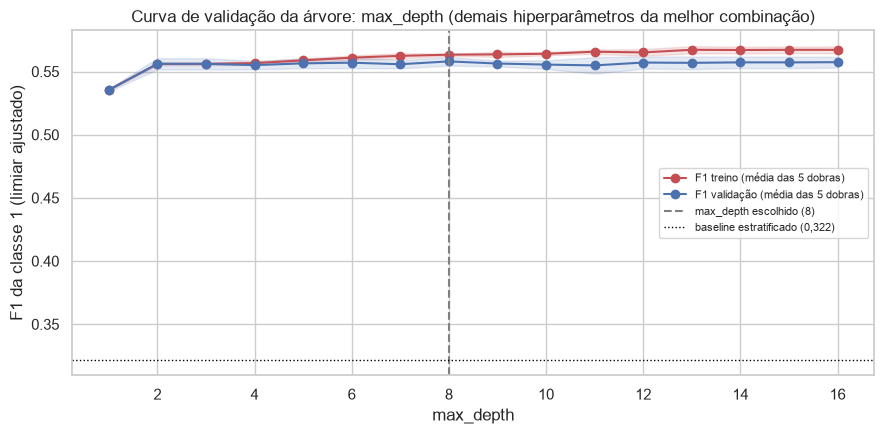

max_depth,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
F1 treino,0.5354,0.5561,0.5561,0.5566,0.5588,0.561,0.5624,0.5633,0.5636,0.5641,0.5657,0.5651,0.5672,0.5670,0.5672,0.5672
F1 validação,0.5354,0.5561,0.5561,0.5551,0.5565,0.557,0.5558,0.5580,0.5564,0.5555,0.5549,0.5571,0.5569,0.5573,0.5573,0.5574
gap,0.0000,-0.0000,-0.0000,0.0015,0.0024,0.004,0.0066,0.0053,0.0072,0.0086,0.0108,0.0080,0.0103,0.0098,0.0099,0.0098


In [63]:
PROFUNDIDADES = list(range(1, 17))
curva_tr, curva_val = validation_curve(
    clone(busca_arvore.best_estimator_), X_train, y_train,
    param_name="estimator__modelo__max_depth", param_range=PROFUNDIDADES,
    cv=cv_esquema, scoring="f1", n_jobs=-1,
)
prof_melhor = busca_arvore.best_params_["estimator__modelo__max_depth"]

fig, ax = plt.subplots(figsize=(9, 4.5))
for escores, rotulo, cor in [(curva_tr, "treino", "#C44E52"), (curva_val, "validação", "#4C72B0")]:
    m, s = escores.mean(axis=1), escores.std(axis=1)
    ax.plot(PROFUNDIDADES, m, marker="o", color=cor, label=f"F1 {rotulo} (média das 5 dobras)")
    ax.fill_between(PROFUNDIDADES, m - s, m + s, color=cor, alpha=0.15)
ax.axvline(prof_melhor, color="gray", linestyle="--", label=f"max_depth escolhido ({prof_melhor})")
ax.axhline(0.322, color="black", linestyle=":", linewidth=1, label="baseline estratificado (0,322)")
ax.set_xlabel("max_depth")
ax.set_ylabel("F1 da classe 1 (limiar ajustado)")
ax.set_title("Curva de validação da árvore: max_depth (demais hiperparâmetros da melhor combinação)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

tabela_curva_arvore = pd.DataFrame({"max_depth": PROFUNDIDADES,
                                    "F1 treino": curva_tr.mean(axis=1).round(4),
                                    "F1 validação": curva_val.mean(axis=1).round(4),
                                    "gap": (curva_tr.mean(axis=1) - curva_val.mean(axis=1)).round(4)})
tabela_curva_arvore.set_index("max_depth").T

**Leitura da curva:**

- Com `max_depth=1` (um único corte), o F1 já é 0,535. A partir de `max_depth=2`, a validação fica **praticamente plana** (entre 0,555 e 0,558), enquanto o treino sobe devagar. O gap cresce de 0,000 (profundidades 1 a 3) para cerca de 0,010 (profundidade 16): o overfitting aparece, mas é muito pequeno, porque `min_samples_leaf=100` impede folhas pequenas.
- Não há região de underfitting forte além de `max_depth=1`, nem de overfitting forte. O que limita o desempenho é o sinal das variáveis, não a complexidade da árvore.
- **Decisão da equipe:** ficar com a **melhor combinação** (`max_depth=8`). A regra de um desvio-padrão (escolher a árvore mais rasa dentro de um desvio da melhor, que aqui seria `max_depth=2`) foi considerada e não adotada. A explicabilidade da árvore será trabalhada na Fase 13 com as regras dos principais caminhos e a importância por permutação.

### 11.3 CatBoost: curvas de validação (profundidade × iterações)

Para não treinar um modelo por número de iterações, cada dobra é treinada **uma única vez** com 800 iterações (`learning_rate=0.1`), e a PR-AUC de treino e de validação é registrada a cada iteração. A dobra de validação só é **observada** (`use_best_model=False`): nada é escolhido dentro do ajuste, e a escolha é feita depois, olhando a média das 5 dobras, como numa curva de validação comum. As profundidades testadas são 4, 6 e 8, sem peso de classe (decisão da Fase 10).

In [64]:
# Curva de validação do CatBoost (estratégia (a): PR-AUC, que não depende do limiar). Cada dobra é treinada
# UMA vez com o número máximo de iterações, registrando a PR-AUC de treino e de validação a cada iteração.
# A dobra de validação só é observada (use_best_model=False): nada é escolhido dentro do ajuste.
ITER_MAX, PROFUNDIDADES_CB = 800, [4, 6, 8]


def curva_catboost_dobra(depth, idx_tr, idx_val):
    X_tr = preparar_catboost_nativo(X_train.iloc[idx_tr])
    X_va = preparar_catboost_nativo(X_train.iloc[idx_val])
    modelo = CatBoostClassifier(iterations=ITER_MAX, learning_rate=0.1, depth=depth, cat_features=tuple(CAT_CB),
                                custom_metric=["PRAUC:hints=skip_train~false"], use_best_model=False,
                                random_seed=RNG_SEED, thread_count=2, verbose=0, allow_writing_files=False)
    t0 = time.time()
    modelo.fit(X_tr, y_train.iloc[idx_tr], eval_set=(X_va, y_train.iloc[idx_val]))
    ev = modelo.get_evals_result()
    chave = next(k for k in ev["validation"] if k.startswith("PRAUC"))
    return {"depth": depth, "learn": np.array(ev["learn"][chave]),
            "val": np.array(ev["validation"][chave]), "tempo": time.time() - t0}


t0 = time.time()
curvas_cb = Parallel(n_jobs=5)(delayed(curva_catboost_dobra)(d, tr, va)
                               for d in PROFUNDIDADES_CB for tr, va in cv_esquema.split(X_train, y_train))
tempo_curvas_cb = time.time() - t0
print(f"{len(curvas_cb)} ajustes ({len(PROFUNDIDADES_CB)} profundidades × 5 dobras, {ITER_MAX} iterações) "
      f"em {tempo_curvas_cb / 60:.1f} min.")

15 ajustes (3 profundidades × 5 dobras, 800 iterações) em 2.7 min.


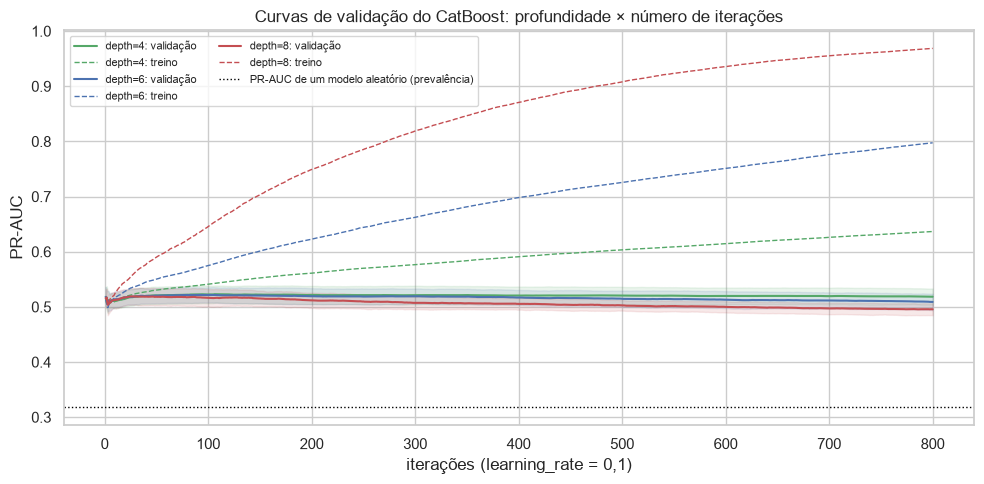

melhor da curva PR-AUC validação  PR-AUC treino  gap (treino − validação)
depth iterações                                                                           
4     50                   False    0.521 ± 0.016         0.5303                    0.0096
      100                  False    0.523 ± 0.016         0.5411                    0.0186
      108                   True    0.523 ± 0.016         0.5428                    0.0197
      200                  False    0.522 ± 0.016         0.5611                    0.0395
      300                  False    0.521 ± 0.017         0.5765                    0.0551
      500                  False    0.520 ± 0.016         0.6034                    0.0830
      800                  False    0.518 ± 0.015         0.6366                    0.1182
6     50                   False    0.520 ± 0.014         0.5503                    0.0300
      100                  False    0.522 ± 0.014         0.5748                    0.0532
      104                   True    0.522 ± 0.014         0.5771                    0.0553
      200                  False    0.519 ± 0.015         0.6229                    0.1036
      300                  False    0.519 ± 0.014         0.6625                    0.1433
      500                  False    0.515 ± 0.015         0.7258                    0.2112
      800                  False    0.509 ± 0.015         0.7974                    0.2885
8     26                    True    0.519 ± 0.015         0.5562                    0.0372
      50                   False    0.518 ± 0.016         0.5902                    0.0719
      100                  False    0.516 ± 0.016         0.6456                    0.1293
      200                  False    0.512 ± 0.014         0.7493                    0.2375
      300                  False    0.507 ± 0.012         0.8188                    0.3116
      500                  False    0.503 ± 0.010         0.9079                    0.4052
      800                  False    0.496 ± 0.011         0.9686                    0.4731

In [65]:
iteracoes = np.arange(1, ITER_MAX + 1)
resumo_cb = {}
fig, ax = plt.subplots(figsize=(10, 5))
cores = {4: "#55A868", 6: "#4C72B0", 8: "#C44E52"}
for d in PROFUNDIDADES_CB:
    learn = np.vstack([c["learn"] for c in curvas_cb if c["depth"] == d])
    val = np.vstack([c["val"] for c in curvas_cb if c["depth"] == d])
    resumo_cb[d] = {"learn": learn, "val": val}
    ax.plot(iteracoes, val.mean(axis=0), color=cores[d], label=f"depth={d}: validação")
    ax.fill_between(iteracoes, val.mean(axis=0) - val.std(axis=0), val.mean(axis=0) + val.std(axis=0),
                    color=cores[d], alpha=0.12)
    ax.plot(iteracoes, learn.mean(axis=0), color=cores[d], linestyle="--", linewidth=1, label=f"depth={d}: treino")
ax.axhline(y_train.mean(), color="black", linestyle=":", linewidth=1, label="PR-AUC de um modelo aleatório (prevalência)")
ax.set_xlabel("iterações (learning_rate = 0,1)")
ax.set_ylabel("PR-AUC")
ax.set_title("Curvas de validação do CatBoost: profundidade × número de iterações")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

PONTOS = [50, 100, 200, 300, 500, 800]
linhas_cb = []
for d in PROFUNDIDADES_CB:
    v, l = resumo_cb[d]["val"], resumo_cb[d]["learn"]
    melhor_it = int(v.mean(axis=0).argmax()) + 1
    for it in sorted(set(PONTOS + [melhor_it])):
        linhas_cb.append({"depth": d, "iterações": it, "melhor da curva": it == melhor_it,
                          "PR-AUC validação": media_dp(v[:, it - 1]),
                          "PR-AUC treino": round(l[:, it - 1].mean(), 4),
                          "gap (treino − validação)": round(l[:, it - 1].mean() - v[:, it - 1].mean(), 4)})
tabela_curvas_cb = pd.DataFrame(linhas_cb).set_index(["depth", "iterações"])
tabela_curvas_cb

**Leitura das curvas:**

- **A validação atinge o pico cedo e depois cai**, enquanto o treino continua subindo, o que é overfitting claro. Com `learning_rate=0.1`, o pico fica em cerca de 100 iterações nas profundidades 4 e 6 (PR-AUC de 0,523 e 0,522) e em cerca de 26 iterações na profundidade 8 (0,519).
- **Quanto mais profundo, mais rápido o CatBoost decora o treino:** com profundidade 8 e 800 iterações, a PR-AUC de treino chega a 0,97 e a de validação cai para 0,50.
- **A configuração fixa usada nas Fases 9 e 10 (profundidade 6, 300 iterações) já está depois do pico:** validação 0,519 contra 0,522 no pico, com gap de 0,14. Os resultados das Fases 9 e 10 continuam válidos, porque comparam estratégias com o mesmo modelo, mas esse modelo não está no melhor ponto.
- **Faixa para a busca da próxima rodada:** `depth` entre 4 e 6, algumas centenas de iterações no máximo (ou `learning_rate` menor com mais iterações), mais regularização (`l2_leaf_reg`). A grade final será avaliada pelo F1 com o limiar ajustado por dentro.

> **Nota (busca da Seção 11.5):** estas curvas usam a métrica `PRAUC` interna do CatBoost, que interpola a curva precisão–recall de outro jeito que a `average_precision_score` das Fases 9 e 10 e dá valores maiores, sobretudo nas primeiras iterações (muitos empates nas probabilidades). Os valores absolutos não são comparáveis com a PR-AUC das demais fases, e o pico muito cedo em `depth=8` (26 iterações) pode ser efeito disso. A conclusão qualitativa, que levou à faixa de busca (`depth` 4–6, poucas centenas de iterações, mais regularização), foi confirmada na Seção 11.5 com a `average_precision_score`.

### 11.4 Registro da Fase 11 (árvore e faixa do CatBoost)

In [66]:
# Registro das decisões da Fase 11 (árvore e faixa do CatBoost) no Quadro de Descarte e no Quadro de Decisões.
melhor_arvore_txt = ", ".join(f"{nome_curto(k)}={v}" for k, v in busca_arvore.best_params_.items())
f1_melhor = escores_por_dobra(cv_arvore, idx_melhor)
f1_fixa = escores_por_dobra(cv_arvore, idx_fase10)
gap_melhor = cv_arvore.loc[idx_melhor, "gap (treino − validação)"]
_, p_melhor_fixa = teste_nadeau_bengio(f1_melhor, f1_fixa, N_TR_DOBRA, N_VAL_DOBRA)

picos_cb = {d: (int(resumo_cb[d]["val"].mean(axis=0).argmax()) + 1, resumo_cb[d]["val"].mean(axis=0).max())
            for d in PROFUNDIDADES_CB}
picos_txt = "; ".join(f"depth {d}: pico {v:.3f} em {it} iterações" for d, (it, v) in picos_cb.items())
v_fixa = resumo_cb[6]["val"][:, 299].mean()
gap_fixa_cb = resumo_cb[6]["learn"][:, 299].mean() - v_fixa

registrar_auditoria("Fase 11", "Árvore: hiperparâmetros", melhor_arvore_txt,
                    f"Melhor F1 na busca em grade ({len(cv_arvore)} combinações): {media_dp(f1_melhor)}; gap {gap_melhor:.3f}.")
registrar_auditoria("Fase 11", "Árvore: min_samples_split", "Fora da grade",
                    "Só restringe quando passa de 2 x min_samples_leaf; sem efeito nos casos testados (célula de verificação).")
registrar_auditoria("Fase 11", "CatBoost: faixa da próxima busca", "depth 4–6, poucas centenas de iterações",
                    f"Curvas de PR-AUC (lr = 0,1): {picos_txt}; depois do pico a validação cai e o gap cresce.")

LINHAS_QUADRO_F11 = [
    {"Fase": "11", "Decisão": "Hiperparâmetros da árvore",
     "Alternativas testadas": f"Grade de {len(cv_arvore)} combinações (max_depth, min_samples_leaf, ccp_alpha, criterion)",
     "Evidência": (f"Melhor F1 {media_dp(f1_melhor)}, gap {gap_melhor:.3f}; contra a configuração fixa "
                   f"Δ = {(f1_melhor - f1_fixa).mean():+.4f} (p = {p_melhor_fixa:.2f}); curva de max_depth plana a partir de 2"),
     "Escolha final": f"{melhor_arvore_txt} (melhor F1; a regra de 1 desvio-padrão foi considerada e não adotada)"},
    {"Fase": "11", "Decisão": "Método de busca do CatBoost",
     "Alternativas testadas": "(a) PR-AUC e limiar ajustado no fim; (b) F1 com limiar ajustado por dentro",
     "Evidência": "(b) custa cerca de 4 vezes mais por candidato; a PR-AUC não depende do limiar (Fase 10)",
     "Escolha final": "(a) na busca ampla e (b) na grade final pequena"},
    {"Fase": "11", "Decisão": "Faixa da busca do CatBoost",
     "Alternativas testadas": f"depth {PROFUNDIDADES_CB} × 1 a {ITER_MAX} iterações (lr = 0,1)",
     "Evidência": f"{picos_txt}; configuração fixa (depth 6, 300 it.) já passou do pico (gap {gap_fixa_cb:.2f})",
     "Escolha final": "Buscar em depth 4–6 com poucas centenas de iterações, mais regularização (próxima rodada)"},
]
print("Árvore escolhida:", melhor_arvore_txt)
print("Picos do CatBoost:", picos_txt)

Árvore escolhida: ccp_alpha=0.0001, criterion=entropy, max_depth=8, min_samples_leaf=100
Picos do CatBoost: depth 4: pico 0.523 em 108 iterações; depth 6: pico 0.522 em 104 iterações; depth 8: pico 0.519 em 26 iterações


---
## Revisão do conjunto de preditores (comentários da Etapa 1)

Os comentários da Etapa 1 levantaram duas questões que afetam o conjunto de preditores da modelagem:

1. as 8 candidatas fora de H1–H6 (`Age`, `EdLevel`, `Employment`, `Country`, `Industry`, `AIThreat`, `AISent` e remuneração) são todas significativas na Fase 3; pelo critério das Fases 3 e 4, entrariam no conjunto;
2. a categoria `AIComplex = "I don't use AI tools for complex tasks / I don't know"` praticamente descreve o não uso, e `AIAcc`/`AIComplex` podem ser consequência do uso (Fase 3).

Em vez de aplicar o critério de forma automática, as duas questões são decididas por **experimento**, com o mesmo protocolo das Fases 8 a 10: mesmas 5 dobras (`cv_esquema`), F1 da classe 1 com o limiar ajustado (Fase 10) e teste de Nadeau-Bengio.

- **Árvore:** hiperparâmetros escolhidos na Fase 11.
- **CatBoost:** configuração fixa das Fases 9 e 10 (300 iterações, `learning_rate=0.1`, `depth=6`), porque a busca dele ainda não foi feita. Como na Seção 11.3, isso não invalida a comparação: os cenários são comparados com o mesmo modelo.

### R.1 Conjunto ampliado e filtros refeitos só no treino

As 8 candidatas são acrescentadas às mesmas linhas de treino. Seguindo a Seção 3 do enunciado, os testes da Fase 3 e o VIF iterativo da Fase 4 são refeitos **só no treino** para o conjunto de 17 variáveis.

In [67]:
# Conjunto ampliado: os 9 preditores atuais + as 8 candidatas da Fase 3, nas MESMAS linhas de treino.
CANDIDATAS = SECUNDARIAS_SIGNIFICATIVAS
VARS_9 = NUM_MODEL + TE_MODEL + OHE_SOURCE
VARS_17 = VARS_9 + CANDIDATAS
X_train_ext = base_modelagem.reset_index(drop=True).loc[X_train.index, VARS_17]
assert X_train_ext.index.equals(X_train.index) and X_train_ext[VARS_9].equals(X_train[VARS_9])

# Seção 3 aplicada às candidatas: testes refeitos só no treino (mesmos testes da Fase 3)
treino_ext = X_train_ext.assign(AIAgents_bin=y_train.values)
linhas_r1 = []
for v in CANDIDATAS:
    if v in CONTINUOUS:
        obs = treino_ext.dropna(subset=[v])
        tabela = pd.crosstab(pd.qcut(obs[v], 10, duplicates="drop"), obs["AIAgents_bin"])
        teste = "Qui-Quadrado por decis"
    else:
        s = treino_ext[v].astype(object).fillna("missing")
        if s.nunique() > 15:
            s = s.where(s.isin(s.value_counts().nlargest(15).index), "Outros_agrupado")
        tabela = pd.crosstab(s, treino_ext["AIAgents_bin"])
        teste = "Qui-Quadrado"
    linhas_r1.append({"variável": v, "teste (só treino)": teste, "p_valor": stats.chi2_contingency(tabela)[1],
                      "V de Cramér": round(cramers_v(tabela), 3)})
robustez_candidatas = pd.DataFrame(linhas_r1)
robustez_candidatas["significativo (p<0.05)"] = robustez_candidatas["p_valor"] < 0.05

# Fase 4 (VIF iterativo) refeita só no treino para os 17, com as regras da Etapa 1
# (log10 + z-score na remuneração, z-score nas demais numéricas, target encoding nas de alta cardinalidade,
# dummies com drop_first nas demais).
partes = []
for v in [v for v in VARS_17 if v in CONTINUOUS]:
    s = OutlierExtremoParaNA(k=3.0).fit_transform(X_train_ext[[v]])[v]
    s = s.fillna(s.median())
    if v == "ConvertedCompYearly":
        s = np.log10(s)
    partes.append(((s - s.mean()) / s.std()).rename(f"{v}_z"))
for v in [v for v in VARS_17 if v in HIGH_CARD]:
    partes.append(pd.Series(construir_target_encoder().fit_transform(X_train_ext[[v]].fillna("missing"), y_train).ravel(),
                            index=X_train_ext.index, name=f"{v}_target_enc"))
cat_17 = [v for v in VARS_17 if v in LOW_CARD]
partes.append(pd.get_dummies(X_train_ext[cat_17].astype(object).fillna("missing"), prefix=cat_17, drop_first=True).astype(float))
X_iter_17 = pd.concat(partes, axis=1).assign(const=1.0)
removidas_vif_17 = []
while True:
    rep = compute_vif(X_iter_17)
    if rep.iloc[0]["VIF"] <= 5:
        break
    removidas_vif_17.append({"coluna": rep.iloc[0]["variável"], "VIF": round(rep.iloc[0]["VIF"], 2)})
    X_iter_17 = X_iter_17.drop(columns=[rep.iloc[0]["variável"]])
colunas_17 = [c for c in X_iter_17.columns if c != "const"]

CONJ_9 = {"num": NUM_MODEL, "te": TE_MODEL, "ohe": OHE_SOURCE, "dummies": DUMMY_MODEL}
CONJ_17 = {
    "num": [v for v in VARS_17 if v in CONTINUOUS and f"{v}_z" in colunas_17],
    "te": [v for v in VARS_17 if v in HIGH_CARD and f"{v}_target_enc" in colunas_17],
    "dummies": [c for c in colunas_17 if any(c.startswith(f"{v}_") for v in cat_17)],
}
CONJ_17["ohe"] = [v for v in cat_17 if any(c.startswith(f"{v}_") for c in CONJ_17["dummies"])]

print("Candidatas significativas só no treino:", bool(robustez_candidatas["significativo (p<0.05)"].all()))
print("Remoções por VIF > 5 no conjunto de 17 (treino):", removidas_vif_17)
print(f"VIF máximo após as remoções: {compute_vif(X_iter_17)['VIF'].max():.2f}")
print(f"Conjunto de 17: {len(CONJ_17['num'] + CONJ_17['te'] + CONJ_17['ohe'])} variáveis, "
      f"{len(CONJ_17['num']) * 2 + len(CONJ_17['te']) + len(CONJ_17['dummies'])} colunas na árvore")
robustez_candidatas

Candidatas significativas só no treino: True
Remoções por VIF > 5 no conjunto de 17 (treino): [{'coluna': 'RemoteWork_missing', 'VIF': np.float64(29.33)}, {'coluna': 'OrgSize_missing', 'VIF': np.float64(12.38)}, {'coluna': 'EdLevel_Bachelor’s degree (B.A., B.S., B.Eng., etc.)', 'VIF': np.float64(8.46)}, {'coluna': 'Employment_Retired', 'VIF': np.float64(8.39)}]


VIF máximo após as remoções: 3.98
Conjunto de 17: 17 variáveis, 66 colunas na árvore


,variável,teste (só treino),p_valor,V de Cramér,significativo (p<0.05)
0,Age,Qui-Quadrado,1.458123e-09,0.052,True
1,EdLevel,Qui-Quadrado,6.578080e-05,0.039,True
2,Employment,Qui-Quadrado,2.241070e-06,0.042,True
3,Country,Qui-Quadrado,1.050569e-67,0.135,True
4,Industry,Qui-Quadrado,7.803017e-28,0.092,True
5,AIThreat,Qui-Quadrado,6.713960e-30,0.084,True
6,AISent,Qui-Quadrado,0.000000e+00,0.310,True
7,ConvertedCompYearly,Qui-Quadrado por decis,5.382667e-20,0.087,True


**Leitura:** as 8 candidatas continuam significativas usando só o treino (V de 0,04 a 0,31, praticamente os mesmos valores da Fase 3), então a exploração não dependeu das linhas de teste. O VIF iterativo nos 17 remove as mesmas duas colunas de ausência da Etapa 1 (`RemoteWork_missing` e `OrgSize_missing`) e duas dummies novas (`EdLevel` = "Bachelor's degree" e `Employment` = "Retired"); o VIF máximo final fica abaixo de 4. `WorkExp` não está entre as 17, porque já saiu na Fase 4.

In [68]:
# Construtores parametrizados pelo conjunto de variáveis. Reproduzem exatamente os pipelines das Fases 8 a 11:
# árvore com isBAD/'missing' (Fase 9), sem peso de classe e com o limiar ajustado (Fase 10), hiperparâmetros
# da busca da Fase 11; CatBoost nativo (Fase 9), sem peso e com limiar ajustado, na configuração fixa
# (a busca do CatBoost ainda não foi feita).
PARAMS_ARVORE = {nome_curto(k): v for k, v in busca_arvore.best_params_.items()}


def arvore_do_conjunto(cj):
    prep = ColumnTransformer([
        ("num", Pipeline([("outlier_para_na", OutlierExtremoParaNA(k=3.0)),
                          ("mediana", SimpleImputer(strategy="median"))]), cj["num"]),
        ("isbad", Pipeline([("outlier_para_na", OutlierExtremoParaNA(k=3.0)),
                            ("flag", MissingIndicator(features="all"))]), cj["num"]),
        ("target_enc", Pipeline([("missing", SimpleImputer(strategy="constant", fill_value="missing")),
                                 ("te", construir_target_encoder())]), cj["te"]),
        ("dummies", DummiesSelecionadas(cj["dummies"]), cj["ohe"]),
    ]).set_output(transform="pandas")
    modelo = DecisionTreeClassifier(class_weight=None, random_state=RNG_SEED, **PARAMS_ARVORE)
    return com_limiar_ajustado(Pipeline([("prep", prep), ("modelo", modelo)]))


def preparar_catboost_conjunto(X, num, cat):
    X = X[num + cat].copy()
    X[cat] = X[cat].astype(object).fillna("missing").astype(str)
    return X


def catboost_do_conjunto(cj):
    cat = cj["te"] + cj["ohe"]
    prep = FunctionTransformer(preparar_catboost_conjunto, kw_args={"num": cj["num"], "cat": cat})
    modelo = CatBoostClassifier(iterations=300, learning_rate=0.1, depth=6, auto_class_weights=None,
                                cat_features=tuple(cat), random_seed=RNG_SEED, thread_count=2,
                                verbose=0, allow_writing_files=False)
    return com_limiar_ajustado(Pipeline([("prep", prep), ("modelo", modelo)]))


CONSTRUTORES = {"Árvore": arvore_do_conjunto, "CatBoost": catboost_do_conjunto}


def avaliar_cenario(modelo, cj, X):
    return cross_validate(CONSTRUTORES[modelo](cj), X, y_train, cv=cv_esquema, scoring=avaliar_dobra, n_jobs=5)


def sem_variaveis(cj, variaveis):
    return {"num": [v for v in cj["num"] if v not in variaveis], "te": [v for v in cj["te"] if v not in variaveis],
            "ohe": [v for v in cj["ohe"] if v not in variaveis],
            "dummies": [c for c in cj["dummies"] if not any(c.startswith(f"{v}_") for v in variaveis)]}


def comparar(res_a, res_b, metrica="F1 | ajustado"):
    a, b = res_a[f"test_{metrica}"], res_b[f"test_{metrica}"]
    t, p = teste_nadeau_bengio(a, b, N_TR_DOBRA, N_VAL_DOBRA)
    return round((a - b).mean(), 4), round(t, 2), round(p, 4)

print("Hiperparâmetros da árvore (Fase 11):", PARAMS_ARVORE)

Hiperparâmetros da árvore (Fase 11): {'ccp_alpha': 0.0001, 'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 100}


### R.2 Experimento: 9 × 17 preditores

Além dos conjuntos de 9 e de 17, testamos o de 16 (os 17 sem `AISent`), para separar o efeito de `AISent`, a candidata mais forte e a única que é uma percepção sobre IA.

In [69]:
CENARIOS_CONJ = {"9 (atual)": CONJ_9, "17 (atual + 8 candidatas)": CONJ_17,
                 "16 (17 sem AISent)": sem_variaveis(CONJ_17, ["AISent"])}
t0 = time.time()
res_conj = {(m, n): avaliar_cenario(m, cj, X_train_ext) for m in CONSTRUTORES for n, cj in CENARIOS_CONJ.items()}
print(f"{len(res_conj)} cenários × 5 dobras avaliados em {(time.time() - t0) / 60:.1f} min.")

# Conferência: com os 9 preditores, os construtores reproduzem a Fase 11 (árvore) e a Fase 10 (CatBoost, nível 2)
print(f"Reprodução — árvore: {media_dp(res_conj[('Árvore', '9 (atual)')]['test_F1 | ajustado'])} "
      f"(Fase 11: {media_dp(escores_por_dobra(cv_arvore, idx_melhor))}); "
      f"CatBoost: {media_dp(res_conj[('CatBoost', '9 (atual)')]['test_F1 | ajustado'])} "
      f"(Fase 10: {media_dp(escores_desbal[('CatBoost', N2)]['F1'])})")


def tabela_cenarios(res):
    return pd.DataFrame([
        {"Modelo": m, "Cenário": n,
         "F1 (limiar ajustado)": media_dp(r["test_F1 | ajustado"]), "Recall": media_dp(r["test_Recall | ajustado"]),
         "Precisão": media_dp(r["test_Precisão | ajustado"]), "PR-AUC": media_dp(r["test_PR-AUC"])}
        for (m, n), r in res.items()]).set_index(["Modelo", "Cenário"])


def tabela_testes(res, pares):
    linhas = []
    for m in CONSTRUTORES:
        for a, b in pares:
            d_f1, t_f1, p_f1 = comparar(res[(m, a)], res[(m, b)])
            d_pr, _, p_pr = comparar(res[(m, a)], res[(m, b)], "PR-AUC")
            linhas.append({"Modelo": m, "Comparação": f"{a}  −  {b}", "Δ F1": d_f1, "t corrigido (F1)": t_f1,
                           "p (F1)": p_f1, "Δ PR-AUC": d_pr, "p (PR-AUC)": p_pr})
    return pd.DataFrame(linhas)


display(tabela_cenarios(res_conj))
teste_conj = tabela_testes(res_conj, [("17 (atual + 8 candidatas)", "9 (atual)"), ("16 (17 sem AISent)", "9 (atual)"),
                                      ("17 (atual + 8 candidatas)", "16 (17 sem AISent)")])
with pd.option_context("display.max_colwidth", None):
    display(teste_conj)

6 cenários × 5 dobras avaliados em 4.2 min.
Reprodução — árvore: 0.558 ± 0.003 (Fase 11: 0.558 ± 0.003); CatBoost: 0.561 ± 0.002 (Fase 10: 0.561 ± 0.002)


F1 (limiar ajustado)         Recall       Precisão         PR-AUC
Modelo   Cenário                                                                                    
Árvore   9 (atual)                        0.558 ± 0.003  0.880 ± 0.013  0.409 ± 0.005  0.490 ± 0.009
         17 (atual + 8 candidatas)        0.559 ± 0.006  0.857 ± 0.042  0.416 ± 0.009  0.498 ± 0.009
         16 (17 sem AISent)               0.554 ± 0.004  0.864 ± 0.038  0.409 ± 0.010  0.494 ± 0.017
CatBoost 9 (atual)                        0.561 ± 0.002  0.812 ± 0.025  0.429 ± 0.008  0.520 ± 0.014
         17 (atual + 8 candidatas)        0.570 ± 0.004  0.841 ± 0.020  0.431 ± 0.005  0.535 ± 0.015
         16 (17 sem AISent)               0.567 ± 0.006  0.835 ± 0.018  0.429 ± 0.006  0.529 ± 0.018

,Modelo,Comparação,Δ F1,t corrigido (F1),p (F1),Δ PR-AUC,p (PR-AUC)
0,Árvore,17 (atual + 8 candidatas) − 9 (atual),0.0014,0.27,0.8019,0.0077,0.0372
1,Árvore,16 (17 sem AISent) − 9 (atual),-0.0037,-0.88,0.4286,0.0038,0.5969
2,Árvore,17 (atual + 8 candidatas) − 16 (17 sem AISent),0.0050,1.13,0.3221,0.0039,0.5803
3,CatBoost,17 (atual + 8 candidatas) − 9 (atual),0.0082,3.74,0.0201,0.0158,0.0479
4,CatBoost,16 (17 sem AISent) − 9 (atual),0.0053,1.54,0.1982,0.0098,0.2778
5,CatBoost,17 (atual + 8 candidatas) − 16 (17 sem AISent),0.0029,1.05,0.3538,0.0061,0.0716


**Leitura:**

- **Árvore:** os 17 preditores não melhoram o F1 (+0,001, p = 0,80). A PR-AUC sobe um pouco (+0,008, p = 0,04), mas a métrica principal é o F1.
- **CatBoost:** ganho pequeno e significativo (+0,008 de F1, p = 0,02). Sem `AISent`, o ganho cai para +0,005 e deixa de ser significativo (p = 0,20): a melhora vem quase toda de `AISent`, uma percepção sobre IA com o mesmo risco de causalidade reversa da H3.
- As outras sete candidatas (país, setor, remuneração, idade, escolaridade, vínculo de trabalho e percepção de ameaça) não acrescentam desempenho mensurável a nenhum dos dois modelos.

### R.3 Variáveis de percepção: tratamento da categoria e sensibilidade

No conjunto de 9 preditores, comparamos com o original:

| Cenário | O que muda | O que mede |
|---|---|---|
| P1: categoria → ausente | "I don't use AI tools…" vira NA | se marcar como ausente basta para neutralizar a categoria |
| P1b: categoria → nível neutro | "I don't use AI tools…" vira "Neither good or bad…" | quanto do desempenho vem da parte que descreve o não uso |
| P2: sem `AIComplex` | variável retirada | quanto o modelo depende de `AIComplex` |
| P3: sem `AIAcc` e `AIComplex` | as duas percepções da H3 retiradas | sensibilidade à causalidade reversa (Risco 4 da ficha) |

As recodificações são regras fixas, sem nada aprendido com os dados, aplicadas antes do pipeline.

In [70]:
NIVEL_NEUTRO = "Neither good or bad at handling complex tasks"


def recodificar_categoria(X, novo_valor):
    X = X.copy()
    X.loc[X["AIComplex"] == NAO_USA_COMPLEX, "AIComplex"] = novo_valor
    return X


CENARIOS_PERC = {
    "P1: categoria → ausente": (CONJ_9, recodificar_categoria(X_train_ext, np.nan)),
    "P1b: categoria → nível neutro": (CONJ_9, recodificar_categoria(X_train_ext, NIVEL_NEUTRO)),
    "P2: sem AIComplex": (sem_variaveis(CONJ_9, ["AIComplex"]), X_train_ext),
    "P3: sem AIAcc e AIComplex": (sem_variaveis(CONJ_9, ["AIAcc", "AIComplex"]), X_train_ext),
}
t0 = time.time()
res_perc = {}
for m in CONSTRUTORES:
    res_perc[(m, "P0: original")] = res_conj[(m, "9 (atual)")]
    for nome, (cj, X) in CENARIOS_PERC.items():
        res_perc[(m, nome)] = avaliar_cenario(m, cj, X)
print(f"{len(CENARIOS_PERC) * len(CONSTRUTORES)} cenários × 5 dobras avaliados em {(time.time() - t0) / 60:.1f} min.")

display(tabela_cenarios(res_perc))
teste_perc = tabela_testes(res_perc, [(n, "P0: original") for n in CENARIOS_PERC])
with pd.option_context("display.max_colwidth", None):
    display(teste_perc)

8 cenários × 5 dobras avaliados em 4.4 min.


F1 (limiar ajustado)         Recall       Precisão         PR-AUC
Modelo   Cenário                                                                                        
Árvore   P0: original                         0.558 ± 0.003  0.880 ± 0.013  0.409 ± 0.005  0.490 ± 0.009
         P1: categoria → ausente              0.557 ± 0.003  0.877 ± 0.017  0.408 ± 0.004  0.490 ± 0.009
         P1b: categoria → nível neutro        0.542 ± 0.006  0.865 ± 0.015  0.395 ± 0.008  0.488 ± 0.009
         P2: sem AIComplex                    0.525 ± 0.004  0.793 ± 0.042  0.393 ± 0.013  0.455 ± 0.014
         P3: sem AIAcc e AIComplex            0.486 ± 0.001  0.936 ± 0.026  0.328 ± 0.003  0.388 ± 0.014
CatBoost P0: original                         0.561 ± 0.002  0.812 ± 0.025  0.429 ± 0.008  0.520 ± 0.014
         P1: categoria → ausente              0.561 ± 0.003  0.817 ± 0.025  0.428 ± 0.008  0.520 ± 0.016
         P1b: categoria → nível neutro        0.545 ± 0.004  0.780 ± 0.039  0.419 ± 0.009  0.510 ± 0.015
         P2: sem AIComplex                    0.533 ± 0.003  0.788 ± 0.023  0.403 ± 0.005  0.486 ± 0.016
         P3: sem AIAcc e AIComplex            0.489 ± 0.004  0.885 ± 0.046  0.338 ± 0.004  0.421 ± 0.015

,Modelo,Comparação,Δ F1,t corrigido (F1),p (F1),Δ PR-AUC,p (PR-AUC)
0,Árvore,P1: categoria → ausente − P0: original,-0.0015,-1.28,0.2706,-0.0003,0.6874
1,Árvore,P1b: categoria → nível neutro − P0: original,-0.0163,-2.83,0.0475,-0.0018,0.6054
2,Árvore,P2: sem AIComplex − P0: original,-0.0332,-14.66,0.0001,-0.0347,0.0049
3,Árvore,P3: sem AIAcc e AIComplex − P0: original,-0.0720,-24.44,0.0000,-0.1022,0.0000
4,CatBoost,P1: categoria → ausente − P0: original,0.0001,0.04,0.9685,0.0008,0.8362
5,CatBoost,P1b: categoria → nível neutro − P0: original,-0.0167,-4.45,0.0113,-0.0092,0.1107
6,CatBoost,P2: sem AIComplex − P0: original,-0.0280,-7.84,0.0014,-0.0336,0.0000
7,CatBoost,P3: sem AIAcc e AIComplex − P0: original,-0.0726,-22.47,0.0000,-0.0982,0.0001


**Leitura:**

- **Marcar a categoria como ausente não a neutraliza (P1).** O F1 fica igual ao original nos dois modelos. Com a estratégia isBAD/`'missing'` da Fase 9, as 3.833 pessoas dessa categoria passam a dominar o nível `'missing'` de `AIComplex`, que antes tinha 90, e o modelo continua separando o grupo, só que com outro nome.
- **Juntar a categoria ao nível neutro custa cerca de 0,016 de F1 (P1b):** −0,016 na árvore (p = 0,05) e −0,017 no CatBoost (p = 0,01). É o tamanho da parte do desempenho que vinha da categoria que descreve o não uso.
- **Retirar `AIComplex` custa o dobro (P2):** cerca de −0,03 nos dois modelos (p ≤ 0,001).
- **Sem as duas percepções da H3 (P3), o F1 cai cerca de 0,07**, para 0,486 (árvore) e 0,489 (CatBoost), abaixo da meta de 0,50 da Fase 6, embora bem acima do baseline estratificado (0,322). O modelo **depende fortemente** das percepções sobre IA.

### R.4 Decisões

1. **Conjunto: mantidos os 9 preditores** (decisão da equipe). A árvore não ganha nada com os 17; o ganho do CatBoost é pequeno e vem quase todo de `AISent`, que tem o mesmo risco de validade da H3; e o critério é o mesmo das Fases 9 e 10 (diferença desprezível → o mais simples). Adotar os 17 obrigaria ainda a refazer as Fases 8 a 11 e traria `Country` (169 níveis) e a remuneração (47% de ausência). As 8 candidatas saem do conjunto, com o motivo registrado no Quadro de Descarte.
2. **Categoria "I don't use AI tools for complex tasks": juntada ao nível neutro** (decisão da equipe). É a mesma lógica do descarte de `AISelect`: a categoria praticamente declara o não uso. Neutralizá-la custa cerca de 0,016 de F1, metade do custo de retirar `AIComplex`, e preserva a escala ordinal de quem usa IA. A opção "→ ausente" foi descartada, porque não neutraliza nada com a estratégia isBAD/`'missing'`.
   - **Alcance:** a recodificação vale **daqui em diante** (Fase 11 restante e Fase 12). As Fases 8 a 10 continuam válidas, porque comparam estratégias com a mesma base (mesmo argumento da Seção 11.3), e os hiperparâmetros da árvore são mantidos, porque a curva de `max_depth` é plana.
   - **Nova referência de F1 (validação cruzada no treino):** árvore 0,542 ± 0,006 e CatBoost 0,545 ± 0,004.
3. **`AIAcc` e `AIComplex` mantidas, com ressalva** (decisão da equipe). São o sinal mais forte da base e estão disponíveis no momento da decisão (questionário). A dependência do modelo em relação a elas (−0,07 de F1 sem as duas) fica registrada como limitação no relatório e na explicabilidade (Fase 13).

In [71]:
# Decisões da revisão do conjunto (justificativa na Seção R.4)
CONJUNTO_FINAL = CONJ_9
X_train_final = recodificar_categoria(X_train, NIVEL_NEUTRO)
X_test_final = recodificar_categoria(X_test, NIVEL_NEUTRO)  # regra fixa; o teste segue lacrado até a Fase 12
ref_final = {m: res_perc[(m, "P1b: categoria → nível neutro")]["test_F1 | ajustado"] for m in CONSTRUTORES}
print(f"Conjunto final: {len(VARS_9)} variáveis -> {VARS_9}")
print(f"Categoria '{NAO_USA_COMPLEX}' -> '{NIVEL_NEUTRO}' "
      f"({(X_train['AIComplex'] == NAO_USA_COMPLEX).sum()} linhas no treino)")
print("Nova referência de F1 (treino, 5 dobras):", {m: media_dp(v) for m, v in ref_final.items()})


def valor_teste(tabela, modelo, comparacao, coluna):
    return tabela.loc[(tabela["Modelo"] == modelo) & (tabela["Comparação"] == comparacao), coluna].iloc[0]


def p_curto(p):
    # p-valores muito pequenos aparecem como "p < 0.001" (antes saíam arredondados para "p = 0.00")
    return "p < 0.001" if p < 0.001 else (f"p = {p:.3f}" if p < 0.01 else f"p = {p:.2f}")


def delta_p(tabela, modelo, comparacao):
    return (f"{valor_teste(tabela, modelo, comparacao, 'Δ F1'):+.3f} "
            f"({p_curto(valor_teste(tabela, modelo, comparacao, 'p (F1)'))})")


C17 = "17 (atual + 8 candidatas)  −  9 (atual)"
C16 = "16 (17 sem AISent)  −  9 (atual)"
P = {n: f"{n}  −  P0: original" for n in CENARIOS_PERC}
for v in CANDIDATAS:
    registrar_auditoria("Revisão do conjunto", v, "Descartada (experimento 9 × 17)",
                        f"17 − 9: Δ F1 = {delta_p(teste_conj, 'Árvore', C17)} na árvore e "
                        f"{delta_p(teste_conj, 'CatBoost', C17)} no CatBoost; sem AISent, "
                        f"{delta_p(teste_conj, 'CatBoost', C16)} no CatBoost.")
registrar_auditoria("Revisão do conjunto", "AIComplex ('I don't use AI tools…')", "Juntada ao nível neutro",
                    f"Descreve o não uso; neutralizar custa {delta_p(teste_perc, 'Árvore', P['P1b: categoria → nível neutro'])} "
                    f"(árvore) e {delta_p(teste_perc, 'CatBoost', P['P1b: categoria → nível neutro'])} (CatBoost) de F1; "
                    "'→ ausente' não neutraliza.")
registrar_auditoria("Revisão do conjunto", "AIAcc e AIComplex", "Mantidas com ressalva",
                    f"Sem as duas, Δ F1 = {delta_p(teste_perc, 'Árvore', P['P3: sem AIAcc e AIComplex'])} (árvore) e "
                    f"{delta_p(teste_perc, 'CatBoost', P['P3: sem AIAcc e AIComplex'])} (CatBoost); limitação registrada.")

LINHAS_QUADRO_REV = [
    {"Fase": "Revisão", "Decisão": "Conjunto de preditores",
     "Alternativas testadas": "9 (atual) × 17 (+ 8 candidatas da Fase 3) × 16 (17 sem AISent)",
     "Evidência": (f"17 − 9: árvore {delta_p(teste_conj, 'Árvore', C17)}, CatBoost {delta_p(teste_conj, 'CatBoost', C17)}; "
                   f"16 − 9 no CatBoost: {delta_p(teste_conj, 'CatBoost', C16)}"),
     "Escolha final": "9 preditores (ganho desprezível na árvore; no CatBoost, o ganho vem de AISent)"},
    {"Fase": "Revisão", "Decisão": "Categoria 'I don't use AI tools for complex tasks'",
     "Alternativas testadas": "Original × → ausente × → nível neutro × sem AIComplex",
     "Evidência": "; ".join(f"{n.split(':')[0]}: árvore {delta_p(teste_perc, 'Árvore', P[n])}, "
                            f"CatBoost {delta_p(teste_perc, 'CatBoost', P[n])}" for n in list(P)[:3]),
     "Escolha final": "Nível neutro, da Fase 11 restante em diante (coerente com o descarte de AISelect)"},
    {"Fase": "Revisão", "Decisão": "Sensibilidade às percepções (AIAcc, AIComplex)",
     "Alternativas testadas": "Com × sem as duas",
     "Evidência": (f"Sem as duas: F1 {media_dp(res_perc[('Árvore', 'P3: sem AIAcc e AIComplex')]['test_F1 | ajustado'])} (árvore) e "
                   f"{media_dp(res_perc[('CatBoost', 'P3: sem AIAcc e AIComplex')]['test_F1 | ajustado'])} (CatBoost)"),
     "Escolha final": "Mantidas, com a dependência registrada como limitação"},
]

Conjunto final: 9 variáveis -> ['YearsCode', 'JobSat', 'DevType', 'OrgSize', 'ICorPM', 'RemoteWork', 'SOVisitFreq', 'AIAcc', 'AIComplex']
Categoria 'I don't use AI tools for complex tasks / I don't know' -> 'Neither good or bad at handling complex tasks' (3112 linhas no treino)
Nova referência de F1 (treino, 5 dobras): {'Árvore': '0.542 ± 0.006', 'CatBoost': '0.545 ± 0.004'}


---
## Fase 11 (continuação) — CatBoost: busca de hiperparâmetros

A busca é feita **depois** da revisão do conjunto de preditores, sobre `X_train_final` (9 preditores, categoria "I don't use AI tools…" no nível neutro), com as mesmas 5 dobras. Segue o método registrado na Fase 11:

1. **Exploração ampla pela PR-AUC (11.5).** Grade de `depth` ∈ {4, 5, 6} (faixa definida na Seção 11.3) × `l2_leaf_reg` ∈ {1, 3, 10, 30} (regularização), com `learning_rate = 0,05` (menor que o 0,1 da Seção 11.3, para que o pico não fique nas primeiras dezenas de iterações) e até 800 iterações. Cada combinação é treinada uma vez por dobra, e o número de iterações sai da curva média de validação.
2. **Grade final pelo F1 com o limiar ajustado por dentro (11.6)**, nos 4 melhores candidatos da exploração, com o gap treino–validação. A configuração fixa das Fases 9 e 10 entra na mesma grade como referência.

> **Nota sobre a métrica:** a PR-AUC é calculada com `average_precision_score`, a mesma das Fases 9 e 10, sobre as previsões acumuladas a cada 10 iterações. A métrica `PRAUC` interna do CatBoost, usada nas curvas da Seção 11.3, interpola a curva precisão–recall de outro jeito e dá valores maiores, sobretudo nas primeiras iterações, quando as probabilidades têm muitos empates. Num primeiro teste desta busca, ela chegou a apontar o pico na 1ª iteração para `depth=4`.

### 11.5 Exploração ampla pela PR-AUC

In [72]:
# Etapa 1 — exploração ampla pela PR-AUC (estratégia (a) da Fase 11). Cada combinação é treinada UMA vez por
# dobra com o máximo de iterações; a PR-AUC (average_precision_score, a mesma das Fases 9 e 10) é calculada nas
# previsões acumuladas a cada 10 iterações (staged_predict_proba). A dobra de validação só é observada: o
# número de iterações sai da curva média das 5 dobras, como numa curva de validação comum.
# Obs.: a métrica PRAUC interna do CatBoost interpola a curva de outro jeito e dá valores maiores, sobretudo
# nas primeiras iterações, quando as probabilidades têm muitos empates; por isso não é usada aqui.
import itertools

GRADE_CB = {"depth": [4, 5, 6], "l2_leaf_reg": [1, 3, 10, 30]}
LR_CB, ITER_MAX_CB, PASSO_CB = 0.05, 800, 10
ITERACOES_CB = np.arange(PASSO_CB, ITER_MAX_CB + 1, PASSO_CB)
CAT_FINAL = CONJUNTO_FINAL["te"] + CONJUNTO_FINAL["ohe"]


def curva_cb_config(depth, l2, idx_tr, idx_val):
    num = CONJUNTO_FINAL["num"]
    X_tr = preparar_catboost_conjunto(X_train_final.iloc[idx_tr], num, CAT_FINAL)
    X_va = preparar_catboost_conjunto(X_train_final.iloc[idx_val], num, CAT_FINAL)
    y_tr, y_va = y_train.iloc[idx_tr], y_train.iloc[idx_val]
    modelo = CatBoostClassifier(iterations=ITER_MAX_CB, learning_rate=LR_CB, depth=depth, l2_leaf_reg=l2,
                                cat_features=tuple(CAT_FINAL), random_seed=RNG_SEED, thread_count=2, verbose=0,
                                allow_writing_files=False)
    modelo.fit(X_tr, y_tr)
    def curva(X, y):
        return np.array([average_precision_score(y, p[:, 1]) for p in modelo.staged_predict_proba(X, eval_period=PASSO_CB)])
    return {"depth": depth, "l2_leaf_reg": l2, "learn": curva(X_tr, y_tr), "val": curva(X_va, y_va)}


COMBOS_CB = list(itertools.product(GRADE_CB["depth"], GRADE_CB["l2_leaf_reg"]))
t0 = time.time()
curvas_busca_cb = Parallel(n_jobs=5)(delayed(curva_cb_config)(d, l2, tr, va)
                                     for d, l2 in COMBOS_CB for tr, va in cv_esquema.split(X_train_final, y_train))
tempo_busca_cb = time.time() - t0

linhas = []
for d, l2 in COMBOS_CB:
    val = np.vstack([c["val"] for c in curvas_busca_cb if (c["depth"], c["l2_leaf_reg"]) == (d, l2)])
    learn = np.vstack([c["learn"] for c in curvas_busca_cb if (c["depth"], c["l2_leaf_reg"]) == (d, l2)])
    k = int(val.mean(axis=0).argmax())
    linhas.append({"depth": d, "l2_leaf_reg": l2, "iterações (pico)": int(ITERACOES_CB[k]),
                   "PR-AUC validação (pico)": val[:, k].mean(), "dp": val[:, k].std(),
                   "PR-AUC treino (pico)": learn[:, k].mean(),
                   "gap no pico": learn[:, k].mean() - val[:, k].mean(),
                   f"PR-AUC validação ({ITER_MAX_CB} it.)": val[:, -1].mean()})
busca_cb = pd.DataFrame(linhas).sort_values("PR-AUC validação (pico)", ascending=False).reset_index(drop=True)
print(f"{len(COMBOS_CB)} combinações × 5 dobras ({ITER_MAX_CB} iterações, lr = {LR_CB}) em {tempo_busca_cb / 60:.1f} min.")
busca_cb.round(4)

12 combinações × 5 dobras (800 iterações, lr = 0.05) em 8.4 min.


,depth,l2_leaf_reg,iterações (pico),PR-AUC validação (pico),dp,PR-AUC treino (pico),gap no pico,PR-AUC validação (800 it.)
0,6,30,380,0.5174,0.0174,0.5568,0.0394,0.5153
1,5,1,540,0.5169,0.0180,0.5615,0.0446,0.5153
2,4,30,370,0.5166,0.0170,0.5405,0.0239,0.5158
3,4,3,200,0.5165,0.0162,0.5341,0.0177,0.5157
4,5,3,320,0.5164,0.0172,0.5502,0.0338,0.5145
5,5,30,360,0.5164,0.0171,0.5473,0.0309,0.5147
6,5,10,320,0.5163,0.0175,0.5479,0.0315,0.5139
7,4,1,290,0.5158,0.0177,0.5399,0.0241,0.5154
8,4,10,530,0.5158,0.0169,0.5468,0.0310,0.5150
9,6,10,330,0.5155,0.0177,0.5581,0.0427,0.5141


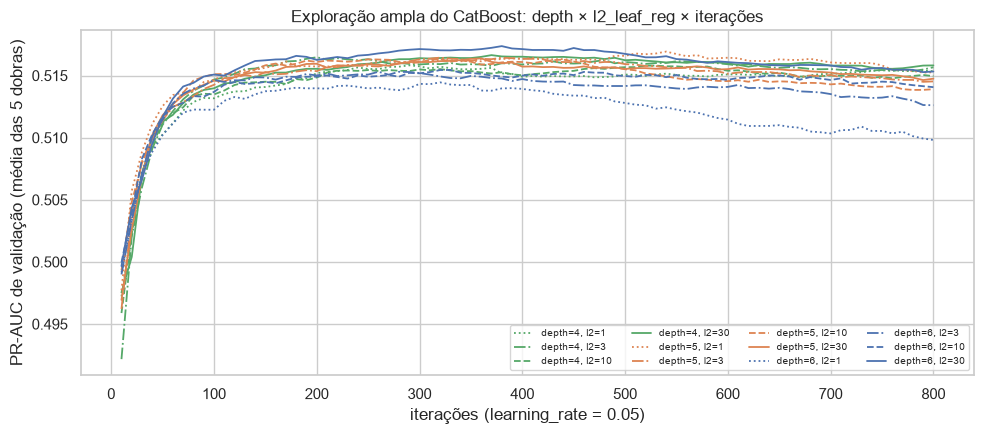

In [73]:
fig, ax = plt.subplots(figsize=(10, 4.5))
cores = {4: "#55A868", 5: "#DD8452", 6: "#4C72B0"}
estilos = {1: ":", 3: "-.", 10: "--", 30: "-"}
for d, l2 in COMBOS_CB:
    val = np.vstack([c["val"] for c in curvas_busca_cb if (c["depth"], c["l2_leaf_reg"]) == (d, l2)]).mean(axis=0)
    ax.plot(ITERACOES_CB, val, color=cores[d], linestyle=estilos[l2], linewidth=1.3, label=f"depth={d}, l2={l2}")
ax.set_xlabel(f"iterações (learning_rate = {LR_CB})")
ax.set_ylabel("PR-AUC de validação (média das 5 dobras)")
ax.set_title("Exploração ampla do CatBoost: depth × l2_leaf_reg × iterações")
ax.legend(ncol=4, fontsize=7)
plt.tight_layout()
plt.show()

**Leitura da exploração:**

- **O desempenho é praticamente plano na grade:** as 12 combinações ficam entre 0,514 e 0,517 de PR-AUC no pico, uma faixa bem menor que o desvio-padrão entre dobras (≈ 0,017). Nenhum hiperparâmetro muda o resultado de forma relevante.
- **O pico vem entre 200 e 540 iterações** (com `learning_rate = 0,05`), e depois a validação cai devagar até 800 iterações, enquanto o treino continua subindo.
- **Regularização e profundidade controlam o gap:** no pico, ele vai de 0,018 (`depth=4`, `l2_leaf_reg=3`) a 0,050 (`depth=6`, `l2_leaf_reg=1`).
- Como na árvore (Seção 11.2), o que limita o desempenho é o sinal das 9 variáveis, não a configuração do modelo.

### 11.6 Grade final pelo F1 com o limiar ajustado

Os 4 melhores candidatos da exploração, com o número de iterações do pico, são avaliados pelo F1 com o limiar ajustado por dentro (Fase 10), com `return_train_score=True` para medir o gap. A configuração fixa das Fases 9 e 10 (`depth=6`, `l2_leaf_reg=3`, 300 iterações, `learning_rate=0.1`) entra como referência.

**Critério de escolha:** o maior F1 de validação. Se houver empate (diferença menor que 0,001), fica o candidato de **menor gap**, pelo mesmo critério de parcimônia das Fases 9 e 10.

In [74]:
# Etapa 2 — grade final pelo F1 com o limiar ajustado por dentro (estratégia (b)), nos 4 melhores candidatos
# da etapa 1, com o gap treino–validação. Referência: configuração fixa das Fases 9–10 sobre a mesma base.
N_CANDIDATOS_CB = 4


def catboost_config(depth, l2_leaf_reg, iterations, learning_rate=LR_CB):
    prep = FunctionTransformer(preparar_catboost_conjunto, kw_args={"num": CONJUNTO_FINAL["num"], "cat": CAT_FINAL})
    modelo = CatBoostClassifier(iterations=iterations, learning_rate=learning_rate, depth=depth,
                                l2_leaf_reg=l2_leaf_reg, cat_features=tuple(CAT_FINAL), random_seed=RNG_SEED,
                                thread_count=2, verbose=0, allow_writing_files=False)
    return com_limiar_ajustado(Pipeline([("prep", prep), ("modelo", modelo)]))


candidatos_cb = busca_cb.head(N_CANDIDATOS_CB)
t0 = time.time()
res_cb_final = {}
NOME_FIXA = "Referência: configuração fixa (depth=6, l2_leaf_reg=3, 300 it., lr 0.1)"
CFG_FIXA = {"depth": 6, "l2_leaf_reg": 3.0, "iterations": 300, "learning_rate": 0.1}
res_cb_final[NOME_FIXA] = (CFG_FIXA, cross_validate(catboost_config(**CFG_FIXA), X_train_final, y_train, cv=cv_esquema,
                                                    scoring=avaliar_dobra, return_train_score=True, n_jobs=5))
for _, c in candidatos_cb.iterrows():
    cfg = {"depth": int(c["depth"]), "l2_leaf_reg": float(c["l2_leaf_reg"]), "iterations": int(c["iterações (pico)"])}
    nome = f"depth={cfg['depth']}, l2_leaf_reg={cfg['l2_leaf_reg']:g}, {cfg['iterations']} it. (lr {LR_CB})"
    res_cb_final[nome] = (cfg, cross_validate(catboost_config(**cfg), X_train_final, y_train, cv=cv_esquema,
                                              scoring=avaliar_dobra, return_train_score=True, n_jobs=5))
tempo_final_cb = time.time() - t0

print(f"{len(res_cb_final)} configurações × 5 dobras avaliadas em {tempo_final_cb / 60:.1f} min.")

5 configurações × 5 dobras avaliadas em 5.6 min.


In [75]:
ref_fixa = res_cb_final[NOME_FIXA][1]
ref_arvore = res_perc[("Árvore", "P1b: categoria → nível neutro")]  # árvore da Fase 11 sobre a mesma base


def gap_f1(r):
    return r["train_F1 | ajustado"].mean() - r["test_F1 | ajustado"].mean()


def dp_txt(r, ref):
    d, _, p = comparar(r, ref)
    return f"{d:+.4f} (p = {p:.3f})"


linhas = []
for nome, (cfg, r) in res_cb_final.items():
    linhas.append({
        "Configuração": nome, "F1 validação": media_dp(r["test_F1 | ajustado"]),
        "F1 treino": media_dp(r["train_F1 | ajustado"]), "gap F1": round(gap_f1(r), 4),
        "PR-AUC validação": media_dp(r["test_PR-AUC"]),
        "gap PR-AUC": round(r["train_PR-AUC"].mean() - r["test_PR-AUC"].mean(), 4),
        "limiar": media_dp(r["test_limiar"]), "Recall": media_dp(r["test_Recall | ajustado"]),
        "Precisão": media_dp(r["test_Precisão | ajustado"]), "treino (s/dobra)": round(r["fit_time"].mean(), 1),
        "Δ F1 vs fixa": "—" if nome == NOME_FIXA else dp_txt(r, ref_fixa),
        "Δ F1 vs árvore": dp_txt(r, ref_arvore),
    })
grade_final_cb = pd.DataFrame(linhas).set_index("Configuração")

# Escolha: maior F1; empate (< 0,001) resolvido pelo menor gap (parcimônia)
f1_medio = {n: r["test_F1 | ajustado"].mean() for n, (c, r) in res_cb_final.items() if n != NOME_FIXA}
melhor_f1 = max(f1_medio, key=f1_medio.get)
empatados = [n for n in f1_medio if f1_medio[melhor_f1] - f1_medio[n] < 0.001]
ESCOLHA_CB = min(empatados, key=lambda n: gap_f1(res_cb_final[n][1]))
PARAMS_CATBOOST = {**res_cb_final[ESCOLHA_CB][0], "learning_rate": LR_CB}
print("Reprodução da configuração fixa (deve coincidir com o cenário P1b da Seção R.3):",
      media_dp(ref_fixa["test_F1 | ajustado"]), "×",
      media_dp(res_perc[("CatBoost", "P1b: categoria → nível neutro")]["test_F1 | ajustado"]))
print("Maior F1:", melhor_f1, f"({f1_medio[melhor_f1]:.4f})")
print("Empatados (< 0,001):", empatados)
print("Escolhido (menor gap entre os empatados):", ESCOLHA_CB, "->", PARAMS_CATBOOST)
with pd.option_context("display.max_colwidth", None):
    display(grade_final_cb)

Reprodução da configuração fixa (deve coincidir com o cenário P1b da Seção R.3): 0.545 ± 0.004 × 0.545 ± 0.004
Maior F1: depth=6, l2_leaf_reg=30, 380 it. (lr 0.05) (0.5492)
Empatados (< 0,001): ['depth=6, l2_leaf_reg=30, 380 it. (lr 0.05)', 'depth=4, l2_leaf_reg=3, 200 it. (lr 0.05)']
Escolhido (menor gap entre os empatados): depth=4, l2_leaf_reg=3, 200 it. (lr 0.05) -> {'depth': 4, 'l2_leaf_reg': 3.0, 'iterations': 200, 'learning_rate': 0.05}


,F1 validação,F1 treino,gap F1,PR-AUC validação,gap PR-AUC,limiar,Recall,Precisão,treino (s/dobra),Δ F1 vs fixa,Δ F1 vs árvore
Configuração,,,,,,,,,,,
"Referência: configuração fixa (depth=6, l2_leaf_reg=3, 300 it., lr 0.1)",0.545 ± 0.004,0.568 ± 0.002,0.0236,0.510 ± 0.015,0.0687,0.268 ± 0.017,0.780 ± 0.039,0.419 ± 0.009,67.4,—,+0.0029 (p = 0.449)
"depth=6, l2_leaf_reg=30, 380 it. (lr 0.05)",0.549 ± 0.003,0.562 ± 0.001,0.0130,0.517 ± 0.017,0.0394,0.274 ± 0.005,0.786 ± 0.015,0.422 ± 0.006,82.3,+0.0045 (p = 0.097),+0.0075 (p = 0.026)
"depth=5, l2_leaf_reg=1, 540 it. (lr 0.05)",0.546 ± 0.004,0.563 ± 0.002,0.0173,0.517 ± 0.018,0.0446,0.276 ± 0.007,0.770 ± 0.033,0.423 ± 0.008,99.5,+0.0012 (p = 0.640),+0.0041 (p = 0.140)
"depth=4, l2_leaf_reg=30, 370 it. (lr 0.05)",0.548 ± 0.004,0.558 ± 0.002,0.0094,0.517 ± 0.017,0.0239,0.275 ± 0.011,0.783 ± 0.030,0.422 ± 0.012,55.0,+0.0034 (p = 0.379),+0.0064 (p = 0.087)
"depth=4, l2_leaf_reg=3, 200 it. (lr 0.05)",0.549 ± 0.005,0.556 ± 0.001,0.0068,0.516 ± 0.016,0.0177,0.273 ± 0.010,0.785 ± 0.031,0.423 ± 0.011,29.6,+0.0044 (p = 0.322),+0.0073 (p = 0.003)


**Leitura da grade final:**

- **Os candidatos empatam.** Os dois melhores têm F1 de 0,549 (diferença de 0,0001). Pelo critério de desempate, fica **`depth=4`, `l2_leaf_reg=3`, 200 iterações, `learning_rate=0.05`**: metade do gap do outro empatado (0,007 contra 0,013 de F1), árvores mais rasas e cerca de um terço do tempo de treino.
- **Contra a configuração fixa, o ganho é pequeno e não significativo** (+0,004, p = 0,32). O que a busca melhora é o **overfitting**: o gap treino–validação cai de 0,069 para 0,018 na PR-AUC e de 0,024 para 0,007 no F1 (configuração fixa → escolhida).
- **Contra a árvore da Fase 11, na mesma base, o CatBoost escolhido é melhor** (+0,007 de F1, p = 0,003). A diferença é pequena em valor absoluto, mas consistente nas 5 dobras.
- O limiar escolhido fica em ~0,27, perto da prevalência (31,9%), como na Fase 10; o recall é de ~0,79 e a precisão, de ~0,42.

**Decisão:** `depth=4`, `l2_leaf_reg=3`, 200 iterações, `learning_rate=0.05`, sem peso de classe e com o limiar ajustado (Fase 10). A comparação entre os dois modelos no teste fica para a Fase 12.

In [76]:
cfg = PARAMS_CATBOOST
catboost_txt = (f"depth={cfg['depth']}, l2_leaf_reg={cfg['l2_leaf_reg']:g}, iterations={cfg['iterations']}, "
                f"learning_rate={cfg['learning_rate']}")
r_esc = res_cb_final[ESCOLHA_CB][1]
faixa_pr = f"{busca_cb['PR-AUC validação (pico)'].min():.3f}–{busca_cb['PR-AUC validação (pico)'].max():.3f}"
registrar_auditoria("Fase 11", "CatBoost: hiperparâmetros", catboost_txt,
                    f"Exploração plana (PR-AUC {faixa_pr} em {len(COMBOS_CB)} combinações); grade final pelo F1: "
                    f"{media_dp(r_esc['test_F1 | ajustado'])}, empate com o melhor resolvido pelo menor gap "
                    f"({gap_f1(r_esc):.3f}); contra a fixa {dp_txt(r_esc, ref_fixa)}.")
LINHAS_QUADRO_F11_CB = [
    {"Fase": "11", "Decisão": "Hiperparâmetros do CatBoost",
     "Alternativas testadas": (f"Exploração: depth {GRADE_CB['depth']} × l2_leaf_reg {GRADE_CB['l2_leaf_reg']} × até "
                               f"{ITER_MAX_CB} it. (lr {LR_CB}, PR-AUC); grade final: {N_CANDIDATOS_CB} candidatos + configuração fixa (F1)"),
     "Evidência": (f"PR-AUC {faixa_pr} na exploração; escolhida F1 {media_dp(r_esc['test_F1 | ajustado'])}, gap {gap_f1(r_esc):.3f}; "
                   f"contra a fixa {dp_txt(r_esc, ref_fixa)}; contra a árvore {dp_txt(r_esc, ref_arvore)}"),
     "Escolha final": f"{catboost_txt} (empate no F1; menor gap)"},
]
print("CatBoost escolhido:", catboost_txt)

CatBoost escolhido: depth=4, l2_leaf_reg=3, iterations=200, learning_rate=0.05


---
## Fase 12 — Comparação estatística e avaliação final única no teste

**Protocolo (fixado antes de abrir o teste):**

1. **Seleção só no treino (12.1).** Os três candidatos são comparados nas mesmas 5 dobras da Fase 7 pelo teste de Nadeau-Bengio:
   - o baseline estratificado da Fase 6;
   - a Árvore de Decisão da Fase 11;
   - o CatBoost da Seção 11.6.

   **Regra de escolha:** fica o modelo de maior F1 na validação, desde que a diferença para a árvore seja significativa (p < 0,05). Se não for, fica o modelo mais simples, a árvore.
2. **Ajuste final (12.2).** Cada modelo é reajustado no treino inteiro. O limiar é escolhido de novo por `TunedThresholdClassifierCV`, com 3 dobras internas só do treino.
3. **Avaliação única (12.3).** O teste (`X_test_final`, lacrado desde a Fase 7) é previsto **uma única vez**.
   - **Para que serve:** estimar o desempenho em dados novos e checar se a validação cruzada foi otimista.
   - **O que não faz:** o resultado **não muda nenhuma escolha**, nem de modelo, nem de limiar, nem de hiperparâmetro.
4. **Incerteza no teste.**
   - **Bootstrap:** intervalos de 95% com 2.000 reamostras das linhas do teste. As reamostras são as mesmas para todos os modelos, então as diferenças entre eles são pareadas.
   - **McNemar, como complemento:** compara, linha a linha, os acertos de dois modelos.
5. **Critério de sucesso (Fase 6):** F1 da classe 1 acima de 0,50 e acima do baseline estratificado.

### 12.1 Comparação estatística no treino (seleção do modelo final)

In [77]:
# 12.1 — Comparação estatística no treino: os três candidatos nas MESMAS 5 dobras da Fase 7 (o teste não é usado).
# Árvore = Fase 11 (sobre a base final da Seção R.4); CatBoost = configuração escolhida na Seção 11.6.
def avaliar_dobra_dummy(est, X, y):
    pred, proba = est.predict(X), est.predict_proba(X)[:, 1]
    return {"PR-AUC": average_precision_score(y, proba), "F1 | ajustado": f1_score(y, pred),
            "Recall | ajustado": recall_score(y, pred), "Precisão | ajustado": precision_score(y, pred, zero_division=0)}


res_dummy_f12 = cross_validate(DummyClassifier(strategy="stratified", random_state=RNG_SEED), X_train_final, y_train,
                               cv=cv_esquema, scoring=avaliar_dobra_dummy)
BASELINE = "Baseline estratificado"
RES_CV_F12 = {BASELINE: res_dummy_f12, "Árvore": ref_arvore, "CatBoost": r_esc}

tabela_cv_f12 = pd.DataFrame([
    {"Modelo": nome, "F1 (classe 1)": media_dp(r["test_F1 | ajustado"]),
     "Precisão (classe 1)": media_dp(r["test_Precisão | ajustado"]), "Recall (classe 1)": media_dp(r["test_Recall | ajustado"]),
     "PR-AUC": media_dp(r["test_PR-AUC"]), "Limiar": media_dp(r["test_limiar"]) if "test_limiar" in r else "—"}
    for nome, r in RES_CV_F12.items()]).set_index("Modelo")


def p_txt(p):
    return "< 0,001" if p < 0.001 else f"{p:.3f}".replace(".", ",")


def p_frase(p):
    return f"p {p_txt(p)}" if p < 0.001 else f"p = {p_txt(p)}"


PARES_F12 = [("CatBoost", "Árvore"), ("Árvore", BASELINE), ("CatBoost", BASELINE)]
linhas = []
for a, b in PARES_F12:
    for metrica in ["F1 | ajustado", "PR-AUC"]:
        d, t, p = comparar(RES_CV_F12[a], RES_CV_F12[b], metrica)
        linhas.append({"Comparação": f"{a}  −  {b}", "Métrica": metrica.replace(" | ajustado", ""),
                       "Δ médio": d, "t corrigido": t, "p-valor": p_txt(p)})
testes_cv_f12 = pd.DataFrame(linhas)

# Regra de seleção fixada antes de abrir o teste: maior F1 na validação, se a diferença for significativa;
# senão, o modelo mais simples (árvore).
D_F1_CV, _, P_F1_CV = comparar(r_esc, ref_arvore)
MODELO_FINAL = "CatBoost" if (D_F1_CV > 0 and P_F1_CV < 0.05) else "Árvore"
print("Validação cruzada no treino (5 dobras; média ± desvio-padrão):")
display(tabela_cv_f12)
print("Teste de Nadeau-Bengio (t pareado corrigido):")
display(testes_cv_f12)
print(f"Modelo final (escolhido só com o treino): {MODELO_FINAL} "
      f"(Δ F1 contra a árvore = {D_F1_CV:+.4f}, {p_frase(P_F1_CV)})")

Validação cruzada no treino (5 dobras; média ± desvio-padrão):


,F1 (classe 1),Precisão (classe 1),Recall (classe 1),PR-AUC,Limiar
Modelo,,,,,
Baseline estratificado,0.322 ± 0.009,0.323 ± 0.009,0.320 ± 0.009,0.320 ± 0.003,—
Árvore,0.542 ± 0.006,0.395 ± 0.008,0.865 ± 0.015,0.488 ± 0.009,0.232 ± 0.006
CatBoost,0.549 ± 0.005,0.423 ± 0.011,0.785 ± 0.031,0.516 ± 0.016,0.273 ± 0.010


Teste de Nadeau-Bengio (t pareado corrigido):


,Comparação,Métrica,Δ médio,t corrigido,p-valor
0,CatBoost − Árvore,F1,0.0073,6.26,"0,003"
1,CatBoost − Árvore,PR-AUC,0.0282,3.74,"0,020"
2,Árvore − Baseline estratificado,F1,0.2201,38.61,"< 0,001"
3,Árvore − Baseline estratificado,PR-AUC,0.1680,22.51,"< 0,001"
4,CatBoost − Baseline estratificado,F1,0.2274,37.33,"< 0,001"
5,CatBoost − Baseline estratificado,PR-AUC,0.1963,15.31,"< 0,001"


Modelo final (escolhido só com o treino): CatBoost (Δ F1 contra a árvore = +0.0073, p = 0,003)


**Leitura da comparação no treino:**
- **Contra o baseline:** os dois modelos superam o baseline estratificado com folga. O F1 é 0,542 na árvore e 0,549 no CatBoost, contra 0,322 no baseline, com p < 0,001 em F1 e em PR-AUC.
- **CatBoost × árvore:** o CatBoost é melhor em F1 (+0,007, p = 0,003) e em PR-AUC (+0,028, p = 0,020). A diferença de F1 é pequena em valor absoluto, mas se repete nas 5 dobras.
- **Decisão:** pela regra fixada no protocolo, o **modelo final é o CatBoost**. A árvore fica como referência interpretável para a Fase 13.
- **Perfis diferentes com F1 parecido:**
  - a árvore trabalha num limiar mais baixo (0,23) e prioriza o recall (0,87, com precisão de 0,40);
  - o CatBoost, com limiar de 0,27, troca parte do recall (0,79) por precisão (0,42).

### 12.2 Ajuste final no treino inteiro

In [78]:
# 12.2 — Ajuste final no treino inteiro (19.803 linhas). TunedThresholdClassifierCV escolhe o limiar de novo com
# 3 dobras internas do treino e depois reajusta o modelo no treino inteiro; o teste não participa.
MODELOS_F12 = {BASELINE: DummyClassifier(strategy="stratified", random_state=RNG_SEED),
               "Árvore": arvore_do_conjunto(CONJUNTO_FINAL), "CatBoost": catboost_config(**PARAMS_CATBOOST)}
ajuste_f12 = []
for nome, est in MODELOS_F12.items():
    t0 = time.time()
    est.fit(X_train_final, y_train)
    ajuste_f12.append({"Modelo": nome, "Limiar (treino inteiro)": getattr(est, "best_threshold_", np.nan),
                       "Limiar médio nas 5 dobras": RES_CV_F12[nome]["test_limiar"].mean() if nome != BASELINE else np.nan,
                       "Tempo de ajuste (s)": round(time.time() - t0, 1)})
LIMIARES_F12 = {a["Modelo"]: a["Limiar (treino inteiro)"] for a in ajuste_f12}
pd.DataFrame(ajuste_f12).set_index("Modelo").round(3)

,Limiar (treino inteiro),Limiar médio nas 5 dobras,Tempo de ajuste (s)
Modelo,,,
Baseline estratificado,NaN,NaN,0.0
Árvore,0.227,0.232,1.0
CatBoost,0.273,0.273,25.3


### 12.3 Avaliação única no teste

In [79]:
# 12.3 — Avaliação ÚNICA no teste. Esta é a primeira e a única vez que X_test_final e y_test são usados para medir
# desempenho (antes, o teste só recebeu a recodificação fixa da Seção R.4, que não aprende com os dados).
from sklearn.metrics import roc_auc_score, confusion_matrix, precision_recall_curve
from statsmodels.stats.contingency_tables import mcnemar

y_te = y_test.to_numpy().astype(int)
proba_teste = {n: m.predict_proba(X_test_final)[:, 1] for n, m in MODELOS_F12.items()}
pred_teste = {n: np.asarray(m.predict(X_test_final)).astype(int) for n, m in MODELOS_F12.items()}

# Bootstrap das linhas do teste: as MESMAS reamostras para todos os modelos (diferenças pareadas)
B_BOOT = 2000
idx_boot = np.random.default_rng(RNG_SEED).integers(0, len(y_te), size=(B_BOOT, len(y_te)))
yb = y_te.astype(bool)[idx_boot]


def boot_limiar(pred):
    pb = pred.astype(bool)[idx_boot]
    tp, fp, fn = (yb & pb).sum(1), (~yb & pb).sum(1), (yb & ~pb).sum(1)
    return {"F1": 2 * tp / (2 * tp + fp + fn), "Precisão": tp / np.maximum(tp + fp, 1), "Recall": tp / (tp + fn)}


boot_f12 = {}
for n in MODELOS_F12:
    boot_f12[n] = boot_limiar(pred_teste[n])
    boot_f12[n]["PR-AUC"] = np.array([average_precision_score(y_te[i], proba_teste[n][i]) for i in idx_boot])


def ic(v):
    return np.percentile(v, [2.5, 97.5])


def com_ic(ponto, amostras):
    lo, hi = ic(amostras)
    return f"{ponto:.3f} [{lo:.3f}; {hi:.3f}]"


METRICAS_TESTE = {"F1": f1_score, "Precisão": lambda y, p: precision_score(y, p, zero_division=0), "Recall": recall_score}
linhas, pontos_f12 = [], {}
for n in MODELOS_F12:
    pred, proba = pred_teste[n], proba_teste[n]
    pontos_f12[n] = {**{m: f(y_te, pred) for m, f in METRICAS_TESTE.items()}, "PR-AUC": average_precision_score(y_te, proba)}
    f1_cv = RES_CV_F12[n]["test_F1 | ajustado"]
    linhas.append({"Modelo": n, **{f"{m} [IC 95%]": com_ic(pontos_f12[n][m], boot_f12[n][m]) for m in pontos_f12[n]},
                   "ROC-AUC": round(roc_auc_score(y_te, proba), 3),
                   "Balanced Accuracy": round(balanced_accuracy_score(y_te, pred), 3),
                   "Acurácia": round(accuracy_score(y_te, pred), 3),
                   "F1 na validação (treino)": media_dp(f1_cv),
                   "F1 validação − teste": round(f1_cv.mean() - pontos_f12[n]["F1"], 3)})
tabela_teste_f12 = pd.DataFrame(linhas).set_index("Modelo")

linhas = []
for a, b in PARES_F12:
    for m in ["F1", "PR-AUC"]:
        dif = boot_f12[a][m] - boot_f12[b][m]
        lo, hi = ic(dif)
        linhas.append({"Comparação": f"{a}  −  {b}", "Métrica": m, "Δ no teste": round(pontos_f12[a][m] - pontos_f12[b][m], 4),
                       "IC 95% (bootstrap pareado)": f"[{lo:+.4f}; {hi:+.4f}]",
                       "Proporção de reamostras com Δ ≤ 0": round((dif <= 0).mean(), 4)})
dif_teste_f12 = pd.DataFrame(linhas)

# McNemar: compara os ACERTOS dos dois modelos nas mesmas linhas (cada um no seu limiar)
acerto_cb, acerto_arv = pred_teste["CatBoost"] == y_te, pred_teste["Árvore"] == y_te
tab_mcnemar = np.array([[np.sum(acerto_cb & acerto_arv), np.sum(acerto_cb & ~acerto_arv)],
                        [np.sum(~acerto_cb & acerto_arv), np.sum(~acerto_cb & ~acerto_arv)]])
res_mcnemar = mcnemar(tab_mcnemar, exact=False, correction=True)

print(f"Teste: {len(y_te)} linhas ({y_te.mean():.1%} da classe 1); {B_BOOT} reamostras bootstrap.")
with pd.option_context("display.max_colwidth", None):
    display(tabela_teste_f12)
    print("Diferenças pareadas no teste:")
    display(dif_teste_f12)
print(f"McNemar (CatBoost × Árvore): só o CatBoost acerta = {tab_mcnemar[0, 1]}, só a árvore acerta = "
      f"{tab_mcnemar[1, 0]}; χ² = {res_mcnemar.statistic:.2f}, {p_frase(res_mcnemar.pvalue)}")
f1_final = pontos_f12[MODELO_FINAL]["F1"]
print(f"Critério de sucesso da Fase 6 ({MODELO_FINAL}): F1 no teste = {f1_final:.3f} -> "
      f"{'atingido' if f1_final > 0.50 and f1_final > pontos_f12[BASELINE]['F1'] else 'NÃO atingido'} "
      f"(meta > 0,50; baseline estratificado = {pontos_f12[BASELINE]['F1']:.3f})")

Teste: 4951 linhas (31.9% da classe 1); 2000 reamostras bootstrap.


,F1 [IC 95%],Precisão [IC 95%],Recall [IC 95%],PR-AUC [IC 95%],ROC-AUC,Balanced Accuracy,Acurácia,F1 na validação (treino),F1 validação − teste
Modelo,,,,,,,,,
Baseline estratificado,0.312 [0.290; 0.332],0.315 [0.292; 0.338],0.309 [0.285; 0.331],0.318 [0.304; 0.332],0.497,0.497,0.566,0.322 ± 0.009,0.010
Árvore,0.541 [0.525; 0.556],0.395 [0.379; 0.410],0.858 [0.841; 0.876],0.483 [0.459; 0.507],0.693,0.621,0.535,0.542 ± 0.006,0.001
CatBoost,0.549 [0.532; 0.566],0.423 [0.406; 0.440],0.783 [0.761; 0.803],0.517 [0.492; 0.542],0.704,0.641,0.590,0.549 ± 0.005,0.000


Diferenças pareadas no teste:


,Comparação,Métrica,Δ no teste,IC 95% (bootstrap pareado),Proporção de reamostras com Δ ≤ 0
0,CatBoost − Árvore,F1,0.0084,[-0.0006; +0.0168],0.033
1,CatBoost − Árvore,PR-AUC,0.0343,[+0.0220; +0.0463],0.000
2,Árvore − Baseline estratificado,F1,0.2288,[+0.2059; +0.2526],0.000
3,Árvore − Baseline estratificado,PR-AUC,0.1649,[+0.1449; +0.1872],0.000
4,CatBoost − Baseline estratificado,F1,0.2372,[+0.2128; +0.2621],0.000
5,CatBoost − Baseline estratificado,PR-AUC,0.1993,[+0.1774; +0.2227],0.000


McNemar (CatBoost × Árvore): só o CatBoost acerta = 441, só a árvore acerta = 169; χ² = 120.40, p < 0,001
Critério de sucesso da Fase 6 (CatBoost): F1 no teste = 0.549 -> atingido (meta > 0,50; baseline estratificado = 0.312)


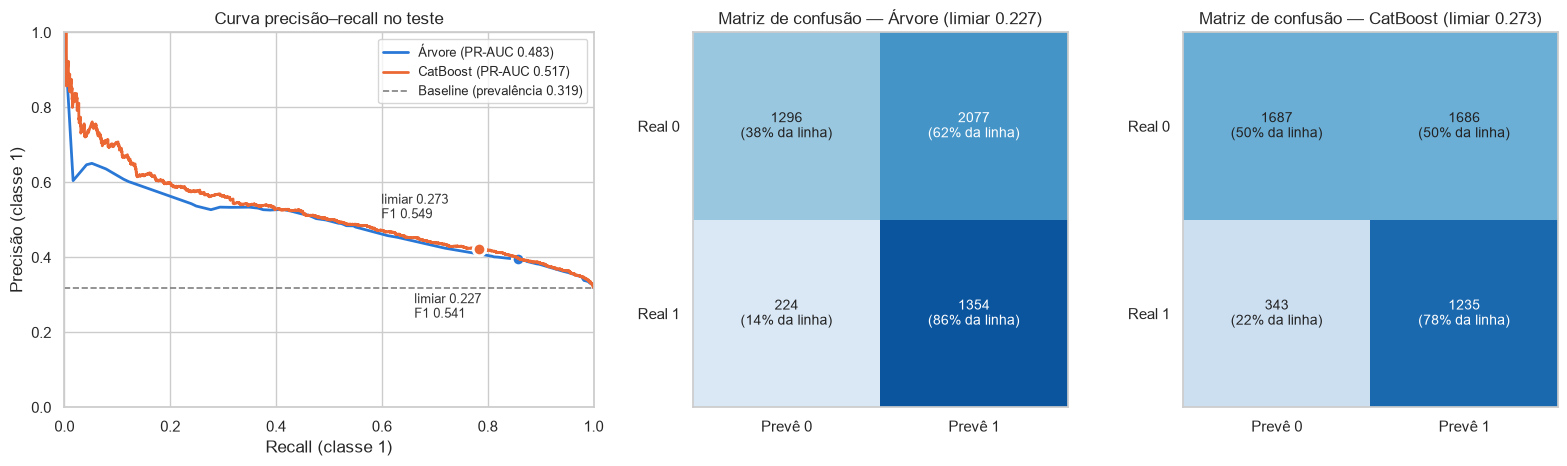

In [80]:
# Curvas precisão–recall no teste (com o ponto de operação de cada limiar) e matrizes de confusão
CORES_F12 = {"Árvore": "#2a78d6", "CatBoost": "#eb6834"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.3, 1, 1]})
ax = axes[0]
for n, cor in CORES_F12.items():
    prec, rec, _ = precision_recall_curve(y_te, proba_teste[n])
    ax.plot(rec, prec, color=cor, lw=2, label=f"{n} (PR-AUC {pontos_f12[n]['PR-AUC']:.3f})")
    ax.plot(pontos_f12[n]["Recall"], pontos_f12[n]["Precisão"], "o", ms=9, color=cor, mec="white", mew=2)
    ax.annotate(f"limiar {LIMIARES_F12[n]:.3f}\nF1 {pontos_f12[n]['F1']:.3f}",
                (pontos_f12[n]["Recall"], pontos_f12[n]["Precisão"]),
                xytext=(-70, 22) if n == "CatBoost" else (-75, -42), textcoords="offset points", fontsize=9, color="#333333")
ax.axhline(y_te.mean(), color="gray", ls="--", lw=1.2, label=f"Baseline (prevalência {y_te.mean():.3f})")
ax.set(xlabel="Recall (classe 1)", ylabel="Precisão (classe 1)", xlim=(0, 1), ylim=(0, 1),
       title="Curva precisão–recall no teste")
ax.legend(loc="upper right", fontsize=9)
for ax, n in zip(axes[1:], CORES_F12):
    cm = confusion_matrix(y_te, pred_teste[n])
    ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for (i, j), v in np.ndenumerate(cm):
        frac = v / cm[i].sum()
        ax.text(j, i, f"{v}\n({frac:.0%} da linha)", ha="center", va="center", fontsize=10,
                color="white" if frac > 0.6 else "#222222")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Prevê 0", "Prevê 1"], yticklabels=["Real 0", "Real 1"],
           title=f"Matriz de confusão — {n} (limiar {LIMIARES_F12[n]:.3f})")
    ax.grid(False)
plt.tight_layout()
plt.show()

**Leitura da avaliação única no teste:**

- **O limiar é estável:** no treino inteiro ficou em 0,227 (árvore) e 0,273 (CatBoost), praticamente igual à média das 5 dobras (0,232 e 0,273).
- **A validação cruzada não foi otimista:** o F1 no teste coincide com o da validação:
  - CatBoost: 0,549 no teste e 0,549 na validação;
  - árvore: 0,541 no teste e 0,542 na validação.

  Como todas as escolhas foram feitas só no treino, essa concordância indica que a estimativa da validação vale para dados nunca vistos.
- **Critério de sucesso da Fase 6 atingido:** o CatBoost tem F1 = 0,549, com IC 95% de [0,532; 0,566]. O intervalo inteiro fica acima de 0,50 e bem acima do baseline (0,312).
- **CatBoost × árvore no teste:**
  - **PR-AUC:** +0,034 [+0,022; +0,046]. O CatBoost ordena melhor os respondentes, e a curva laranja fica acima da azul em quase toda a faixa de recall.
  - **F1:** +0,008, mas o IC de [−0,001; +0,017] encosta no zero (a diferença é positiva em 97% das reamostras). Só com o teste, a vantagem em F1 seria marginal. Ela repete a da validação (+0,007), e o teste não muda a escolha, que já estava feita.
  - **McNemar** (p < 0,001; 441 linhas em que só o CatBoost acerta, 169 em que só a árvore acerta):
    - mede acurácia, não F1;
    - como o limiar da árvore é mais baixo, ela marca mais positivos e erra mais na classe 0 (2.077 falsos positivos, contra 1.686 do CatBoost);
    - por isso favorece o CatBoost mais do que o F1, e entra só como complemento.
- **Leitura de negócio (matriz do CatBoost):**
  - **Recall:** de cada 100 adotantes reais, o modelo encontra 78.
  - **Precisão:** de cada 100 desenvolvedores que ele aponta como prováveis adotantes, 42 de fato adotam. Escolhendo ao acaso, seriam 32 (a prevalência).
  - **Falsos positivos:** metade dos não adotantes é apontada por engano. A Fase 6 aceitou esse custo porque o erro caro é o falso negativo.
- **Limite do desempenho:** ROC-AUC de cerca de 0,70 e PR-AUC de cerca de 0,52 indicam poder preditivo **moderado**. Com 9 preditores de perfil e de percepção, a adoção de agentes é previsível só em parte. A Seção R.3 mostrou que, sem `AIAcc` e `AIComplex`, o F1 cai cerca de 0,07 e fica abaixo da meta. A Fase 13 vai detalhar essa dependência.

### 12.4 Registro da Fase 12

In [81]:
# Registro da Fase 12 no Quadro de Descarte e no Quadro de Decisões
cv_txt = {n: media_dp(RES_CV_F12[n]["test_F1 | ajustado"]) for n in RES_CV_F12}
teste_txt = {n: com_ic(pontos_f12[n]["F1"], boot_f12[n]["F1"]) for n in MODELOS_F12}
dif_f1 = dif_teste_f12[(dif_teste_f12["Comparação"] == "CatBoost  −  Árvore") & (dif_teste_f12["Métrica"] == "F1")].iloc[0]
registrar_auditoria("Fase 12", "Modelo final", MODELO_FINAL,
                    f"Escolhido no treino: F1 {cv_txt['CatBoost']} × {cv_txt['Árvore']} (árvore), Δ = {D_F1_CV:+.4f}, "
                    f"Nadeau-Bengio {p_frase(P_F1_CV)}. Teste (avaliação única): F1 {teste_txt[MODELO_FINAL]}.")
registrar_auditoria("Fase 12", "Árvore de Decisão", "Mantida como referência interpretável",
                    f"F1 no teste {teste_txt['Árvore']}; Δ CatBoost − árvore = {dif_f1['Δ no teste']:+.4f} "
                    f"{dif_f1['IC 95% (bootstrap pareado)']}.")
LINHAS_QUADRO_F12 = [
    {"Fase": "12", "Decisão": "Modelo final",
     "Alternativas testadas": f"{BASELINE} × Árvore (Fase 11) × CatBoost (Seção 11.6), mesmas 5 dobras",
     "Evidência": (f"Validação: F1 {cv_txt['CatBoost']} (CatBoost) × {cv_txt['Árvore']} (árvore) × {cv_txt[BASELINE]} "
                   f"(baseline); CatBoost − árvore {p_frase(P_F1_CV)}"),
     "Escolha final": f"{MODELO_FINAL} (regra fixada antes de abrir o teste)"},
    {"Fase": "12", "Decisão": "Avaliação única no teste",
     "Alternativas testadas": "— (o teste só mede; não muda nenhuma escolha)",
     "Evidência": (f"F1 no teste: CatBoost {teste_txt['CatBoost']}, árvore {teste_txt['Árvore']}, baseline "
                   f"{teste_txt[BASELINE]}; Δ CatBoost − árvore {dif_f1['Δ no teste']:+.4f} {dif_f1['IC 95% (bootstrap pareado)']}; "
                   f"McNemar {p_frase(res_mcnemar.pvalue)}"),
     "Escolha final": f"Desempenho esperado em dados novos: F1 ≈ {f1_final:.2f} ({MODELO_FINAL})"},
]
print("Fase 12 registrada:", [l["Decisão"] for l in LINHAS_QUADRO_F12])

Fase 12 registrada: ['Modelo final', 'Avaliação única no teste']


---
## Quadro de Decisões de Modelagem (Fases 8 a 12 e revisão do conjunto)

Uma linha por decisão relevante, com as alternativas testadas e a evidência. Todos os números vêm das células acima ("No Alien Artifacts"). As linhas da revisão do conjunto e da busca do CatBoost vêm das seções anteriores; as da Fase 12, da Seção 12.4.

In [82]:
def f1_txt(res, chave="test_F1 (classe 1)"):
    return media_dp(res[chave])

def p_de(tabela, modelo, comparacao):
    return tabela.loc[(tabela["Modelo"] == modelo) & (tabela["Comparação de F1"] == comparacao), "p-valor"].iloc[0]

r_imp = res_imputacao
quadro_decisoes = pd.DataFrame([
    {"Fase": "Seção 3", "Decisão": "Filtros das Fases 3 e 4 refeitos só no treino",
     "Alternativas testadas": "Seleção da Etapa 1 (base inteira) × seleção só no treino",
     "Evidência": f"Mesmas 9 variáveis significativas; mesmas remoções por VIF ({', '.join(removidas_agora)})",
     "Escolha final": "Mantida a seleção da Etapa 1 (nenhuma variável mudou de status)"},
    {"Fase": "8", "Decisão": "Escala na árvore",
     "Alternativas testadas": "Com z-score × sem z-score",
     "Evidência": f"F1 idêntico nas 5 dobras (diferença máxima {np.abs(f1_com_z - f1_sem_z).max():.4f})",
     "Escolha final": "Sem z-score (desnecessário para árvores)"},
    {"Fase": "8", "Decisão": "Categóricas no CatBoost",
     "Alternativas testadas": "Dummies/target encoding × categóricas nativas",
     "Evidência": "7 dos 9 preditores são categóricos; codificação ordenada evita vazamento",
     "Escolha final": "Categóricas nativas, como texto"},
    {"Fase": "9", "Decisão": "Imputação na árvore",
     "Alternativas testadas": "A: isBAD/'missing'; B: mediana/moda; C: KNN",
     "Evidência": (f"F1 A {f1_txt(r_imp[('Árvore', 'isbad')])}, B {f1_txt(r_imp[('Árvore', 'simples')])}, "
                   f"C {f1_txt(r_imp[('Árvore', 'knn')])}; Nadeau-Bengio p = "
                   f"{p_de(teste_imputacao, 'Árvore', 'A − B')} (A×B) e {p_de(teste_imputacao, 'Árvore', 'A − C')} (A×C)"),
     "Escolha final": "A (isBAD): empate estatístico, preserva a ausência informativa, padrão do curso"},
    {"Fase": "9", "Decisão": "Imputação no CatBoost",
     "Alternativas testadas": "Nativa (NaN/'missing') × mediana/moda",
     "Evidência": (f"F1 {f1_txt(r_imp[('CatBoost', 'nativa')])} × {f1_txt(r_imp[('CatBoost', 'simples')])}; "
                   f"p = {p_de(teste_imputacao, 'CatBoost', 'N − B')}"),
     "Escolha final": "Nativa (mais simples, sem etapa de imputação)"},
    {"Fase": "9", "Decisão": "Dados sintéticos",
     "Alternativas testadas": "Gerar × não gerar",
     "Evidência": "Problema é valor faltando em registros reais; classe positiva não é rara (31,9%); base grande",
     "Escolha final": "Não gerar"},
    {"Fase": "10", "Decisão": "Desbalanceamento",
     "Alternativas testadas": "Nível 0; nível 1 (peso); nível 2 (limiar); níveis 1 + 2",
     "Evidência": (f"F1 árvore: {' / '.join(media_dp(escores_desbal[('Árvore', n)]['F1']) for n in ORDEM_NIVEIS)}; "
                   f"CatBoost: {' / '.join(media_dp(escores_desbal[('CatBoost', n)]['F1']) for n in ORDEM_NIVEIS)}"),
     "Escolha final": f"{ESTRATEGIA_DESBAL} (ver Seção 10.4)"},
    {"Fase": "10", "Decisão": "Reamostragem sintética (SMOTE)",
     "Alternativas testadas": "Não testada",
     "Evidência": "Peso de classe e limiar já superam o nível 0 com p < 0,001 e a meta de F1 > 0,50",
     "Escolha final": "Não aplicar (roteiro 7.3: primeiro as alternativas que não criam dados)"},
])
quadro_decisoes = pd.concat([quadro_decisoes, pd.DataFrame(LINHAS_QUADRO_F11), pd.DataFrame(LINHAS_QUADRO_REV),
                             pd.DataFrame(LINHAS_QUADRO_F11_CB), pd.DataFrame(LINHAS_QUADRO_F12)],
                            ignore_index=True)
with pd.option_context("display.max_colwidth", 140):
    display(quadro_decisoes)

,Fase,Decisão,Alternativas testadas,Evidência,Escolha final
0,Seção 3,Filtros das Fases 3 e 4 refeitos só no treino,Seleção da Etapa 1 (base inteira) × seleção só no treino,"Mesmas 9 variáveis significativas; mesmas remoções por VIF (RemoteWork_missing, OrgSize_missing, WorkExp_z)",Mantida a seleção da Etapa 1 (nenhuma variável mudou de status)
1,8,Escala na árvore,Com z-score × sem z-score,F1 idêntico nas 5 dobras (diferença máxima 0.0000),Sem z-score (desnecessário para árvores)
2,8,Categóricas no CatBoost,Dummies/target encoding × categóricas nativas,7 dos 9 preditores são categóricos; codificação ordenada evita vazamento,"Categóricas nativas, como texto"
3,9,Imputação na árvore,A: isBAD/'missing'; B: mediana/moda; C: KNN,"F1 A 0.543 ± 0.011, B 0.547 ± 0.012, C 0.543 ± 0.009; Nadeau-Bengio p = 0.464 (A×B) e 0.829 (A×C)","A (isBAD): empate estatístico, preserva a ausência informativa, padrão do curso"
4,9,Imputação no CatBoost,Nativa (NaN/'missing') × mediana/moda,F1 0.553 ± 0.005 × 0.553 ± 0.004; p = 0.903,"Nativa (mais simples, sem etapa de imputação)"
5,9,Dados sintéticos,Gerar × não gerar,"Problema é valor faltando em registros reais; classe positiva não é rara (31,9%); base grande",Não gerar
6,10,Desbalanceamento,Nível 0; nível 1 (peso); nível 2 (limiar); níveis 1 + 2,F1 árvore: 0.186 ± 0.049 / 0.543 ± 0.011 / 0.554 ± 0.004 / 0.554 ± 0.004; CatBoost: 0.347 ± 0.021 / 0.553 ± 0.005 / 0.561 ± 0.002 / 0.55...,Nível 2: ajuste do limiar (ver Seção 10.4)
7,10,Reamostragem sintética (SMOTE),Não testada,"Peso de classe e limiar já superam o nível 0 com p < 0,001 e a meta de F1 > 0,50",Não aplicar (roteiro 7.3: primeiro as alternativas que não criam dados)
8,11,Hiperparâmetros da árvore,"Grade de 210 combinações (max_depth, min_samples_leaf, ccp_alpha, criterion)","Melhor F1 0.558 ± 0.003, gap 0.005; contra a configuração fixa Δ = +0.0038 (p = 0.36); curva de max_depth plana a partir de 2","ccp_alpha=0.0001, criterion=entropy, max_depth=8, min_samples_leaf=100 (melhor F1; a regra de 1 desvio-padrão foi considerada e não adot..."
9,11,Método de busca do CatBoost,(a) PR-AUC e limiar ajustado no fim; (b) F1 com limiar ajustado por dentro,(b) custa cerca de 4 vezes mais por candidato; a PR-AUC não depende do limiar (Fase 10),(a) na busca ampla e (b) na grade final pequena


## Quadro de Descarte estendido (Bloco B)

Continuação da trilha de auditoria da Etapa 1 (`audit_trail`), com os registros acrescentados pelas Fases 8 a 12 e pela revisão do conjunto de preditores.

In [83]:
audit_trail_df = pd.DataFrame(audit_trail)
bloco_b = audit_trail_df[audit_trail_df["Fase"].isin(["Bloco B (Seção 3)", "Fase 8", "Fase 9", "Fase 10", "Fase 11", "Revisão do conjunto", "Fase 12"])]
print(f"Quadro de Descarte estendido: {len(audit_trail_df)} registros no total; {len(bloco_b)} novos no Bloco B.")
with pd.option_context("display.max_rows", None, "display.max_colwidth", 110):
    display(bloco_b)

Quadro de Descarte estendido: 91 registros no total; 28 novos no Bloco B.


,Fase,Variável,Status,Justificativa
63,Bloco B (Seção 3),Filtros das Fases 3 e 4,Refeitos só no treino,Testes bivariados e VIF iterativo recalculados no treino: nenhuma variável mudou de status.
64,Fase 8,Árvore: escala,Z-score retirado,Árvores são invariantes a transformações monotônicas; F1 idêntico com e sem z-score nas 5 dobras.
65,Fase 8,Árvore: outliers,Mantido (3xIQR -> NA + isBAD),Não por sensibilidade do modelo: os valores cortados (YearsCode > 70 anos) são implausíveis.
66,Fase 8,CatBoost: categóricas,Texto nativo (sem dummies/TE),"Codificação ordenada pelo alvo feita pelo próprio modelo, sem vazamento."
67,Fase 8,DevType (níveis raros),Sem agrupamento manual,Target encoding suavizado (árvore) e estatística ordenada com prior (CatBoost) puxam níveis raros para a m...
68,Fase 8,Categorias novas no teste,Tratadas nos dois pipelines,Árvore: dummies zeradas e TE = média global; CatBoost: categoria desconhecida aceita.
69,Fase 8,Novos atributos,Nenhum criado,As curvas LOESS mostraram mudanças de inclinação que árvores aprendem sozinhas com pontos de corte.
70,Fase 9,Imputação (árvore),A: mediana + isBAD / 'missing',Sem diferença significativa contra B e C (Nadeau-Bengio); isBAD preserva a ausência informativa.
71,Fase 9,Imputação (CatBoost),Nativa: NaN / 'missing',Sem diferença significativa contra mediana/moda; dispensa etapa de imputação.
72,Fase 9,Dados sintéticos,Não gerados,"O problema é valor faltando (imputação), não classe rara nem base pequena/sensível."


## Reprodutibilidade

Sementes fixas (`RNG_SEED = 42` em todos os `random_state`/`random_seed`) e versões das bibliotecas usadas nesta execução:

In [84]:
import sys, sklearn, scipy, statsmodels, catboost, matplotlib, seaborn
print("Python", sys.version.split()[0])
for lib in [pd, np, sklearn, scipy, statsmodels, catboost, matplotlib, seaborn]:
    print(f"{lib.__name__:<12} {lib.__version__}")

Python 3.12.10
pandas       3.0.5
numpy        2.5.0
sklearn      1.9.1
scipy        1.18.0
statsmodels  0.15.0
catboost     1.2.10
matplotlib   3.11.0
seaborn      0.13.2


---
### Próximos passos

- **Fase 13:** explicabilidade do CatBoost final (com a árvore como referência interpretável), incluindo a dependência do modelo em relação a `AIAcc` e `AIComplex` (Seção R.3).
- **Fase 14:** conclusão e relatório executivo.
- *(Opcional)* validação cruzada aninhada.